# Clusterização de imagens de fundo de olho a partir de embeddings de um extrator neural leve

## Retinopatia diabética: APTOS 2019 e FDR26

Este notebook investiga se um modelo neural leve, usado como extrator de características, organiza imagens de fundo de olho em grupos com significado. Cada imagem vira um vetor numérico (o embedding), retirado da última camada escondida da rede, antes da camada de classificação. Empilhando os vetores de todas as imagens, obtemos uma matriz de características, que é a entrada dos algoritmos de clusterização. Depois testamos vários números de grupos e analisamos o que cada grupo tem em comum.

A pergunta central é simples de formular: quando a rede junta imagens parecidas, ela junta pela gravidade da doença, pela base (e portanto pela câmera e pelo protocolo de aquisição) ou pela qualidade da foto?

Duas bases públicas são usadas nesta versão:

| Base | Origem | Imagens rotuladas | Escala de gravidade |
|---|---|---|---|
| APTOS 2019 | Aravind Eye Hospital, Índia, competição Kaggle | 3.662 | 5 graus, padrão ICDR |
| FDR26 | Hospital Universitário Mohammed VI, Oujda, Marrocos | 3.000 | 5 estágios, padrão ALFEDIAM |

## Objetivo e pedidos atendidos

| Pedido | Onde está |
|---|---|
| 1. Utilizar ou desenvolver um modelo neural leve que funcione como extrator de características | Seção 6: MobileNetV3-Small em duas versões, só com pesos da ImageNet e ajustada nas imagens de retina |
| 2. Aproveitar as ativações da última camada escondida, antes da classificação, para gerar embeddings | Seção 6: a camada escondida de 1.024 neurônios que antecede a classificação |
| 3. Construir a matriz de características, com um vetor por imagem | Seção 7: uma linha por imagem e 1.024 colunas, uma matriz para cada extrator |
| 4. Usar a matriz como entrada para algoritmos de clusterização | Seções 8 e 9: K-Means, mistura de gaussianas, Ward e HDBSCAN |
| 5. Experimentar diferentes quantidades de agrupamentos (K = 2, 3, 4, 5...) | Seção 8: K de 2 a 8, com indicadores internos, externos e de estabilidade |
| 6. Extrair e analisar estatísticas das imagens e dos clusters | Seções 1 a 4 (imagens) e Seções 10 e 11 (clusters) |

Antes das seções numeradas vêm o estado da arte e o desenho do estudo. Roteiro:

0. Configuração do ambiente
1. Catálogos e metadados
2. As imagens: galeria e análise técnica
3. Pré-processamento
4. Medidas das imagens, duplicatas e vasos
5. Divisão treino e teste por paciente
6. O extrator leve
7. A matriz de características
8. Clusterização com K = 2 a 8
9. Comparação entre algoritmos
10. Visualização dos clusters
11. Estatísticas das imagens e dos clusters
12. Conclusões, limitações e próximos passos
13. Referências

## Estado da arte

### Retinopatia diabética e escalas de gravidade

A retinopatia diabética (RD) é uma complicação microvascular do diabetes e uma das principais causas de perda visual evitável em adultos. A escala internacional ICDR divide a doença em cinco níveis [1]: 0 sem RD; 1 não proliferativa leve, apenas com microaneurismas; 2 não proliferativa moderada; 3 não proliferativa grave, definida pela regra 4-2-1 (hemorragias nos quatro quadrantes, rosário venoso em dois ou anomalias microvasculares em um); e 4 proliferativa, com neovasos ou hemorragia vítrea.

Na prática de rastreamento, o limiar que mais importa é o da RD referável, isto é, moderada ou pior (grau 2 ou mais), que exige encaminhamento ao oftalmologista. Esse é o desfecho usado nos estudos de referência de aprendizado profundo para RD [2]. Neste notebook, ele aparece como o alvo binário referável.

A escala ALFEDIAM, usada nos países francófonos e base da classificação do FDR26, deriva de uma simplificação da escala ETDRS e foi atualizada no referencial conjunto da Sociedade Francófona de Diabetes e da Sociedade Francesa de Oftalmologia [3]. Os cinco estágios do FDR26 (pas de RD, minime, modérée, sévère e proliférante) correspondem, de forma aproximada, aos cinco níveis da ICDR. A correspondência não é oficial, e por isso ela é tratada como uma ressalva ao longo da análise.

### APTOS 2019

O APTOS 2019 foi publicado na competição Kaggle da Asia Pacific Tele-Ophthalmology Society, com imagens do Aravind Eye Hospital coletadas em várias clínicas, com câmeras diferentes e ao longo de anos [4]. Os 3.662 exames de treino têm rótulo de 0 a 4. A métrica oficial foi o kappa ponderado quadrático (QWK). As melhores soluções chegaram a cerca de 0,93 de QWK no placar privado [4,5]. Tymchenko et al. chegaram a 0,925, o 54º lugar entre 2.943 equipes [5].

O APTOS também é um dos benchmarks de RD dos modelos de fundação de retina. O RETFound, um Vision Transformer grande pré-treinado de forma auto-supervisionada em cerca de 1,6 milhão de imagens de retina, usa o APTOS 2019 para medir a gradação de RD [6]. A análise anterior do grupo (projeto OIO+) mostrou dois problemas conhecidos da base: imagens repetidas com rótulos conflitantes e resoluções muito heterogêneas.

### FDR26

O FDR26 foi publicado no Zenodo em 2026 [7]. São 3.000 imagens de pacientes diabéticos e não diabéticos do serviço de oftalmologia do Hospital Universitário Mohammed VI, em Oujda, Marrocos, graduadas por oftalmologistas na escala ALFEDIAM. O catálogo traz sexo, idade e tipo de diabetes de cada paciente. A base também inclui máscaras de segmentação de vasos, que vieram de uma publicação anterior e foram incorporadas como camada complementar de anotação. Nas buscas que fizemos, não encontramos benchmark de classificação revisado por pares para o FDR26. Os resultados aqui devem ser lidos como uma análise exploratória da base.

### Extratores leves e embeddings

A MobileNetV3 foi desenhada por busca automática de arquitetura para rodar em celulares, e a versão Small tem cerca de 2,5 milhões de parâmetros [8]. A família EfficientNet, dominante nas soluções do APTOS, segue a mesma ideia de eficiência por escalonamento composto [9]. As camadas intermediárias de uma rede treinada na ImageNet são gerais e transferíveis para outras tarefas [10], e a qualidade dessa transferência cresce com a qualidade do modelo, mas o ajuste fino continua importante em domínios distantes da ImageNet, como o médico [11]. A ativação da penúltima camada, logo antes da classificação, é a representação padrão usada como embedding.

### Clusterização de representações profundas

O DeepCluster mostrou que o K-Means aplicado a características de redes convolucionais organiza conceitos visuais sem rótulos [12]. Em imagens médicas, agrupar embeddings é uma forma de descobrir estratificação oculta, isto é, subgrupos não rotulados em que um modelo falha [13]. Outro risco conhecido é o aprendizado por atalho: a rede pode usar pistas de aquisição, como câmera, bordas e iluminação, em vez da doença [14]. Clusters que acompanham a base de origem são um sinal desse risco.

Partições do espaço de características também são a base de métodos que roteiam cada amostra para um modelo especializado, como o clustering-and-selection [15] e a mistura de especialistas [16]. Essa é a motivação de longo prazo do projeto: um roteador leve que escolhe, para cada região do espaço, o melhor modelo de um conjunto.

### Lacuna e contribuição

Nas buscas que fizemos, não encontramos estudos que combinem APTOS 2019 e FDR26. Este notebook descreve as duas bases lado a lado, mede o quanto elas diferem nas imagens, e compara a estrutura de clusters produzida por um extrator leve antes e depois do ajuste fino nas imagens de retina.

## Desenho do estudo

Resumo dos métodos, na ordem em que aparecem:

| Etapa | Método |
|---|---|
| Pré-processamento | máscara do campo de visão por limiar, recorte da retina, redimensionamento com preservação da proporção e quadrado de 224 × 224 pixels. CLAHE [17] apenas nas medidas de estruturas |
| Extrator | MobileNetV3-Small [8] em PyTorch [18]: pesos da ImageNet e versão ajustada com AdamW [19] |
| Avaliação do extrator ajustado | kappa ponderado quadrático [20], acurácia e AUC de RD referável |
| Matriz de características | normalização L2, padronização e análise de componentes principais [21], aprendidas só no treino |
| Clusterização | K-Means [22] com inicialização k-means++ [23], mistura de gaussianas por EM [24], Ward [25] e HDBSCAN [26] |
| Indicadores internos | silhouette [27], Davies-Bouldin [28] e Calinski-Harabasz [29], além da estabilidade por subamostragem |
| Indicadores externos | ARI [30] e NMI [31] contra grau, RD referável e base de origem |
| Visualização | UMAP [32] e mosaicos de imagens por cluster |
| Estatística das imagens | Kruskal-Wallis [33] com tamanho de efeito η² [34] e V de Cramér [35] |
| Bibliotecas | scikit-learn [36], PyTorch [18], OpenCV, pandas e seaborn |

Três cuidados valem para todo o notebook:

- A divisão treino e teste é feita por paciente. No FDR26, um mesmo paciente tem até 8 imagens, e manter as imagens dele dos dois lados deixaria o teste otimista.
- Tudo o que é aprendido (o ajuste fino da rede, a normalização, o PCA e o K-Means) usa só o treino. As imagens de teste apenas recebem um cluster.
- Os indicadores externos dos clusters (ARI e NMI) são medidos no teste, em imagens que nem a rede ajustada nem o K-Means viram.

## 0. Configuração do ambiente

As bibliotecas usadas no notebook. O ambiente recomendado é o .venv do projeto, com o requirements.txt instalado.

In [1]:
import hashlib
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import umap
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.colors import to_rgb
from matplotlib.gridspec import GridSpec
from PIL import Image
from scipy import stats
from sklearn.cluster import HDBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    calinski_harabasz_score,
    cohen_kappa_score,
    confusion_matrix,
    davies_bouldin_score,
    normalized_mutual_info_score,
    roc_auc_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from torch import nn
from torchvision import models

warnings.filterwarnings("ignore", category=UserWarning, module="umap")
warnings.filterwarnings("ignore", category=FutureWarning)

print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "não disponível")

PyTorch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


Todos os parâmetros do experimento ficam na classe Config. Para mudar algo, basta criar o objeto com outro valor, por exemplo Config(k_analise=5).

| Parâmetro | Papel |
|---|---|
| semente | fixa a aleatoriedade, para repetir os resultados |
| fracao_teste | fração dos pacientes reservada para teste |
| limiar_referavel | grau a partir do qual a RD é referável |
| tamanho_imagem | lado do quadrado que entra na rede |
| lado_medidas | lado máximo usado no cálculo das medidas das imagens |
| epocas_ajuste, taxa_aprendizado, tamanho_lote | treino do extrator ajustado |
| n_componentes_pca | dimensões mantidas antes da clusterização |
| lista_k | quantidades de clusters testadas |
| k_analise | K usado na análise detalhada |
| repeticoes_estabilidade | repetições do teste de estabilidade |
| n_jobs | processos paralelos na leitura das imagens |

In [2]:
@dataclass(frozen=True)
class Config:
    semente: int = 42
    fracao_teste: float = 0.25
    limiar_referavel: int = 2
    tamanho_imagem: int = 224
    lado_medidas: int = 512
    epocas_ajuste: int = 15
    taxa_aprendizado: float = 5e-4
    tamanho_lote: int = 64
    n_componentes_pca: int = 50
    lista_k: tuple = (2, 3, 4, 5, 6, 7, 8)
    k_analise: int = 4
    repeticoes_estabilidade: int = 10
    n_jobs: int = 6


CFG = Config()
np.random.seed(CFG.semente)
torch.manual_seed(CFG.semente)
CFG

Config(semente=42, fracao_teste=0.25, limiar_referavel=2, tamanho_imagem=224, lado_medidas=512, epocas_ajuste=15, taxa_aprendizado=0.0005, tamanho_lote=64, n_componentes_pca=50, lista_k=(2, 3, 4, 5, 6, 7, 8), k_analise=4, repeticoes_estabilidade=10, n_jobs=6)

O notebook localiza a raiz do projeto subindo as pastas até encontrar data/catalogs. Imagens ficam em data/raw, catálogos em data/catalogs, e figuras, tabelas e caches em results/clustering.

In [3]:
@dataclass(frozen=True)
class Caminhos:
    raiz: Path
    catalogos: Path
    imagens: dict
    mascaras_vasos: Path
    saida: Path
    figuras: Path
    cache: Path


def localizar_raiz(inicio=None):
    inicio = (inicio or Path.cwd()).resolve()
    for pasta in [inicio, *inicio.parents]:
        if (pasta / "data" / "catalogs").is_dir():
            return pasta
    raise FileNotFoundError(f"Pasta data/catalogs não encontrada acima de {inicio}")


def montar_caminhos(raiz):
    saida = raiz / "results" / "clustering"
    caminhos = Caminhos(
        raiz=raiz,
        catalogos=raiz / "data" / "catalogs",
        imagens={
            "APTOS_2019": raiz / "data" / "raw" / "aptos" / "train",
            "FDR26": raiz / "data" / "raw" / "fdr26" / "Fundus_FDR26",
        },
        mascaras_vasos=raiz / "data" / "raw" / "fdr26" / "vessels_FDR26",
        saida=saida,
        figuras=saida / "figuras",
        cache=saida / "cache",
    )
    for pasta in (caminhos.saida, caminhos.figuras, caminhos.cache):
        pasta.mkdir(parents=True, exist_ok=True)
    return caminhos


CAMINHOS = montar_caminhos(localizar_raiz())

pd.DataFrame(
    [
        ("raiz do projeto", CAMINHOS.raiz),
        ("catálogos", CAMINHOS.catalogos),
        ("imagens APTOS 2019", CAMINHOS.imagens["APTOS_2019"]),
        ("imagens FDR26", CAMINHOS.imagens["FDR26"]),
        ("máscaras de vasos FDR26", CAMINHOS.mascaras_vasos),
        ("resultados", CAMINHOS.saida),
    ],
    columns=["item", "caminho"],
).assign(existe=lambda t: t["caminho"].map(Path.exists))

,item,caminho,existe
0,raiz do projeto,/home/ari/dr-statistical-analysis,True
1,catálogos,/home/ari/dr-statistical-analysis/data/catalogs,True
2,imagens APTOS 2019,/home/ari/dr-statistical-analysis/data/raw/apt...,True
3,imagens FDR26,/home/ari/dr-statistical-analysis/data/raw/fdr...,True
4,máscaras de vasos FDR26,/home/ari/dr-statistical-analysis/data/raw/fdr...,True
5,resultados,/home/ari/dr-statistical-analysis/results/clus...,True


Padrões visuais usados em todas as figuras: uma cor fixa por base, uma escala de azul (saudável) a vermelho (proliferativa) para os graus e uma paleta categórica para os clusters. Toda figura também é salva em results/clustering/figuras.

In [4]:
NOMES_GRAUS = {0: "Sem RD", 1: "RD leve", 2: "RD moderada", 3: "RD grave", 4: "RD proliferativa"}
BASES = ("APTOS_2019", "FDR26")
EXTRATORES = ("ImageNet", "Ajustado")
CORES_BASE = {"APTOS_2019": "#3B6FB6", "FDR26": "#D9822B"}
CORES_GRAU = dict(zip(range(5), ["#2C7BB6", "#8CC5DE", "#F2C14E", "#F07C3E", "#B2182B"]))
CORES_EXTRATOR = {"ImageNet": "#7A7A7A", "Ajustado": "#1B9E77"}
PALETA_CLUSTERS = sns.color_palette("tab10", 10)

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "font.size": 10,
})
sns.set_style("whitegrid", {"axes.spines.top": False, "axes.spines.right": False})


def salvar_figura(fig, nome):
    fig.savefig(CAMINHOS.figuras / f"{nome}.png", bbox_inches="tight")
    plt.show()


def nome_cluster(r):
    return f"C{int(r) + 1}"

## 1. Catálogos e metadados

Os catálogos de data/catalogs foram gerados pelo script scripts/build_catalogs.py a partir dos metadados originais (train.csv do APTOS e metadata_classification_DR.xlsx do FDR26). As duas bases têm as mesmas quatro colunas principais:

| Coluna | Conteúdo |
|---|---|
| dataset | nome da base |
| arquivo | nome do arquivo da imagem |
| codigo_diagnostico | grau de RD, de 0 a 4 |
| grupo | identificador do paciente, usado na divisão treino e teste |

O FDR26 traz ainda grade_dr (o texto original do estágio ALFEDIAM), sexe, idade e tipo_diabete.

### 1.1 Leitura dos catálogos

In [5]:
ARQUIVOS_CATALOGO = {"APTOS_2019": "aptos_metadata.csv", "FDR26": "fdr26_metadata.csv"}


def ler_catalogo(base):
    tabela = pd.read_csv(CAMINHOS.catalogos / ARQUIVOS_CATALOGO[base])
    return tabela.assign(grau=tabela["codigo_diagnostico"].astype(int))


TABELAS = {base: ler_catalogo(base) for base in BASES}
display(TABELAS["APTOS_2019"].head())
display(TABELAS["FDR26"].head())

,dataset,arquivo,codigo_diagnostico,grupo,grau
0,APTOS_2019,000c1434d8d7.png,2,APTOS_2019_000c1434d8d7,2
1,APTOS_2019,001639a390f0.png,4,APTOS_2019_001639a390f0,4
2,APTOS_2019,0024cdab0c1e.png,1,APTOS_2019_0024cdab0c1e,1
3,APTOS_2019,002c21358ce6.png,0,APTOS_2019_002c21358ce6,0
4,APTOS_2019,005b95c28852.png,0,APTOS_2019_005b95c28852,0


,dataset,arquivo,codigo_diagnostico,grupo,grade_dr,sexe,idade,tipo_diabete,grau
0,FDR26,WAJHZX6C01.jpg,0,FDR26_WAJHZX6C,DR0 - Pas de RD,M,58,2,0
1,FDR26,T9NT4V5U01.jpg,0,FDR26_T9NT4V5U,DR0 - Pas de RD,M,56,2,0
2,FDR26,T9NT4V5U02.jpg,0,FDR26_T9NT4V5U,DR0 - Pas de RD,M,56,2,0
3,FDR26,2T2SALA701.jpg,0,FDR26_2T2SALA7,DR0 - Pas de RD,M,44,2,0
4,FDR26,2T2SALA702.jpg,0,FDR26_2T2SALA7,DR0 - Pas de RD,M,44,2,0


### 1.2 Estrutura geral

Contagem de registros, valores ausentes, arquivos repetidos e pacientes distintos em cada base.

In [6]:
def resumo_estrutural(tabela):
    imagens_por_paciente = tabela["grupo"].value_counts()
    return pd.Series({
        "registros": len(tabela),
        "colunas": tabela.shape[1],
        "valores ausentes": int(tabela.isna().sum().sum()),
        "nomes de arquivo repetidos": int(tabela["arquivo"].duplicated().sum()),
        "pacientes distintos": tabela["grupo"].nunique(),
        "máximo de imagens por paciente": int(imagens_por_paciente.max()),
    })


pd.DataFrame({base: resumo_estrutural(TABELAS[base]) for base in BASES})

,APTOS_2019,FDR26
registros,3662,3000
colunas,5,9
valores ausentes,0,0
nomes de arquivo repetidos,0,0
pacientes distintos,3662,1918
máximo de imagens por paciente,1,8


O APTOS 2019 tem 3.662 registros e o FDR26, 3.000, sem valores ausentes e sem nomes de arquivo repetidos. A diferença importante está na relação entre imagens e pacientes. No APTOS, o catálogo não identifica o paciente, e cada imagem é tratada como um paciente diferente. No FDR26, as 3.000 imagens vêm de 1.918 pacientes, com até 8 imagens por pessoa. Essa estrutura muda a forma correta de dividir treino e teste (Seção 5).

### 1.3 Correspondência entre as escalas

O FDR26 informa o estágio pelo texto da ALFEDIAM. A tabela mostra como cada código foi lido e qual nível da ICDR ele representa neste notebook.

In [7]:
(
    TABELAS["FDR26"][["grau", "grade_dr"]]
    .drop_duplicates()
    .sort_values("grau")
    .assign(nivel_icdr_equivalente=lambda t: t["grau"].map(NOMES_GRAUS))
    .rename(columns={"grade_dr": "estagio_alfediam_original"})
    .reset_index(drop=True)
)

,grau,estagio_alfediam_original,nivel_icdr_equivalente
0,0,DR0 - Pas de RD,Sem RD
1,1,DR1 - Minime,RD leve
2,2,DR2 - Moderee,RD moderada
3,3,DR3 - Severe,RD grave
4,4,DR4 - Proliferante,RD proliferativa


Os cinco estágios da ALFEDIAM têm a mesma ordem e a mesma lógica clínica dos cinco níveis da ICDR: minime corresponde à RD leve, modérée à moderada, sévère à grave e proliférante à proliferativa. Por isso os dois rótulos são tratados como uma única variável grau, de 0 a 4. A equivalência é aproximada, porque os critérios de cada estágio foram escritos por comitês diferentes e as imagens foram graduadas por equipes diferentes [1,3]. Diferenças entre as bases no mesmo grau podem vir, em parte, dessa diferença de critério.

### 1.4 Distribuição dos graus

Quantidade e percentual de imagens em cada grau. A última coluna de cada base mostra a proporção de RD referável (grau 2 ou mais).

In [8]:
def distribuicao_graus(tabela):
    contagem = tabela["grau"].value_counts().sort_index()
    return pd.DataFrame({"imagens": contagem, "%": (100 * contagem / contagem.sum()).round(1)})


TAB_GRAUS = pd.concat({base: distribuicao_graus(TABELAS[base]) for base in BASES}, axis=1)
TAB_GRAUS.index = [f"{g} - {NOMES_GRAUS[g]}" for g in TAB_GRAUS.index]
display(TAB_GRAUS)

pd.DataFrame({
    base: {
        "RD referável (grau ≥ 2)": int((TABELAS[base]["grau"] >= CFG.limiar_referavel).sum()),
        "% de RD referável": round(100 * (TABELAS[base]["grau"] >= CFG.limiar_referavel).mean(), 1),
    }
    for base in BASES
})

APTOS_2019         FDR26      
                        imagens     % imagens     %
0 - Sem RD                 1805  49.3     505  16.8
1 - RD leve                 370  10.1     701  23.4
2 - RD moderada             999  27.3     583  19.4
3 - RD grave                193   5.3     632  21.1
4 - RD proliferativa        295   8.1     579  19.3

,APTOS_2019,FDR26
RD referável (grau ≥ 2),1487.0,1794.0
% de RD referável,40.6,59.8


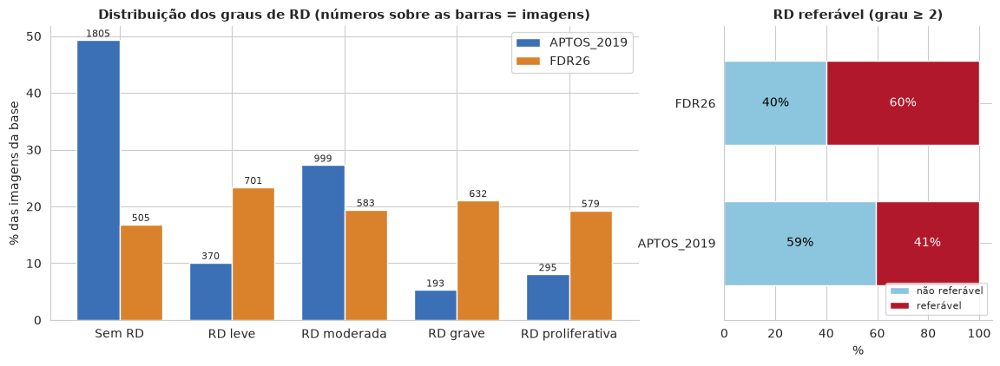

In [9]:
def plotar_distribuicao_graus(tabelas):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
    largura = 0.38
    for i, base in enumerate(BASES):
        contagem = tabelas[base]["grau"].value_counts().sort_index()
        percentual = 100 * contagem / contagem.sum()
        posicoes = np.arange(5) + (i - 0.5) * largura
        barras = eixos[0].bar(posicoes, percentual, largura, color=CORES_BASE[base], label=base)
        for barra, n in zip(barras, contagem):
            eixos[0].text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.6, f"{n}", ha="center", fontsize=8)
    eixos[0].set_xticks(range(5), [NOMES_GRAUS[g] for g in range(5)])
    eixos[0].set_ylabel("% das imagens da base")
    eixos[0].set_title("Distribuição dos graus de RD (números sobre as barras = imagens)")
    eixos[0].legend()
    referavel = pd.DataFrame({
        base: [(tabelas[base]["grau"] < CFG.limiar_referavel).mean(), (tabelas[base]["grau"] >= CFG.limiar_referavel).mean()]
        for base in BASES
    }, index=["não referável", "referável"]).T * 100
    referavel.plot(kind="barh", stacked=True, color=["#8CC5DE", "#B2182B"], ax=eixos[1], width=0.6)
    for j, base in enumerate(BASES):
        eixos[1].text(referavel.loc[base, "não referável"] / 2, j, f"{referavel.loc[base, 'não referável']:.0f}%", va="center", ha="center", color="black")
        eixos[1].text(referavel.loc[base, "não referável"] + referavel.loc[base, "referável"] / 2, j, f"{referavel.loc[base, 'referável']:.0f}%", va="center", ha="center", color="white")
    eixos[1].set_xlabel("%")
    eixos[1].set_title("RD referável (grau ≥ 2)")
    eixos[1].legend(loc="lower right", fontsize=8)
    return fig


salvar_figura(plotar_distribuicao_graus(TABELAS), "01_distribuicao_graus")

As duas bases têm distribuições quase opostas. O APTOS 2019 é dominado por olhos sem RD (49,3%), e os graus grave (5,3%) e proliferativo (8,1%) são raros, um perfil típico de rastreamento. O FDR26 é bem mais equilibrado: nenhum grau passa de 23,4%, e há 632 imagens de RD grave contra 193 no APTOS. Uma explicação possível é a origem hospitalar do FDR26, que pode ter recebido casos mais avançados do que um rastreamento populacional, mas é uma hipótese: o catálogo não informa como os pacientes foram selecionados.

Consequência prática: a prevalência de RD referável é de 40,6% no APTOS e 59,8% no FDR26. Um modelo que aprenda a reconhecer a base já ganha informação sobre o grau, sem olhar lesão nenhuma. É esse risco que as próximas seções medem.

### 1.5 Perfil dos pacientes do FDR26

O FDR26 é a única das duas bases com dados clínicos. Como um paciente pode ter várias imagens, sexo, idade e tipo de diabetes são contados uma vez por paciente. A relação entre idade e grau usa uma linha por imagem, porque o grau é da imagem.

In [10]:
def perfil_por_paciente(tabela):
    return tabela.groupby("grupo").agg(
        sexo=("sexe", "first"),
        idade=("idade", "first"),
        tipo_diabetes=("tipo_diabete", "first"),
        imagens=("arquivo", "size"),
        graus_distintos=("grau", "nunique"),
        grau_maximo=("grau", "max"),
    )


PACIENTES_FDR26 = perfil_por_paciente(TABELAS["FDR26"])
display(PACIENTES_FDR26["idade"].describe().round(1).to_frame("idade (anos)").T)
display(pd.concat({
    "sexo": PACIENTES_FDR26["sexo"].value_counts(),
    "tipo de diabetes": PACIENTES_FDR26["tipo_diabetes"].value_counts(),
}).to_frame("pacientes"))

,count,mean,std,min,25%,50%,75%,max
idade (anos),1918.0,61.4,11.6,20.0,55.0,62.0,69.0,85.0


pacientes
sexo             F        976
                 M        942
tipo de diabetes 2       1782
                 1        136

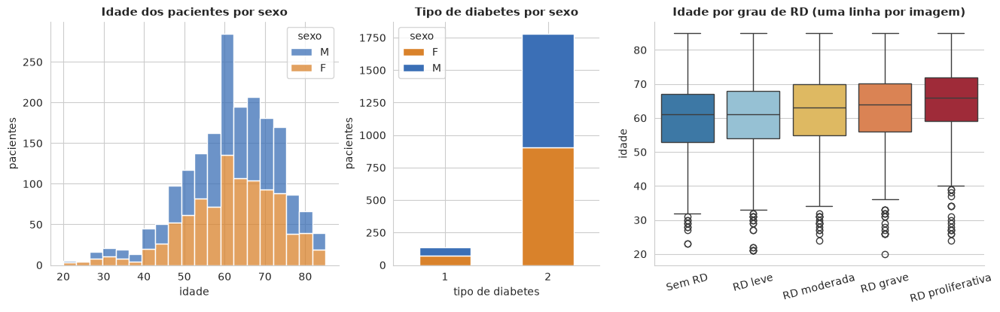

Correlação de Spearman entre idade e grau: rho = 0.161 (p = 7.7e-19)


In [11]:
def plotar_demografia(pacientes, imagens):
    fig, eixos = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1.6]})
    sns.histplot(data=pacientes, x="idade", hue="sexo", multiple="stack", bins=20, palette={"M": "#3B6FB6", "F": "#D9822B"}, ax=eixos[0])
    eixos[0].set_title("Idade dos pacientes por sexo")
    eixos[0].set_ylabel("pacientes")
    tipos = pd.crosstab(pacientes["tipo_diabetes"], pacientes["sexo"])
    tipos.plot(kind="bar", stacked=True, color={"M": "#3B6FB6", "F": "#D9822B"}, rot=0, ax=eixos[1])
    eixos[1].set_title("Tipo de diabetes por sexo")
    eixos[1].set_xlabel("tipo de diabetes")
    eixos[1].set_ylabel("pacientes")
    sns.boxplot(data=imagens, x="grau", y="idade", hue="grau", palette=CORES_GRAU, legend=False, ax=eixos[2])
    eixos[2].set_xticks(range(5), [NOMES_GRAUS[g] for g in range(5)], rotation=15)
    eixos[2].set_title("Idade por grau de RD (uma linha por imagem)")
    eixos[2].set_xlabel("")
    return fig


salvar_figura(plotar_demografia(PACIENTES_FDR26, TABELAS["FDR26"]), "01_demografia_fdr26")

rho, p = stats.spearmanr(TABELAS["FDR26"]["idade"], TABELAS["FDR26"]["grau"])
print(f"Correlação de Spearman entre idade e grau: rho = {rho:.3f} (p = {p:.2g})")

Os 1.918 pacientes do FDR26 têm idade média de 61,4 anos (de 20 a 85), com sexo equilibrado (976 mulheres e 942 homens). O diabetes tipo 2 domina (1.782 pacientes, 93%). Embora a descrição do Zenodo mencione pacientes diabéticos e não diabéticos [7], todos os registros do catálogo têm diabetes tipo 1 ou 2.

A idade cresce com o grau: a mediana passa de cerca de 61 anos sem RD para cerca de 66 anos na RD proliferativa. A correlação de Spearman é positiva e significativa, mas fraca (rho = 0,16). A idade acompanha a gravidade, como esperado pelo tempo de doença, mas sozinha explica pouco.

### 1.6 Várias imagens por paciente no FDR26

O identificador das imagens do FDR26 tem 10 caracteres. Os 8 primeiros identificam o paciente e os 2 últimos numeram a imagem (por exemplo, WAJHZX6C01, WAJHZX6C02 e WAJHZX6C03 são do mesmo paciente). Sexo e idade são idênticos dentro de cada um desses grupos, o que confirma a leitura. A tabela mostra quantas imagens cada paciente tem e se o grau muda entre as imagens do mesmo paciente.

In [12]:
imagens_por_paciente = PACIENTES_FDR26["imagens"].value_counts().sort_index()
display(pd.DataFrame({
    "pacientes": imagens_por_paciente,
    "imagens": imagens_por_paciente * imagens_por_paciente.index,
}).rename_axis("imagens por paciente").T)

varias = PACIENTES_FDR26[PACIENTES_FDR26["imagens"] > 1]
print(f"Pacientes com mais de uma imagem: {len(varias)} de {len(PACIENTES_FDR26)}")
print(f"Desses, com graus diferentes entre as imagens: {(varias['graus_distintos'] > 1).sum()} ({100 * (varias['graus_distintos'] > 1).mean():.1f}%)")
display(TABELAS["FDR26"][TABELAS["FDR26"]["grupo"] == "FDR26_WAJHZX6C"][["arquivo", "grupo", "grau", "grade_dr", "sexe", "idade"]])

imagens por paciente,1,2,3,4,5,6,7,8
pacientes,1063,742,37,55,10,7,2,2
imagens,1063,1484,111,220,50,42,14,16


Pacientes com mais de uma imagem: 855 de 1918
Desses, com graus diferentes entre as imagens: 407 (47.6%)


,arquivo,grupo,grau,grade_dr,sexe,idade
0,WAJHZX6C01.jpg,FDR26_WAJHZX6C,0,DR0 - Pas de RD,M,58
505,WAJHZX6C02.jpg,FDR26_WAJHZX6C,1,DR1 - Minime,M,58
1206,WAJHZX6C03.jpg,FDR26_WAJHZX6C,2,DR2 - Moderee,M,58


855 dos 1.918 pacientes (45%) têm mais de uma imagem, e 1.937 das 3.000 imagens pertencem a esses pacientes. Em 407 deles (47,6%), o grau muda entre as imagens, como no exemplo WAJHZX6C, com graus 0, 1 e 2. Isso é esperado, porque cada imagem pode ser de um olho ou de uma visita diferente, e cada uma recebe o próprio grau.

Duas consequências. Imagens do mesmo paciente são muito parecidas entre si (mesma retina, mesma câmera, mesmo dia) e precisam ficar do mesmo lado da divisão treino e teste. E o grau é da imagem, não do paciente, o que justifica analisar por imagem.

### 1.7 Correspondência entre catálogo e imagens no disco

Cada linha do catálogo precisa ter um arquivo de imagem, e vice-versa.

In [13]:
EXTENSOES = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}


def listar_imagens(pasta):
    return {p.name: p for p in sorted(pasta.iterdir()) if p.suffix.lower() in EXTENSOES}


def conferir_correspondencia(tabela, pasta):
    no_disco = set(listar_imagens(pasta))
    no_catalogo = set(tabela["arquivo"])
    return pd.Series({
        "imagens no disco": len(no_disco),
        "registros no catálogo": len(no_catalogo),
        "registros sem imagem": len(no_catalogo - no_disco),
        "imagens sem registro": len(no_disco - no_catalogo),
        "quais registros sem imagem": ", ".join(sorted(no_catalogo - no_disco)) or "-",
        "quais imagens sem registro": ", ".join(sorted(no_disco - no_catalogo)) or "-",
    })


pd.DataFrame({base: conferir_correspondencia(TABELAS[base], CAMINHOS.imagens[base]) for base in BASES})

,APTOS_2019,FDR26
imagens no disco,3662,3000
registros no catálogo,3662,3000
registros sem imagem,0,1
imagens sem registro,0,1
quais registros sem imagem,-,2T2SALA702.jpg
quais imagens sem registro,-,2F993EP902(2).jpg


O FDR26 tem um registro sem imagem e uma imagem sem registro. Comparamos a imagem sem registro com as imagens de nomes parecidos pelo hash MD5 do arquivo, que é idêntico apenas quando o conteúdo é idêntico.

In [14]:
def md5_do_arquivo(caminho):
    return hashlib.md5(Path(caminho).read_bytes()).hexdigest()


PASTA_FDR26 = CAMINHOS.imagens["FDR26"]
CANDIDATAS_ORFA = ["2F993EP902(2).jpg", "2F993EP901.jpg", "2F993EP902.jpg", "2F993EP903.jpg", "2T2SALA701.jpg", "2T2SALA703.jpg"]
TAB_ORFA = pd.DataFrame([
    {"arquivo": nome, "existe": (PASTA_FDR26 / nome).exists(), "md5": md5_do_arquivo(PASTA_FDR26 / nome) if (PASTA_FDR26 / nome).exists() else None}
    for nome in CANDIDATAS_ORFA
]).merge(TABELAS["FDR26"][["arquivo", "grau", "sexe", "idade"]], on="arquivo", how="left")
TAB_ORFA

,arquivo,existe,md5,grau,sexe,idade
0,2F993EP902(2).jpg,True,d00e0d801b31371a62a0828a3db94afd,NaN,NaN,NaN
1,2F993EP901.jpg,True,ddad5b6399f3cd068cf6ed195bf78ebf,2.0,M,57.0
2,2F993EP902.jpg,True,d00e0d801b31371a62a0828a3db94afd,3.0,M,57.0
3,2F993EP903.jpg,False,NaN,NaN,NaN,NaN
4,2T2SALA701.jpg,True,78bf77950a0be7ea424c45f7e49474d8,0.0,M,44.0
5,2T2SALA703.jpg,True,53081881e6b6e8f40ae611d1c56a63b8,0.0,M,44.0


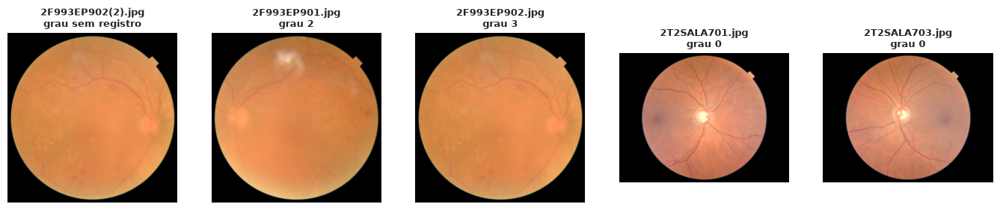

In [15]:
def mostrar_imagens(caminhos_e_titulos, colunas=4, lado=3.4):
    linhas = int(np.ceil(len(caminhos_e_titulos) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(lado * colunas, lado * linhas), squeeze=False)
    for eixo in eixos.ravel():
        eixo.axis("off")
    for eixo, (caminho, titulo) in zip(eixos.ravel(), caminhos_e_titulos):
        eixo.imshow(ler_miniatura(caminho))
        eixo.set_title(titulo, fontsize=9)
    return fig


def ler_miniatura(caminho, lado=512):
    with Image.open(caminho) as imagem:
        imagem = imagem.convert("RGB")
        imagem.thumbnail((lado, lado))
        return np.asarray(imagem)


existentes = TAB_ORFA[TAB_ORFA["existe"]]
salvar_figura(
    mostrar_imagens([(PASTA_FDR26 / r.arquivo, f"{r.arquivo}\ngrau {'sem registro' if pd.isna(r.grau) else int(r.grau)}") for r in existentes.itertuples()], colunas=len(existentes)),
    "01_imagem_sem_registro_fdr26",
)

A imagem sem registro, 2F993EP902(2).jpg, tem o mesmo hash MD5 de 2F993EP902.jpg: é uma cópia exata, provavelmente criada por engano na exportação. Ela não é a imagem que falta. O registro 2T2SALA702.jpg continua sem imagem, e as imagens 2T2SALA701 e 2T2SALA703 do mesmo paciente são diferentes da cópia. A cópia fica fora porque não tem rótulo, e o registro fica fora porque não tem imagem. O FDR26 segue com 2.999 imagens.

### 1.8 Catálogo unificado

Juntamos as duas bases em uma única tabela, com o caminho de cada imagem e o alvo binário referável (1 quando o grau é 2 ou mais). Registros sem imagem saem nesta etapa.

In [16]:
def montar_catalogo(tabelas, limiar):
    partes = []
    for base, tabela in tabelas.items():
        disco = listar_imagens(CAMINHOS.imagens[base])
        partes.append(tabela.assign(dataset=base, caminho=tabela["arquivo"].map(lambda a: str(disco[a]) if a in disco else None)))
    catalogo = pd.concat(partes, ignore_index=True)
    removidos = catalogo["caminho"].isna().sum()
    catalogo = catalogo.dropna(subset=["caminho"]).reset_index(drop=True)
    print(f"Registros sem imagem removidos: {removidos}")
    return catalogo.assign(referavel=(catalogo["grau"] >= limiar).astype(int))


CATALOGO = montar_catalogo(TABELAS, CFG.limiar_referavel)
print(f"Catálogo unificado: {len(CATALOGO)} imagens")
pd.crosstab(CATALOGO["dataset"], CATALOGO["grau"].map(NOMES_GRAUS), margins=True, margins_name="total")[[*NOMES_GRAUS.values(), "total"]]

Registros sem imagem removidos: 1
Catálogo unificado: 6661 imagens


grau,Sem RD,RD leve,RD moderada,RD grave,RD proliferativa,total
dataset,,,,,,
APTOS_2019,1805,370,999,193,295,3662
FDR26,504,701,583,632,579,2999
total,2309,1071,1582,825,874,6661


## 2. As imagens

### 2.1 Galeria por grau

Duas imagens sorteadas de cada grau, em cada base. A galeria serve para criar intuição: como a doença aparece e como as duas bases diferem na aparência geral das fotos.

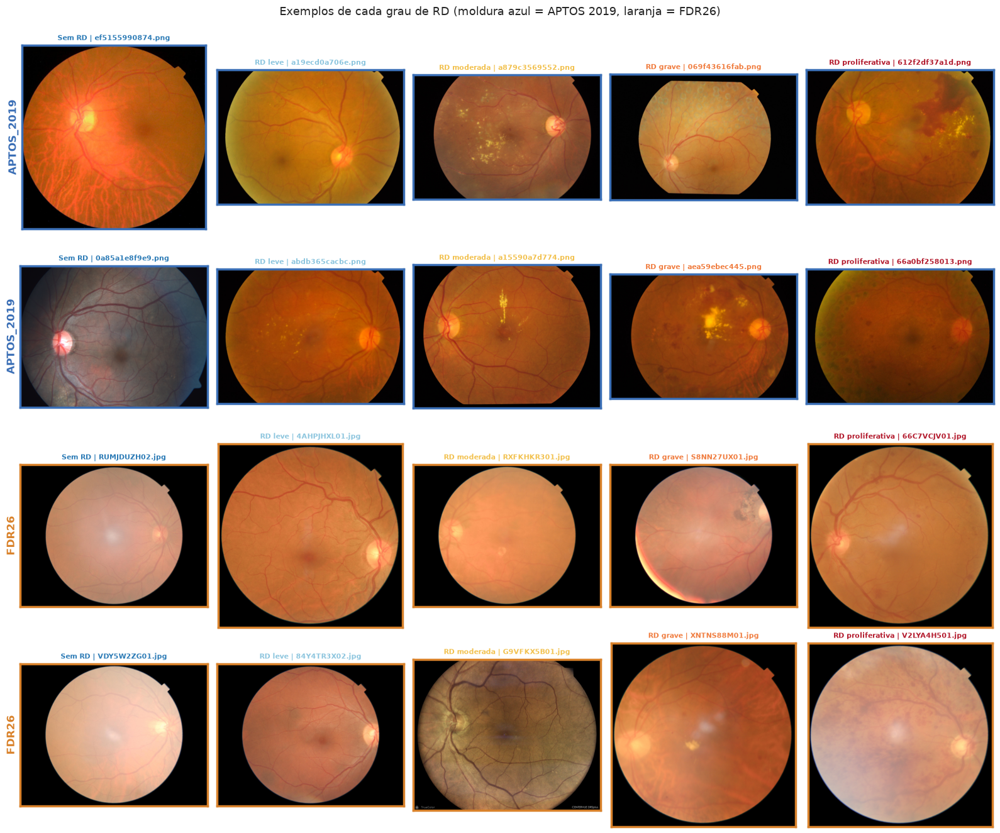

In [17]:
def galeria_por_grau(catalogo, por_grau=2, semente=CFG.semente):
    rng = np.random.RandomState(semente)
    fig, eixos = plt.subplots(len(BASES) * por_grau, 5, figsize=(16, 3.3 * len(BASES) * por_grau))
    for b, base in enumerate(BASES):
        for g in range(5):
            opcoes = catalogo[(catalogo["dataset"] == base) & (catalogo["grau"] == g)]
            for j, linha in enumerate(opcoes.sample(por_grau, random_state=rng).itertuples()):
                eixo = eixos[b * por_grau + j, g]
                eixo.imshow(ler_miniatura(linha.caminho))
                eixo.set_xticks([])
                eixo.set_yticks([])
                eixo.set_title(f"{NOMES_GRAUS[g]} | {linha.arquivo}", fontsize=8, color=CORES_GRAU[g])
                for lado in eixo.spines.values():
                    lado.set_visible(True)
                    lado.set_color(CORES_BASE[base])
                    lado.set_linewidth(2.5)
            eixos[b * por_grau, 0].set_ylabel(base, fontsize=12, color=CORES_BASE[base], weight="bold")
            eixos[b * por_grau + 1, 0].set_ylabel(base, fontsize=12, color=CORES_BASE[base], weight="bold")
    fig.suptitle("Exemplos de cada grau de RD (moldura azul = APTOS 2019, laranja = FDR26)", y=1.0, fontsize=13)
    fig.tight_layout()
    return fig


salvar_figura(galeria_por_grau(CATALOGO), "02_galeria_por_grau")

A galeria mostra a diferença entre as bases antes de qualquer número. As fotos do APTOS variam muito: laranja intenso, fundo esverdeado ou acinzentado, círculos completos e círculos cortados em cima e embaixo. As fotos do FDR26 são mais claras e rosadas, com o círculo dentro de um quadro preto e um entalhe no canto superior direito. Também aparece no FDR26 ao menos uma foto de outra câmera (G9VFKX5B01, com a marca CenterVue DRSplus no rodapé).

Nos graus mais altos aparecem exsudatos duros (pontos amarelos), hemorragias e, na proliferativa, áreas extensas de sangue. Nos graus 0 e 1, a diferença é sutil a olho nu: a RD leve tem só microaneurismas, pontos vermelhos de poucos pixels.

### 2.2 Análise técnica dos arquivos

Formato, modo de cor, resolução e tamanho de cada arquivo, lidos do cabeçalho das imagens.

In [18]:
def ficha_tecnica(caminho):
    with Image.open(caminho) as imagem:
        return {
            "formato": imagem.format,
            "modo_cor": imagem.mode,
            "largura": imagem.width,
            "altura": imagem.height,
            "tamanho_mb": Path(caminho).stat().st_size / 1024 ** 2,
        }


FICHA = pd.DataFrame([ficha_tecnica(c) for c in CATALOGO["caminho"]])
FICHA["resolucao"] = FICHA["largura"].astype(str) + "x" + FICHA["altura"].astype(str)
CATALOGO = pd.concat([CATALOGO, FICHA], axis=1)


def resumo_tecnico(tabela):
    resolucoes = tabela["resolucao"].value_counts()
    return pd.Series({
        "formatos": ", ".join(f"{k} ({v})" for k, v in tabela["formato"].value_counts().items()),
        "modos de cor": ", ".join(f"{k} ({v})" for k, v in tabela["modo_cor"].value_counts().items()),
        "resoluções distintas": len(resolucoes),
        "resolução mais comum": f"{resolucoes.index[0]} ({resolucoes.iloc[0]} imagens)",
        "largura mín. / mediana / máx.": f"{tabela['largura'].min()} / {tabela['largura'].median():.0f} / {tabela['largura'].max()}",
        "altura mín. / mediana / máx.": f"{tabela['altura'].min()} / {tabela['altura'].median():.0f} / {tabela['altura'].max()}",
        "tamanho do arquivo (MB) mín. / mediana / máx.": f"{tabela['tamanho_mb'].min():.2f} / {tabela['tamanho_mb'].median():.2f} / {tabela['tamanho_mb'].max():.2f}",
    })


pd.DataFrame({base: resumo_tecnico(CATALOGO[CATALOGO["dataset"] == base]) for base in BASES})

,APTOS_2019,FDR26
formatos,PNG (3662),JPEG (2999)
modos de cor,RGB (3662),RGB (2999)
resoluções distintas,17,4
resolução mais comum,1050x1050 (974 imagens),2576x1958 (1782 imagens)
largura mín. / mediana / máx.,474 / 2144 / 4288,1956 / 2576 / 3600
altura mín. / mediana / máx.,358 / 1536 / 2848,1934 / 1958 / 2910
tamanho do arquivo (MB) mín. / mediana / máx.,0.21 / 1.85 / 7.32,0.11 / 0.24 / 4.15


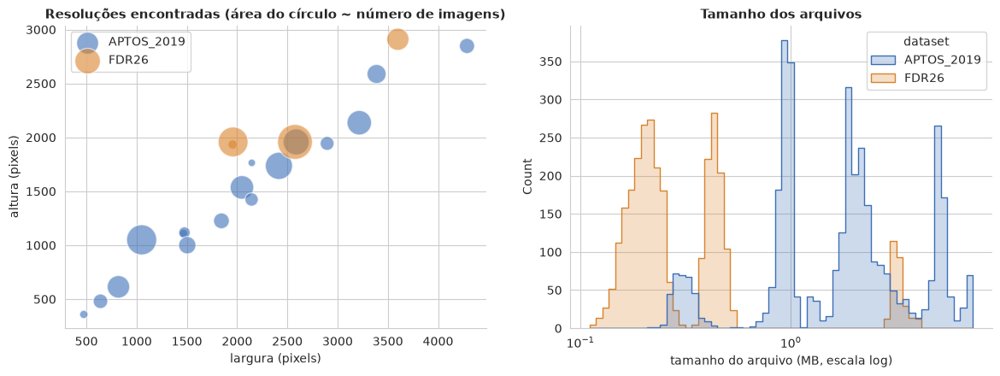

In [19]:
def plotar_ficha_tecnica(catalogo):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 4.6))
    contagem = catalogo.groupby(["dataset", "largura", "altura"]).size().reset_index(name="imagens")
    for base in BASES:
        parte = contagem[contagem["dataset"] == base]
        eixos[0].scatter(parte["largura"], parte["altura"], s=20 + 2.5 * np.sqrt(parte["imagens"]) * 8, color=CORES_BASE[base], alpha=0.6, label=base, edgecolor="white")
    eixos[0].set_xlabel("largura (pixels)")
    eixos[0].set_ylabel("altura (pixels)")
    eixos[0].set_title("Resoluções encontradas (área do círculo ~ número de imagens)")
    eixos[0].legend()
    sns.histplot(data=catalogo, x="tamanho_mb", hue="dataset", palette=CORES_BASE, bins=60, log_scale=True, element="step", ax=eixos[1])
    eixos[1].set_xlabel("tamanho do arquivo (MB, escala log)")
    eixos[1].set_title("Tamanho dos arquivos")
    return fig


salvar_figura(plotar_ficha_tecnica(CATALOGO), "02_ficha_tecnica")

O APTOS tem 17 resoluções, de 474 × 358 a 4.288 × 2.848 pixels, todas em PNG. O FDR26 tem só 4 resoluções, sendo 2.576 × 1.958 a mais comum (1.782 imagens), todas em JPEG. Os arquivos do FDR26 são cerca de 8 vezes menores (mediana de 0,24 MB contra 1,85 MB), por causa da compressão JPEG. No gráfico de tamanhos, cada pico corresponde praticamente a uma resolução, e portanto a uma câmera.

Essas diferenças técnicas não têm relação com a doença, mas uma rede neural pode percebê-las: a compressão JPEG deixa artefatos, e reduzir para 224 pixels uma foto grande ou uma pequena produz texturas diferentes.

## 3. Pré-processamento

A rede neural recebe todas as imagens no mesmo formato. As etapas são:

1. Leitura do arquivo e cálculo do hash MD5, usado depois para achar duplicatas.
2. Máscara do campo de visão: pixels com intensidade máxima acima de um limiar pequeno são retina, e o resto é a borda preta.
3. Recorte da caixa que contém a retina, eliminando as bordas.
4. Redimensionamento para que o maior lado tenha 224 pixels, preservando a proporção.
5. Centralização em um quadrado preto de 224 × 224 pixels.
6. Normalização dos canais com a média e o desvio da ImageNet, no momento de entrar na rede.

O recorte importa. As bases têm bordas pretas de tamanhos diferentes, ligadas à câmera e ao protocolo. Sem recorte, a rede pode usar a borda como pista para separar as bases, o atalho descrito por Geirhos et al. [14].

In [20]:
def ler_imagem(caminho):
    conteudo = np.fromfile(caminho, dtype=np.uint8)
    bgr = cv2.imdecode(conteudo, cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), hashlib.md5(conteudo.tobytes()).hexdigest()


def mascara_campo_de_visao(rgb, limiar=12):
    return rgb.max(axis=2) > limiar


def caixa_da_retina(mascara):
    if mascara.sum() < 500:
        return (slice(None), slice(None))
    linhas = np.where(mascara.any(axis=1))[0]
    colunas = np.where(mascara.any(axis=0))[0]
    return (slice(linhas[0], linhas[-1] + 1), slice(colunas[0], colunas[-1] + 1))


def redimensionar_maior_lado(rgb, lado):
    escala = lado / max(rgb.shape[:2])
    novo = (max(1, round(rgb.shape[1] * escala)), max(1, round(rgb.shape[0] * escala)))
    return cv2.resize(rgb, novo, interpolation=cv2.INTER_AREA)


def centralizar_em_quadrado(rgb, lado):
    quadro = np.zeros((lado, lado, 3), np.uint8)
    topo = (lado - rgb.shape[0]) // 2
    esquerda = (lado - rgb.shape[1]) // 2
    quadro[topo:topo + rgb.shape[0], esquerda:esquerda + rgb.shape[1]] = rgb
    return quadro


def preparar_para_rede(recorte, lado):
    return centralizar_em_quadrado(redimensionar_maior_lado(recorte, lado), lado)

O passo a passo em uma imagem de cada base:

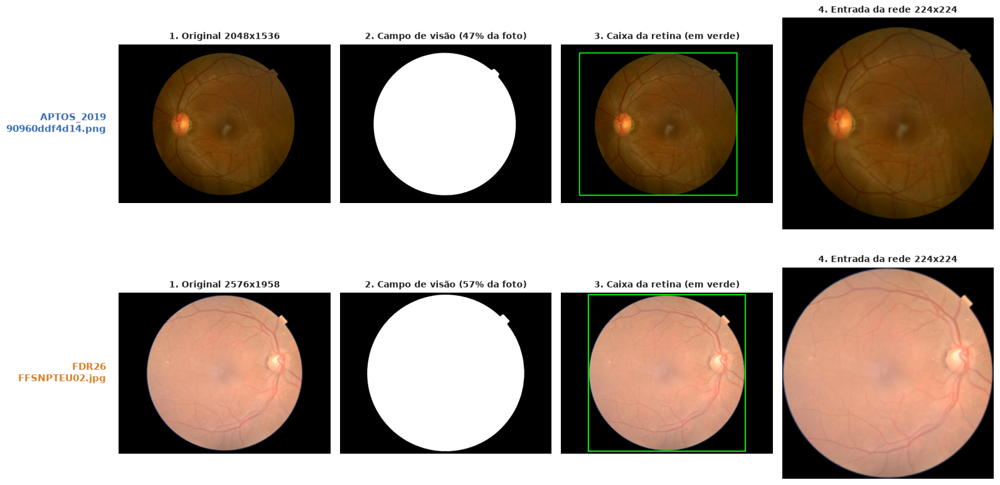

In [21]:
def plotar_preprocessamento(catalogo, semente=CFG.semente):
    exemplos = [catalogo[catalogo["dataset"] == base].sample(1, random_state=semente).iloc[0] for base in BASES]
    fig, eixos = plt.subplots(len(exemplos), 4, figsize=(16, 4.1 * len(exemplos)))
    for linha, exemplo in zip(eixos, exemplos):
        rgb, _ = ler_imagem(exemplo["caminho"])
        mascara = mascara_campo_de_visao(rgb)
        caixa = caixa_da_retina(mascara)
        recorte = rgb[caixa]
        final = preparar_para_rede(recorte, CFG.tamanho_imagem)
        com_caixa = rgb.copy()
        espessura = max(4, rgb.shape[0] // 150)
        cv2.rectangle(com_caixa, (caixa[1].start or 0, caixa[0].start or 0), ((caixa[1].stop or rgb.shape[1]) - 1, (caixa[0].stop or rgb.shape[0]) - 1), (0, 255, 0), espessura)
        paineis = [
            (rgb, f"1. Original {rgb.shape[1]}x{rgb.shape[0]}"),
            (mascara, f"2. Campo de visão ({100 * mascara.mean():.0f}% da foto)"),
            (com_caixa, "3. Caixa da retina (em verde)"),
            (final, f"4. Entrada da rede {CFG.tamanho_imagem}x{CFG.tamanho_imagem}"),
        ]
        for eixo, (imagem, titulo) in zip(linha, paineis):
            eixo.imshow(imagem, cmap="gray" if imagem.ndim == 2 else None)
            eixo.set_title(titulo, fontsize=10)
            eixo.axis("off")
        linha[0].text(-0.06, 0.5, f"{exemplo['dataset']}\n{exemplo['arquivo']}", transform=linha[0].transAxes, ha="right", va="center", fontsize=11, color=CORES_BASE[exemplo["dataset"]], weight="bold")
    fig.tight_layout()
    return fig


salvar_figura(plotar_preprocessamento(CATALOGO), "03_preprocessamento")

No APTOS de exemplo (2.048 × 1.536), a retina ocupa só 47% da foto, e no FDR26 (2.576 × 1.958), 57%. Depois do recorte, as duas retinas ocupam o quadrado de 224 × 224 quase por inteiro, e a borda preta, que diferia entre as câmeras, praticamente desaparece. O entalhe no canto superior direito sobrevive ao recorte porque faz parte do campo de visão. A 224 pixels, um microaneurisma fica com 1 ou 2 pixels, o que limita o que a rede consegue ver nos graus mais leves.

## 4. Medidas das imagens, duplicatas e vasos

Para cada imagem calculamos medidas simples e interpretáveis, direto dos pixels da retina. Elas não entram na clusterização. Servem para descrever as bases e, depois, para explicar o que cada cluster tem em comum.

| Medida | O que mede |
|---|---|
| largura, altura, tamanho_mb | resolução e tamanho do arquivo, muito ligados à câmera |
| area_util_rel | fração da foto ocupada pela caixa da retina |
| fov_ocupacao | fração da caixa ocupada pelo círculo da retina |
| brilho_L, contraste_L | média e desvio da luminância (canal L do espaço LAB) dentro da retina |
| media_R, media_G, media_B, saturacao | cor média |
| nitidez_lap | variância do laplaciano: valores baixos indicam foto desfocada |
| entropia | riqueza de tons de cinza |
| frac_escuro, frac_claro | fração de pixels sub e superexpostos |
| dens_escuras | estruturas mais escuras que a vizinhança no canal verde (vasos, hemorragias, microaneurismas), por black-hat após CLAHE [17] |
| dens_claras | estruturas mais claras que a vizinhança (disco óptico, exsudatos), por top-hat após CLAHE |
| densidade_vasos | fração da retina coberta por vasos, a partir das máscaras do FDR26 (só existe nessa base) |

dens_escuras e dens_claras são aproximações morfológicas. Elas acompanham lesões e vasos, mas não são detecção de lesões.

Na mesma passada, cada imagem é preparada para a rede (Seção 3) e gravada em um arquivo de cache no disco. A matriz de imagens 224 × 224 é lida desse arquivo aos poucos, sem ocupar a memória toda.

In [22]:
def reduzir_para(rgb, mascara, lado_max):
    escala = lado_max / max(rgb.shape[:2])
    if escala >= 1:
        return rgb, mascara
    novo = (round(rgb.shape[1] * escala), round(rgb.shape[0] * escala))
    return cv2.resize(rgb, novo, interpolation=cv2.INTER_AREA), cv2.resize(mascara.astype(np.uint8), novo, interpolation=cv2.INTER_NEAREST) > 0


def mascaras_da_retina(mascara):
    fechada = cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    interna = cv2.erode(fechada, np.ones((15, 15), np.uint8)) > 0
    fechada = fechada > 0
    return fechada, (interna if interna.sum() >= 200 else fechada)


def medidas_de_cor_e_brilho(rgb, regiao):
    luminancia = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0][regiao].astype(float)
    return {
        "brilho_L": luminancia.mean(),
        "contraste_L": luminancia.std(),
        "media_R": rgb[..., 0][regiao].mean(),
        "media_G": rgb[..., 1][regiao].mean(),
        "media_B": rgb[..., 2][regiao].mean(),
        "saturacao": cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)[..., 1][regiao].mean(),
    }


def medidas_de_textura(rgb, regiao):
    cinza = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    histograma = np.bincount(cinza[regiao], minlength=256) / max(1, regiao.sum())
    p = histograma[histograma > 0]
    return {
        "nitidez_lap": cv2.Laplacian(cinza, cv2.CV_64F)[regiao].var(),
        "entropia": float(-(p * np.log2(p)).sum()),
        "frac_escuro": (cinza[regiao] < 40).mean(),
        "frac_claro": (cinza[regiao] > 215).mean(),
    }


def medidas_de_estruturas(rgb, regiao):
    verde = cv2.createCLAHE(2.0, (8, 8)).apply(rgb[..., 1])
    elemento = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    return {
        "dens_escuras": (cv2.morphologyEx(verde, cv2.MORPH_BLACKHAT, elemento)[regiao] > 20).mean(),
        "dens_claras": (cv2.morphologyEx(verde, cv2.MORPH_TOPHAT, elemento)[regiao] > 40).mean(),
    }


def densidade_de_vasos(caminho_mascara, caixa, forma_original, regiao):
    vasos = cv2.imread(str(caminho_mascara), cv2.IMREAD_GRAYSCALE)
    if vasos.shape != forma_original:
        vasos = cv2.resize(vasos, (forma_original[1], forma_original[0]), interpolation=cv2.INTER_NEAREST)
    vasos = cv2.resize(vasos[caixa], (regiao.shape[1], regiao.shape[0]), interpolation=cv2.INTER_NEAREST) > 127
    return float(vasos[regiao].mean())


def medir_e_preparar(caminho, caminho_vasos, lado_rede, lado_medidas):
    rgb, md5 = ler_imagem(caminho)
    mascara = mascara_campo_de_visao(rgb)
    caixa = caixa_da_retina(mascara)
    recorte = rgb[caixa]
    menor, mascara_menor = reduzir_para(recorte, mascara[caixa], lado_medidas)
    fechada, interna = mascaras_da_retina(mascara_menor)
    medidas = {
        "md5": md5,
        "area_util_rel": recorte.shape[0] * recorte.shape[1] / (rgb.shape[0] * rgb.shape[1]),
        "fov_ocupacao": float(fechada.mean()),
        **medidas_de_cor_e_brilho(menor, interna),
        **medidas_de_textura(menor, interna),
        **medidas_de_estruturas(menor, interna),
        "densidade_vasos": densidade_de_vasos(caminho_vasos, caixa, rgb.shape[:2], fechada) if caminho_vasos else np.nan,
    }
    return medidas, preparar_para_rede(recorte, lado_rede)

A célula abaixo processa as 6.661 imagens em paralelo, em blocos de 256. Na primeira execução leva alguns minutos. Nas seguintes, tudo é lido do cache.

In [23]:
def caminho_da_mascara_de_vasos(linha):
    if linha["dataset"] != "FDR26":
        return None
    return str(CAMINHOS.mascaras_vasos / f"{Path(linha['arquivo']).stem}_mask.png")


def chave_de_cache(*partes):
    return hashlib.md5("|".join(map(str, partes)).encode()).hexdigest()[:10]


class ImagensEmDisco:
    def __init__(self, arquivo, linhas=None):
        self.arquivo = arquivo
        self.dados = np.load(arquivo, mmap_mode="r")
        self.linhas = np.arange(len(self.dados)) if linhas is None else np.asarray(linhas)

    def __len__(self):
        return len(self.linhas)

    def __getitem__(self, posicao):
        return np.asarray(self.dados[self.linhas[posicao]])

    @property
    def shape(self):
        return (len(self), *self.dados.shape[1:])

    def selecionar(self, posicoes):
        return ImagensEmDisco(self.arquivo, self.linhas[posicoes])


def processar_imagens(catalogo, cfg, bloco=256):
    chave = chave_de_cache(*catalogo["caminho"], cfg.tamanho_imagem, cfg.lado_medidas)
    arquivo_imagens = CAMINHOS.cache / f"imagens_{cfg.tamanho_imagem}_{chave}.npy"
    arquivo_medidas = CAMINHOS.cache / f"medidas_{chave}.csv"
    if arquivo_imagens.exists() and arquivo_medidas.exists():
        print("Imagens e medidas lidas do cache.")
        return ImagensEmDisco(arquivo_imagens), pd.read_csv(arquivo_medidas)
    inicio = time.time()
    temporario = arquivo_imagens.with_name(arquivo_imagens.stem + "_parcial.npy")
    imagens = np.lib.format.open_memmap(temporario, mode="w+", dtype=np.uint8, shape=(len(catalogo), cfg.tamanho_imagem, cfg.tamanho_imagem, 3))
    vasos = [caminho_da_mascara_de_vasos(linha) for _, linha in catalogo.iterrows()]
    medidas = []
    for comeco in range(0, len(catalogo), bloco):
        fim = min(comeco + bloco, len(catalogo))
        resultados = Parallel(n_jobs=cfg.n_jobs)(
            delayed(medir_e_preparar)(catalogo["caminho"].iat[i], vasos[i], cfg.tamanho_imagem, cfg.lado_medidas) for i in range(comeco, fim)
        )
        for i, (medida, imagem) in enumerate(resultados, start=comeco):
            imagens[i] = imagem
            medidas.append(medida)
        print(f"\r{fim}/{len(catalogo)} imagens processadas ({time.time() - inicio:.0f}s)", end="")
    imagens.flush()
    del imagens
    temporario.rename(arquivo_imagens)
    tabela = pd.DataFrame(medidas)
    tabela.to_csv(arquivo_medidas, index=False)
    print(f"\nConcluído em {time.time() - inicio:.0f}s. Cache: {arquivo_imagens.name} ({arquivo_imagens.stat().st_size / 1024 ** 2:.0f} MB)")
    return ImagensEmDisco(arquivo_imagens), tabela


X_IMAGENS, MEDIDAS = processar_imagens(CATALOGO, CFG)
CATALOGO = pd.concat([CATALOGO, MEDIDAS], axis=1)
print(f"Matriz de imagens: {X_IMAGENS.shape} (uint8) | medidas: {MEDIDAS.shape[1]} colunas")
CATALOGO[["dataset", "arquivo", "grau", "brilho_L", "nitidez_lap", "dens_escuras", "dens_claras", "densidade_vasos"]].head()

Imagens e medidas lidas do cache.
Matriz de imagens: (6661, 224, 224, 3) (uint8) | medidas: 16 colunas


,dataset,arquivo,grau,brilho_L,nitidez_lap,dens_escuras,dens_claras,densidade_vasos
0,APTOS_2019,000c1434d8d7.png,2,75.551564,26.910641,0.058472,0.005000,NaN
1,APTOS_2019,001639a390f0.png,4,113.861572,18.394986,0.070135,0.003829,NaN
2,APTOS_2019,0024cdab0c1e.png,1,92.192587,30.981156,0.027298,0.001238,NaN
3,APTOS_2019,002c21358ce6.png,0,120.238023,50.685926,0.175449,0.016311,NaN
4,APTOS_2019,005b95c28852.png,0,54.387880,32.077421,0.144228,0.002771,NaN


### 4.1 Imagens duplicadas

Duas imagens com o mesmo hash MD5 têm conteúdo idêntico. Quando as cópias têm graus diferentes, não há como saber qual rótulo está certo.

In [24]:
def auditar_duplicatas(catalogo):
    por_hash = catalogo.groupby("md5")
    return catalogo.assign(copias=por_hash["arquivo"].transform("size"), graus_no_hash=por_hash["grau"].transform("nunique"), bases_no_hash=por_hash["dataset"].transform("nunique"))


def resumo_duplicatas(auditoria):
    linhas = {}
    for base in BASES:
        parte = auditoria[(auditoria["dataset"] == base) & (auditoria["copias"] > 1)]
        conflito = parte[parte["graus_no_hash"] > 1]
        linhas[base] = {
            "imagens em grupos de cópias": len(parte),
            "grupos de cópias": parte["md5"].nunique(),
            "grupos com graus conflitantes": conflito["md5"].nunique(),
            "imagens com graus conflitantes": len(conflito),
        }
    linhas["entre as bases"] = {"imagens em grupos de cópias": int((auditoria["bases_no_hash"] > 1).sum())}
    return pd.DataFrame(linhas).fillna(0).astype(int)


AUDITORIA = auditar_duplicatas(CATALOGO)
resumo_duplicatas(AUDITORIA)

,APTOS_2019,FDR26,entre as bases
imagens em grupos de cópias,251,320,0
grupos de cópias,123,160,0
grupos com graus conflitantes,30,62,0
imagens com graus conflitantes,62,124,0


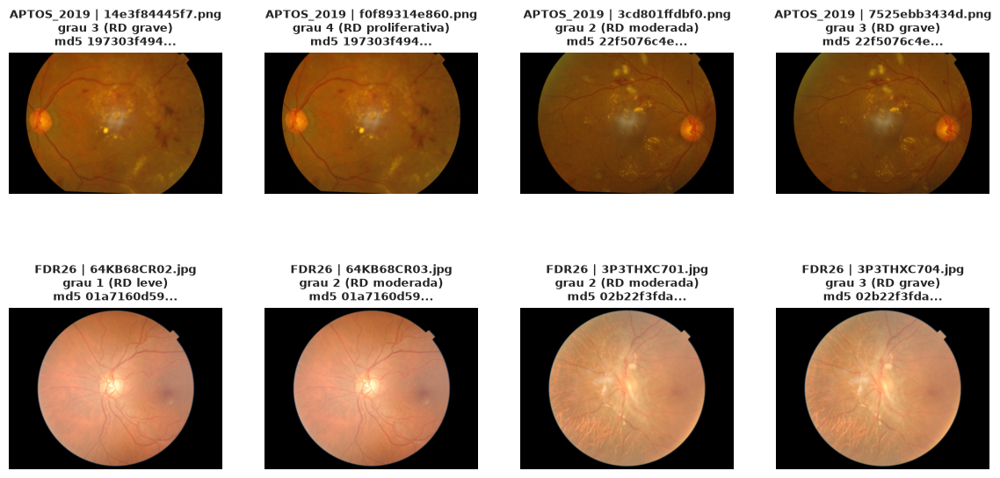

In [25]:
def exemplos_conflitantes(auditoria, pares_por_base=2):
    lista = []
    for base in BASES:
        conflitos = auditoria[(auditoria["dataset"] == base) & (auditoria["graus_no_hash"] > 1)].sort_values(["md5", "grau"])
        for _, grupo in list(conflitos.groupby("md5"))[:pares_por_base]:
            for linha in grupo.iloc[[0, -1]].itertuples():
                lista.append((linha.caminho, f"{base} | {linha.arquivo}\ngrau {linha.grau} ({NOMES_GRAUS[linha.grau]})\nmd5 {linha.md5[:10]}..."))
    return lista


salvar_figura(mostrar_imagens(exemplos_conflitantes(AUDITORIA), colunas=4, lado=3.6), "04_duplicatas_conflitantes")

O APTOS confirma o achado do projeto OIO+: 123 grupos de cópias exatas (251 imagens), dos quais 30 têm graus conflitantes (62 imagens). Na maioria dos conflitos a diferença é de um grau, mas em 9 grupos ela chega a 2 ou 3 graus.

O FDR26 tem o mesmo problema, em escala maior: 160 pares de imagens idênticas (320 imagens), e 62 pares com graus diferentes (124 imagens), em 56 deles com 1 grau de diferença e em 6 com 2. Um detalhe agrava o caso: em 81 dos 160 pares, as duas cópias estão registradas como pacientes diferentes, quase sempre com idades diferentes. Parte dos identificadores de paciente do FDR26 não é confiável, e a mesma foto entrou na base duas vezes. A figura mostra dois exemplos de cada base. Não há cópias entre as bases.

Todas as cópias com graus conflitantes saem, porque não há como saber o rótulo certo, e das cópias sem conflito fica uma só. Saem 186 imagens por conflito e 194 cópias exatas, e seguem 6.281 imagens (3.504 do APTOS e 2.777 do FDR26). Como a remoção acontece antes da divisão treino e teste, nenhuma foto aparece dos dois lados, mesmo quando está registrada com dois pacientes. Vale reportar esse achado aos autores do FDR26.

In [26]:
def remover_duplicatas(auditoria):
    sem_conflito = auditoria[auditoria["graus_no_hash"] == 1]
    unicas = sem_conflito.drop_duplicates("md5", keep="first")
    print(f"Removidas {len(auditoria) - len(sem_conflito)} imagens por graus conflitantes e {len(sem_conflito) - len(unicas)} cópias exatas.")
    return unicas.index.to_numpy()


MANTER = remover_duplicatas(AUDITORIA)
CATALOGO = CATALOGO.loc[MANTER].reset_index(drop=True)
X_IMAGENS = X_IMAGENS.selecionar(MANTER)
print(f"Imagens que seguem na análise: {len(CATALOGO)}")
pd.crosstab(CATALOGO["dataset"], CATALOGO["grau"].map(NOMES_GRAUS), margins=True, margins_name="total")[[*NOMES_GRAUS.values(), "total"]]

Removidas 186 imagens por graus conflitantes e 194 cópias exatas.
Imagens que seguem na análise: 6281


grau,Sem RD,RD leve,RD moderada,RD grave,RD proliferativa,total
dataset,,,,,,
APTOS_2019,1796,338,922,177,271,3504
FDR26,485,630,515,592,555,2777
total,2281,968,1437,769,826,6281


### 4.2 As duas bases são diferentes nas imagens?

Comparamos as medidas entre APTOS 2019 e FDR26. O tamanho de efeito η² (de 0 a 1) diz quanto da variação de cada medida é explicado pela base. Valores acima de 0,14 são considerados grandes [34]. Com milhares de imagens, o valor-p é sempre minúsculo, e por isso o tamanho de efeito é o número que importa.

In [27]:
COLUNAS_MEDIDAS = [
    "largura", "altura", "tamanho_mb", "area_util_rel", "fov_ocupacao",
    "brilho_L", "contraste_L", "media_R", "media_G", "media_B", "saturacao",
    "nitidez_lap", "entropia", "frac_escuro", "frac_claro",
    "dens_escuras", "dens_claras", "densidade_vasos",
]

NOMES_LEGIVEIS = {
    "largura": "largura da imagem", "altura": "altura da imagem", "tamanho_mb": "tamanho do arquivo",
    "area_util_rel": "área útil de retina", "fov_ocupacao": "ocupação do campo de visão",
    "brilho_L": "brilho", "contraste_L": "contraste", "media_R": "vermelho médio", "media_G": "verde médio",
    "media_B": "azul médio", "saturacao": "saturação", "nitidez_lap": "nitidez", "entropia": "entropia",
    "frac_escuro": "pixels escuros", "frac_claro": "pixels claros", "dens_escuras": "estruturas escuras",
    "dens_claras": "estruturas claras", "densidade_vasos": "densidade de vasos",
}


def testar_medidas(tabela, grupos, colunas):
    grupos = np.asarray(grupos)
    linhas = []
    for coluna in colunas:
        valores = tabela[coluna].to_numpy(dtype=float)
        validos = ~np.isnan(valores)
        amostras = [valores[validos & (grupos == g)] for g in np.unique(grupos[validos])]
        amostras = [a for a in amostras if len(a) > 1]
        if len(amostras) < 2 or np.nanstd(valores) == 0:
            continue
        h, p = stats.kruskal(*amostras)
        n, k = sum(len(a) for a in amostras), len(amostras)
        linhas.append({"medida": coluna, "H": h, "p_bonferroni": min(1.0, p * len(colunas)), "eta2": max(0.0, (h - k + 1) / (n - k))})
    return pd.DataFrame(linhas).sort_values("eta2", ascending=False).reset_index(drop=True)


def cramer_v(a, b):
    tabela = pd.crosstab(np.asarray(a), np.asarray(b))
    if min(tabela.shape) < 2:
        return 0.0
    return float(np.sqrt(stats.chi2_contingency(tabela)[0] / (tabela.values.sum() * (min(tabela.shape) - 1))))


def magnitude(eta2):
    return "grande" if eta2 >= 0.14 else "média" if eta2 >= 0.06 else "pequena" if eta2 >= 0.01 else "desprezível"


COLUNAS_COMPARAVEIS = [c for c in COLUNAS_MEDIDAS if c != "densidade_vasos"]
TAB_BASES = testar_medidas(CATALOGO, CATALOGO["dataset"], COLUNAS_COMPARAVEIS)
medianas = CATALOGO.groupby("dataset")[COLUNAS_COMPARAVEIS].median().T
TAB_BASES = TAB_BASES.join(medianas, on="medida").assign(efeito=lambda t: t["eta2"].map(magnitude))
TAB_BASES.round(4)

,medida,H,p_bonferroni,eta2,APTOS_2019,FDR26,efeito
0,media_B,4325.7178,0.0000,0.6888,19.7983,77.0303,grande
1,media_G,4021.0585,0.0000,0.6402,76.8394,121.2666,grande
2,brilho_L,3807.7128,0.0000,0.6063,104.4268,148.9731,grande
3,tamanho_mb,3260.0235,0.0000,0.5190,1.8420,0.2345,grande
4,media_R,3038.5236,0.0000,0.4838,147.9141,197.7214,grande
5,saturacao,2457.4977,0.0000,0.3912,219.6039,153.6409,grande
6,fov_ocupacao,2301.7125,0.0000,0.3664,0.8707,0.7886,grande
7,altura,1638.0048,0.0000,0.2607,1536.0000,1958.0000,grande
8,nitidez_lap,1033.0791,0.0000,0.1644,33.2625,18.9870,grande
9,frac_claro,1015.4634,0.0000,0.1616,0.0000,0.0016,grande


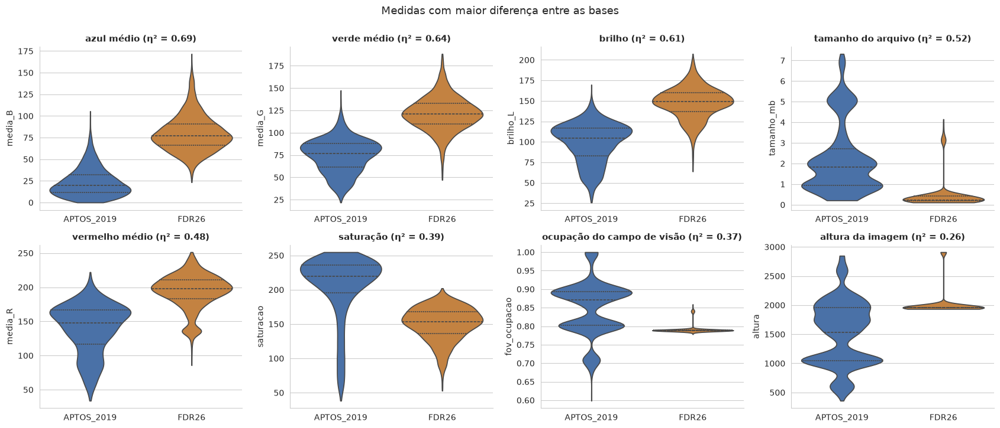

In [28]:
def plotar_medidas_por_base(catalogo, colunas):
    fig, eixos = plt.subplots(2, 4, figsize=(17, 7.2))
    for eixo, coluna in zip(eixos.ravel(), colunas):
        sns.violinplot(data=catalogo, x="dataset", y=coluna, hue="dataset", palette=CORES_BASE, cut=0, inner="quartile", legend=False, ax=eixo)
        eta2 = TAB_BASES.set_index("medida").loc[coluna, "eta2"]
        eixo.set_title(f"{NOMES_LEGIVEIS[coluna]} (η² = {eta2:.2f})")
        eixo.set_xlabel("")
        eixo.set_ylabel(coluna)
    fig.suptitle("Medidas com maior diferença entre as bases", y=1.0, fontsize=13)
    fig.tight_layout()
    return fig


salvar_figura(plotar_medidas_por_base(CATALOGO, TAB_BASES["medida"].head(8).tolist()), "04_medidas_por_base")

As duas bases são muito diferentes nas imagens. Dez medidas têm efeito grande, e as maiores estão na cor: o azul médio dentro da retina é de 20 no APTOS e 77 no FDR26 (η² = 0,69), e o brilho é de 104 contra 149 (η² = 0,61). O APTOS é mais saturado e alaranjado, e o FDR26, mais claro e rosado, como a galeria já sugeria. Também diferem o tamanho do arquivo (η² = 0,52), a ocupação do campo de visão (0,37) e a nitidez (0,16), maior no APTOS.

As medidas ligadas a lesões e vasos, como estruturas escuras e claras, praticamente não diferem entre as bases (η² < 0,01). O que separa as bases é a aquisição (câmera, iluminação, compressão), e não o conteúdo clínico. É o cenário em que um extrator pode agrupar por base, e não por doença [13,14].

### 4.3 As medidas mudam com o grau de RD?

Mediana de cada medida por grau, separada por base, com a faixa interquartil. Se uma medida acompanha o grau nas duas bases, ela carrega informação clínica. Se só muda entre as bases, ela é de aquisição.

In [29]:
TAB_GRAUS_MEDIDAS = pd.concat({
    base: testar_medidas(CATALOGO[CATALOGO["dataset"] == base], CATALOGO.loc[CATALOGO["dataset"] == base, "grau"], COLUNAS_MEDIDAS).set_index("medida")["eta2"]
    for base in BASES
}, axis=1).sort_values("FDR26", ascending=False)
TAB_GRAUS_MEDIDAS.columns = [f"η² grau ({b})" for b in BASES]
TAB_GRAUS_MEDIDAS.round(3)

,η² grau (APTOS_2019),η² grau (FDR26)
medida,,
densidade_vasos,NaN,0.221
tamanho_mb,0.286,0.079
nitidez_lap,0.174,0.077
altura,0.384,0.074
dens_escuras,0.181,0.066
dens_claras,0.036,0.059
largura,0.420,0.058
area_util_rel,0.033,0.051
frac_escuro,0.119,0.041


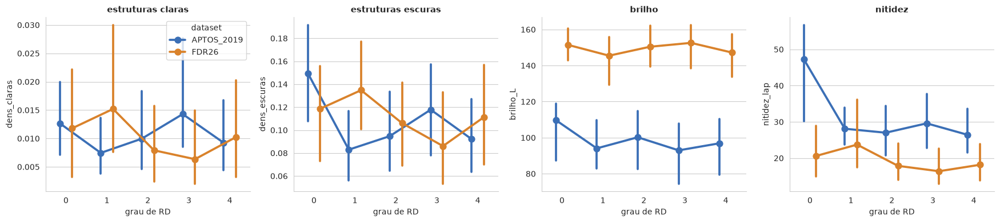

In [30]:
def plotar_medidas_por_grau(catalogo, colunas):
    fig, eixos = plt.subplots(1, len(colunas), figsize=(4.4 * len(colunas), 4))
    for eixo, coluna in zip(eixos, colunas):
        sns.pointplot(data=catalogo, x="grau", y=coluna, hue="dataset", palette=CORES_BASE, estimator="median", errorbar=("pi", 50), dodge=0.3, ax=eixo)
        eixo.set_title(NOMES_LEGIVEIS[coluna])
        eixo.set_xticks(range(5), [str(g) for g in range(5)])
        eixo.set_xlabel("grau de RD")
        if eixo is not eixos[0]:
            eixo.get_legend().remove()
    fig.tight_layout()
    return fig


salvar_figura(plotar_medidas_por_grau(CATALOGO, ["dens_claras", "dens_escuras", "brilho_L", "nitidez_lap"]), "04_medidas_por_grau")

No FDR26, a medida mais associada ao grau é a densidade de vasos (η² = 0,22, discutida na Seção 4.5). As demais têm efeito médio ou pequeno. A nitidez cai do grau 0 para os graus altos nas duas bases, o que é coerente com a perda de transparência dos meios e com lesões que borram a imagem.

No APTOS acontece algo que merece atenção: as medidas mais associadas ao grau são a largura (η² = 0,42), a altura (0,38), a ocupação do campo de visão (0,37) e o tamanho do arquivo (0,29). Todas são de aquisição, e não de lesão. As medidas morfológicas ficam abaixo delas (estruturas escuras, 0,18; claras, 0,04). A próxima célula investiga esse atalho.

### 4.4 Um atalho escondido no APTOS: a resolução da foto

No APTOS, largura e altura da imagem têm η² de 0,42 e 0,38 com o grau, maior que o de qualquer medida de lesão. Isso acontece quando clínicas ou câmeras diferentes enviaram pacientes com gravidades diferentes. A tabela mostra, para cada resolução com pelo menos 50 imagens, o grau médio e a proporção de RD referável.

In [31]:
def doenca_por_resolucao(catalogo, base, minimo=50):
    parte = catalogo[catalogo["dataset"] == base]
    tabela = parte.groupby("resolucao").agg(
        imagens=("arquivo", "size"),
        grau_medio=("grau", "mean"),
        pct_sem_rd=("grau", lambda s: 100 * (s == 0).mean()),
        pct_referavel=("referavel", lambda s: 100 * s.mean()),
    )
    return tabela[tabela["imagens"] >= minimo].sort_values("pct_referavel")


TAB_RESOLUCAO = doenca_por_resolucao(CATALOGO, "APTOS_2019")
aptos = CATALOGO[CATALOGO["dataset"] == "APTOS_2019"]
print(f"APTOS 2019: V de Cramér entre resolução e RD referável = {cramer_v(aptos['resolucao'], aptos['referavel']):.2f}")
TAB_RESOLUCAO.round(1)

APTOS 2019: V de Cramér entre resolução e RD referável = 0.74


,imagens,grau_medio,pct_sem_rd,pct_referavel
resolucao,,,,
2048x1536,351,0.0,100.0,0.0
819x614,287,0.0,97.2,0.3
1050x1050,972,0.2,92.7,5.3
2588x1958,533,1.3,43.3,48.4
2416x1736,585,1.9,3.8,61.4
4288x2848,52,2.5,0.0,65.4
1844x1226,61,2.4,0.0,78.7
3388x2588,141,2.4,0.0,90.8
3216x2136,374,2.3,0.5,96.3


A resolução da foto quase determina o diagnóstico no APTOS. As 351 imagens de 2.048 × 1.536 são todas sem RD, e as 287 de 819 × 614 também (97%). No outro extremo, 96% das 374 imagens de 3.216 × 2.136 e 91% das 141 de 3.388 × 2.588 são RD referável. O V de Cramér entre resolução e RD referável é 0,74, uma associação muito forte.

A explicação mais provável é que cada resolução corresponde a uma câmera ou clínica, e que clínicas diferentes enviaram pacientes com gravidades diferentes (rastreamento de um lado, encaminhados do outro). Para um modelo, isso é um atalho [14]: reconhecer a câmera já basta para acertar boa parte dos casos. O recorte e a redução para 224 pixels diminuem, mas não eliminam, essa pista, como mostram os clusters na Seção 11. No FDR26 o problema praticamente não existe, porque 4 resoluções cobrem a base inteira.

### 4.5 Máscaras de vasos do FDR26

Cada imagem do FDR26 tem uma máscara binária com os vasos. A figura mostra a máscara sobreposta à retina em três graus, e o gráfico seguinte compara a densidade de vasos entre os graus.

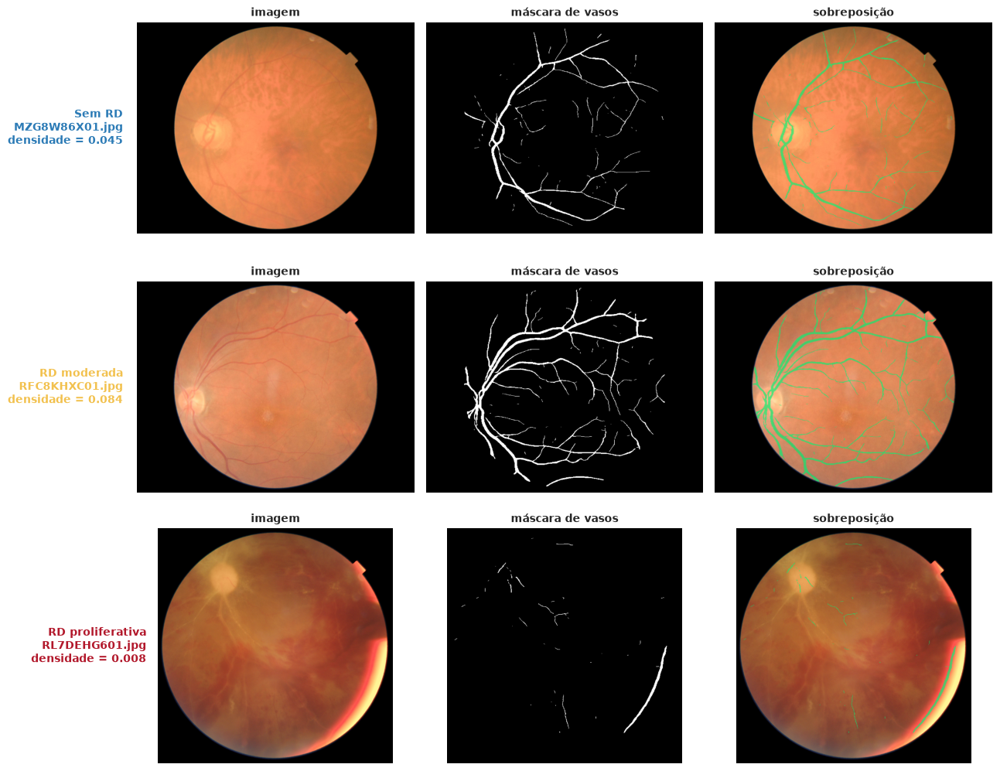

In [32]:
def sobrepor_vasos(caminho_imagem, caminho_mascara):
    rgb, _ = ler_imagem(caminho_imagem)
    vasos = cv2.imread(str(caminho_mascara), cv2.IMREAD_GRAYSCALE)
    vasos = cv2.resize(vasos, (rgb.shape[1], rgb.shape[0]), interpolation=cv2.INTER_NEAREST) > 127
    sobreposta = rgb.copy()
    sobreposta[vasos] = (0.35 * sobreposta[vasos] + 0.65 * np.array([0, 255, 120])).astype(np.uint8)
    return rgb, vasos, sobreposta


def plotar_vasos(catalogo, graus=(0, 2, 4), semente=CFG.semente):
    fdr = catalogo[catalogo["dataset"] == "FDR26"]
    fig, eixos = plt.subplots(len(graus), 3, figsize=(13, 3.4 * len(graus)))
    for linha, grau in zip(eixos, graus):
        exemplo = fdr[fdr["grau"] == grau].sample(1, random_state=semente).iloc[0]
        rgb, vasos, sobreposta = sobrepor_vasos(exemplo["caminho"], caminho_da_mascara_de_vasos(exemplo))
        for eixo, imagem, titulo in zip(linha, (rgb, vasos, sobreposta), ("imagem", "máscara de vasos", "sobreposição")):
            eixo.imshow(imagem, cmap="gray" if imagem.ndim == 2 else None)
            eixo.set_title(f"{titulo}", fontsize=10)
            eixo.axis("off")
        linha[0].text(-0.05, 0.5, f"{NOMES_GRAUS[grau]}\n{exemplo['arquivo']}\ndensidade = {exemplo['densidade_vasos']:.3f}", transform=linha[0].transAxes, ha="right", va="center", fontsize=10, color=CORES_GRAU[grau], weight="bold")
    fig.tight_layout()
    return fig


salvar_figura(plotar_vasos(CATALOGO), "04_mascaras_vasos")

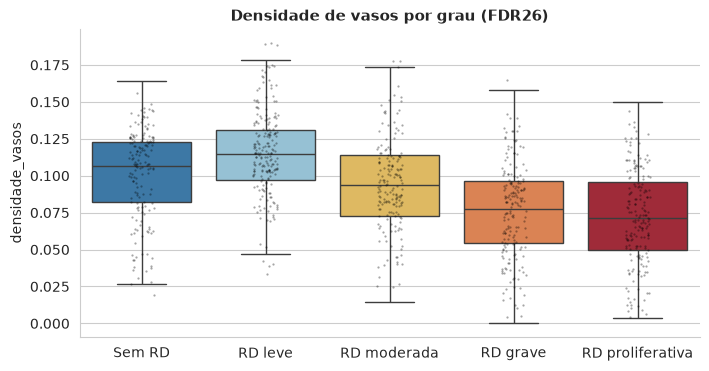

Spearman entre densidade de vasos e grau: rho = -0.417 (p = 3e-117)


In [33]:
def plotar_densidade_vasos(catalogo):
    fdr = catalogo[catalogo["dataset"] == "FDR26"]
    fig, eixo = plt.subplots(figsize=(8, 4))
    sns.boxplot(data=fdr, x="grau", y="densidade_vasos", hue="grau", palette=CORES_GRAU, legend=False, showfliers=False, ax=eixo)
    sns.stripplot(data=fdr.sample(min(900, len(fdr)), random_state=CFG.semente), x="grau", y="densidade_vasos", color="black", size=1.6, alpha=0.35, ax=eixo)
    eixo.set_xticks(range(5), [NOMES_GRAUS[g] for g in range(5)])
    eixo.set_xlabel("")
    eixo.set_title("Densidade de vasos por grau (FDR26)")
    return fig


salvar_figura(plotar_densidade_vasos(CATALOGO), "04_densidade_vasos_por_grau")
rho, p = stats.spearmanr(CATALOGO.loc[CATALOGO["dataset"] == "FDR26", "densidade_vasos"], CATALOGO.loc[CATALOGO["dataset"] == "FDR26", "grau"])
print(f"Spearman entre densidade de vasos e grau: rho = {rho:.3f} (p = {p:.2g})")

As máscaras seguem bem a árvore vascular nas imagens de boa qualidade (graus 0 e 2 da figura). Na RD proliferativa do exemplo, com hemorragia e reflexo na borda, a máscara quase não encontra vasos e marca o reflexo como vaso.

A densidade de vasos cai com o grau: a mediana passa de cerca de 0,11 nos graus 0 e 1 para cerca de 0,07 nos graus 3 e 4 (Spearman rho = −0,42). Há duas leituras possíveis. Uma é biológica: na RD avançada há fechamento capilar e áreas sem perfusão. A outra é técnica: hemorragias, exsudatos e opacidades atrapalham o segmentador que gerou as máscaras, e os vasos deixam de ser marcados. A origem das máscaras não é detalhada no Zenodo [7], e o exemplo acima sugere que a leitura técnica pesa. Por isso a densidade de vasos é usada aqui como descrição, e não como marcador clínico.

## 5. Divisão treino e teste por paciente

Separamos 25% dos pacientes para teste. A divisão é estratificada por base e grau, para que as proporções fiquem parecidas nos dois lados, e agrupada por paciente, para que nenhum paciente tenha imagens nos dois lados. Dentro do treino, 1 em cada 7 pacientes fica como validação do ajuste fino da rede (Seção 6).

In [34]:
def dividir_por_paciente(tabela, n_partes, semente):
    estratos = tabela["dataset"] + "_" + tabela["grau"].astype(str)
    divisor = StratifiedGroupKFold(n_splits=n_partes, shuffle=True, random_state=semente)
    maior, menor = next(divisor.split(tabela, estratos, groups=tabela["grupo"]))
    return np.sort(maior), np.sort(menor)


IDX_TREINO, IDX_TESTE = dividir_por_paciente(CATALOGO, round(1 / CFG.fracao_teste), CFG.semente)
posicoes_ajuste, posicoes_validacao = dividir_por_paciente(CATALOGO.iloc[IDX_TREINO], 7, CFG.semente)
IDX_AJUSTE, IDX_VALIDACAO = IDX_TREINO[posicoes_ajuste], IDX_TREINO[posicoes_validacao]

CATALOGO["conjunto"] = "teste"
CATALOGO.loc[IDX_TREINO, "conjunto"] = "treino"
CATALOGO["papel_no_ajuste"] = "teste"
CATALOGO.loc[IDX_AJUSTE, "papel_no_ajuste"] = "ajuste"
CATALOGO.loc[IDX_VALIDACAO, "papel_no_ajuste"] = "validação"

pacientes_em_comum = set(CATALOGO.loc[IDX_TREINO, "grupo"]) & set(CATALOGO.loc[IDX_TESTE, "grupo"])
print(f"Treino: {len(IDX_TREINO)} imagens (ajuste {len(IDX_AJUSTE)} + validação {len(IDX_VALIDACAO)}) | teste: {len(IDX_TESTE)} imagens")
print(f"Pacientes presentes no treino e no teste ao mesmo tempo: {len(pacientes_em_comum)}")

(pd.crosstab([CATALOGO["dataset"], CATALOGO["papel_no_ajuste"]], CATALOGO["grau"].map(NOMES_GRAUS), normalize="index") * 100).round(1)[list(NOMES_GRAUS.values())].assign(
    imagens=CATALOGO.groupby(["dataset", "papel_no_ajuste"]).size()
)

Treino: 4710 imagens (ajuste 4037 + validação 673) | teste: 1571 imagens
Pacientes presentes no treino e no teste ao mesmo tempo: 0


grau                        Sem RD  RD leve  RD moderada  RD grave  \
dataset    papel_no_ajuste                                           
APTOS_2019 ajuste             51.3      9.6         26.3       5.1   
           teste              51.3      9.7         26.4       5.0   
           validação          51.2      9.6         26.4       5.1   
FDR26      ajuste             17.5     22.7         18.6      21.3   
           teste              17.4     22.7         18.6      21.3   
           validação          17.4     22.5         18.5      21.5   

grau                        RD proliferativa  imagens  
dataset    papel_no_ajuste                             
APTOS_2019 ajuste                        7.8     2253  
           teste                         7.6      876  
           validação                     7.7      375  
FDR26      ajuste                       20.0     1784  
           teste                        20.0      695  
           validação                    20.1      298

Ficaram 4.710 imagens no treino (4.037 de ajuste e 673 de validação) e 1.571 no teste, e nenhum paciente aparece nos dois lados. As proporções de cada grau ficam praticamente iguais nos três conjuntos, com diferenças de no máximo 0,3 ponto percentual dentro de cada base. Assim, diferenças entre treino e teste nas próximas seções vêm do modelo, e não de uma divisão desequilibrada.

## 6. O extrator leve

### 6.1 Arquitetura

A MobileNetV3-Small [8] tem três blocos. As camadas convolucionais transformam a imagem em 576 números. A última camada escondida, uma camada linear de 1.024 neurônios com ativação hard-swish, resume esses 576 números. Só depois vem a camada de classificação, que transforma o resumo em uma pontuação por classe. O embedding é a saída da última camada escondida: a camada de classificação fica de fora.

    imagem 224x224 → [convolucional] → 576 → [última camada escondida] → 1.024 → [classificação] → classes
                                                       │
                                                       └── embedding usado na clusterização

Usamos a mesma arquitetura em duas versões:

| Versão | Pesos | Classificação | Usa rótulos de RD? |
|---|---|---|---|
| ImageNet | pré-treinados na ImageNet, sem nenhum treino nosso | 1.000 classes de objetos | não. Os clusters são totalmente não supervisionados |
| Ajustado | partem da ImageNet e são ajustados nas imagens de treino | 5 graus de RD | sim, só no treino. Os clusters passam a refletir o que a rede aprendeu sobre RD |

Como as duas versões têm a mesma camada, com o mesmo tamanho, a comparação mostra só o efeito do ajuste fino.

In [35]:
class ExtratorLeve(nn.Module):
    def __init__(self, n_classes=None):
        super().__init__()
        base = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        self.convolucional = nn.Sequential(base.features, base.avgpool, nn.Flatten())
        self.oculta = nn.Sequential(base.classifier[0], base.classifier[1])
        saida = base.classifier[3] if n_classes is None else nn.Linear(base.classifier[3].in_features, n_classes)
        self.classificacao = nn.Sequential(base.classifier[2], saida)

    def embedding(self, x):
        return self.oculta(self.convolucional(x))

    def forward(self, x):
        return self.classificacao(self.embedding(x))


def descrever_extrator(modelo):
    blocos = [
        ("convolucional", "extrai padrões da imagem", modelo.convolucional, modelo.oculta[0].in_features),
        ("última camada escondida", "gera o embedding", modelo.oculta, modelo.oculta[0].out_features),
        ("classificação", "não usada para agrupar", modelo.classificacao, modelo.classificacao[1].out_features),
    ]
    return pd.DataFrame([
        {"bloco": nome, "papel": papel, "parâmetros": sum(p.numel() for p in modulo.parameters()), "tamanho da saída": saida}
        for nome, papel, modulo, saida in blocos
    ])


DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for nome, n_classes in (("ImageNet", None), ("Ajustado", 5)):
    tabela = descrever_extrator(ExtratorLeve(n_classes))
    print(f"Versão {nome}: {tabela['parâmetros'].sum():,} parâmetros".replace(",", "."))
    display(tabela)

Versão ImageNet: 2.542.856 parâmetros


,bloco,papel,parâmetros,tamanho da saída
0,convolucional,extrai padrões da imagem,927008,576
1,última camada escondida,gera o embedding,590848,1024
2,classificação,não usada para agrupar,1025000,1000


Versão Ajustado: 1.522.981 parâmetros


,bloco,papel,parâmetros,tamanho da saída
0,convolucional,extrai padrões da imagem,927008,576
1,última camada escondida,gera o embedding,590848,1024
2,classificação,não usada para agrupar,5125,5


### 6.2 Ajuste fino da versão Ajustado

A rede inteira é ajustada para prever os 5 graus de RD, só com as imagens de ajuste. Detalhes do treino:

- otimizador AdamW [19], taxa de aprendizado com decaimento em cosseno e precisão mista na GPU;
- perda de entropia cruzada com peso maior para os graus raros (inverso da raiz da frequência) e suavização de rótulos de 0,05;
- aumento de dados: espelhamento horizontal e vertical, rotação de 90° e variação de contraste, todos aleatórios;
- a cada época, o QWK [20] é medido na validação. Os pesos guardados são os da época de maior QWK. O teste não participa dessa escolha.

In [36]:
MEDIA_IMAGENET = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESVIO_IMAGENET = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def para_tensor(lote, dispositivo):
    x = torch.from_numpy(np.ascontiguousarray(lote)).to(dispositivo).permute(0, 3, 1, 2).float().div_(255)
    return (x - MEDIA_IMAGENET.to(dispositivo)) / DESVIO_IMAGENET.to(dispositivo)


def aumentar(x, rng):
    n = len(x)
    horizontal = torch.as_tensor(rng.random(n) < 0.5, device=x.device).view(-1, 1, 1, 1)
    vertical = torch.as_tensor(rng.random(n) < 0.5, device=x.device).view(-1, 1, 1, 1)
    x = torch.where(horizontal, x.flip(3), x)
    x = torch.where(vertical, x.flip(2), x)
    x = torch.rot90(x, k=int(rng.integers(4)), dims=(2, 3))
    ganho = torch.as_tensor(rng.uniform(0.85, 1.15, n), device=x.device, dtype=x.dtype).view(-1, 1, 1, 1)
    return x * ganho


def pesos_das_classes(y, n_classes=5):
    pesos = 1 / np.sqrt(np.bincount(y, minlength=n_classes).clip(1))
    return pesos / pesos.mean()


def treinar_uma_epoca(modelo, X, y, indices, otimizador, escala, criterio, cfg, dispositivo, rng):
    modelo.train()
    ordem = rng.permutation(indices)
    soma, contagem = 0.0, 0
    for comeco in range(0, len(ordem), cfg.tamanho_lote):
        lote = np.sort(ordem[comeco:comeco + cfg.tamanho_lote])
        if len(lote) < 2:
            continue
        entrada = aumentar(para_tensor(X[lote], dispositivo), rng)
        alvo = torch.as_tensor(y[lote], device=dispositivo, dtype=torch.long)
        with torch.autocast(dispositivo.type, enabled=dispositivo.type == "cuda"):
            perda = criterio(modelo(entrada), alvo)
        otimizador.zero_grad(set_to_none=True)
        escala.scale(perda).backward()
        escala.step(otimizador)
        escala.update()
        soma += perda.item() * len(lote)
        contagem += len(lote)
    return soma / contagem


@torch.no_grad()
def prever_probabilidades(modelo, X, indices, cfg, dispositivo):
    modelo.eval()
    partes = []
    for comeco in range(0, len(indices), 2 * cfg.tamanho_lote):
        lote = indices[comeco:comeco + 2 * cfg.tamanho_lote]
        with torch.autocast(dispositivo.type, enabled=dispositivo.type == "cuda"):
            partes.append(torch.softmax(modelo(para_tensor(X[lote], dispositivo)).float(), dim=1).cpu().numpy())
    return np.concatenate(partes)


def avaliar_epoca(modelo, X, y, indices, cfg, dispositivo):
    probabilidades = prever_probabilidades(modelo, X, indices, cfg, dispositivo)
    previsto = probabilidades.argmax(1)
    return {
        "perda_validacao": float(-np.log(probabilidades[np.arange(len(indices)), y[indices]] + 1e-8).mean()),
        "qwk_validacao": cohen_kappa_score(y[indices], previsto, weights="quadratic"),
        "acuracia_validacao": accuracy_score(y[indices], previsto),
    }


def ajustar_extrator(X, y, idx_ajuste, idx_validacao, cfg, dispositivo):
    torch.manual_seed(cfg.semente)
    rng = np.random.default_rng(cfg.semente)
    modelo = ExtratorLeve(n_classes=5).to(dispositivo)
    pesos = torch.tensor(pesos_das_classes(y[idx_ajuste]), dtype=torch.float32, device=dispositivo)
    criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.05)
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=cfg.taxa_aprendizado, weight_decay=1e-4)
    agenda = torch.optim.lr_scheduler.CosineAnnealingLR(otimizador, T_max=cfg.epocas_ajuste)
    escala = torch.amp.GradScaler(dispositivo.type, enabled=dispositivo.type == "cuda")
    historico, melhor_qwk, melhores_pesos = [], -np.inf, None
    for epoca in range(1, cfg.epocas_ajuste + 1):
        inicio = time.time()
        perda = treinar_uma_epoca(modelo, X, y, idx_ajuste, otimizador, escala, criterio, cfg, dispositivo, rng)
        agenda.step()
        linha = {"epoca": epoca, "perda_ajuste": perda, **avaliar_epoca(modelo, X, y, idx_validacao, cfg, dispositivo), "segundos": time.time() - inicio}
        historico.append(linha)
        print(f"época {epoca:2d} | perda ajuste {perda:.3f} | perda validação {linha['perda_validacao']:.3f} | QWK validação {linha['qwk_validacao']:.3f} | {linha['segundos']:.0f}s")
        if linha["qwk_validacao"] > melhor_qwk:
            melhor_qwk = linha["qwk_validacao"]
            melhores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(melhores_pesos)
    return modelo.eval(), pd.DataFrame(historico)


def obter_extrator_ajustado(X, y, idx_ajuste, idx_validacao, cfg, dispositivo):
    chave = chave_de_cache(*CATALOGO["arquivo"].iloc[idx_ajuste], cfg.epocas_ajuste, cfg.taxa_aprendizado, cfg.tamanho_lote, cfg.semente, cfg.tamanho_imagem)
    arquivo_pesos = CAMINHOS.cache / f"extrator_ajustado_{chave}.pt"
    arquivo_historico = CAMINHOS.cache / f"historico_ajuste_{chave}.csv"
    if arquivo_pesos.exists() and arquivo_historico.exists():
        modelo = ExtratorLeve(n_classes=5)
        modelo.load_state_dict(torch.load(arquivo_pesos, map_location="cpu"))
        print("Extrator ajustado lido do cache.")
        return modelo.to(dispositivo).eval(), pd.read_csv(arquivo_historico)
    modelo, historico = ajustar_extrator(X, y, idx_ajuste, idx_validacao, cfg, dispositivo)
    torch.save(modelo.state_dict(), arquivo_pesos)
    historico.to_csv(arquivo_historico, index=False)
    return modelo, historico

In [37]:
Y_GRAU = CATALOGO["grau"].to_numpy()
EXTRATOR_AJUSTADO, HISTORICO = obter_extrator_ajustado(X_IMAGENS, Y_GRAU, IDX_AJUSTE, IDX_VALIDACAO, CFG, DISPOSITIVO)
HISTORICO.round(3)

Extrator ajustado lido do cache.


,epoca,perda_ajuste,perda_validacao,qwk_validacao,acuracia_validacao,segundos
0,1,1.145,1.289,0.559,0.498,34.258
1,2,0.973,1.136,0.713,0.565,9.151
2,3,0.917,0.864,0.816,0.655,3.796
3,4,0.849,0.854,0.844,0.670,3.775
4,5,0.831,1.045,0.790,0.588,3.787
5,6,0.788,0.817,0.844,0.692,3.775
6,7,0.747,0.802,0.847,0.664,3.767
7,8,0.717,0.837,0.857,0.684,3.794
8,9,0.676,0.795,0.854,0.685,4.661
9,10,0.635,0.806,0.843,0.688,4.076


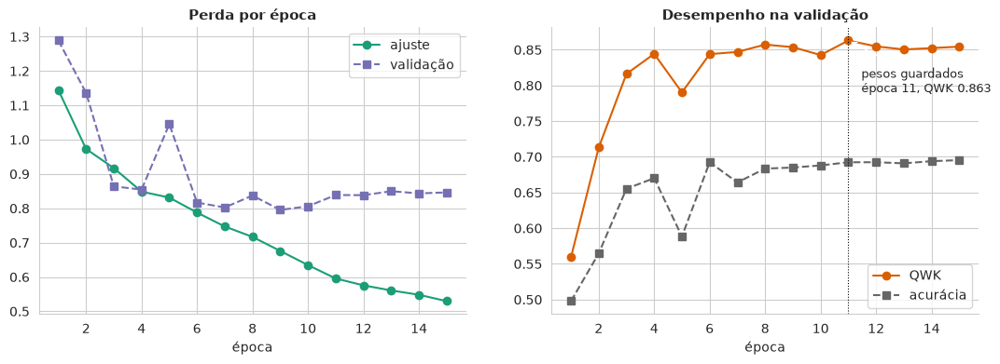

In [38]:
def plotar_historico(historico):
    melhor = historico.loc[historico["qwk_validacao"].idxmax()]
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
    eixos[0].plot(historico["epoca"], historico["perda_ajuste"], "o-", label="ajuste", color="#1B9E77")
    eixos[0].plot(historico["epoca"], historico["perda_validacao"], "s--", label="validação", color="#7570B3")
    eixos[0].set_title("Perda por época")
    eixos[0].legend()
    eixos[1].plot(historico["epoca"], historico["qwk_validacao"], "o-", color="#D95F02", label="QWK")
    eixos[1].plot(historico["epoca"], historico["acuracia_validacao"], "s--", color="#666666", label="acurácia")
    eixos[1].axvline(melhor["epoca"], color="black", lw=0.8, ls=":")
    eixos[1].annotate(f"pesos guardados\népoca {int(melhor['epoca'])}, QWK {melhor['qwk_validacao']:.3f}", (melhor["epoca"], melhor["qwk_validacao"]), xytext=(10, -40), textcoords="offset points", fontsize=9, arrowprops={"arrowstyle": "->"})
    eixos[1].set_title("Desempenho na validação")
    eixos[1].legend(loc="lower right")
    for eixo in eixos:
        eixo.set_xlabel("época")
    return fig


salvar_figura(plotar_historico(HISTORICO), "06_historico_ajuste")

### 6.3 Desempenho do extrator ajustado no teste

Embora o objetivo seja o embedding, e não a classificação, medir o desempenho da rede no teste mostra o quanto a camada escondida aprendeu sobre RD. A probabilidade de RD referável é a soma das probabilidades dos graus 2, 3 e 4.

In [39]:
def desempenho_no_teste(modelo, X, catalogo, indices, cfg, dispositivo):
    probabilidades = prever_probabilidades(modelo, X, indices, cfg, dispositivo)
    previsto = probabilidades.argmax(1)
    parte = catalogo.iloc[indices].assign(previsto=previsto, prob_referavel=probabilidades[:, cfg.limiar_referavel:].sum(1))
    linhas = {}
    for nome, sub in [("APTOS_2019", parte[parte["dataset"] == "APTOS_2019"]), ("FDR26", parte[parte["dataset"] == "FDR26"]), ("as duas bases", parte)]:
        linhas[nome] = {
            "imagens": len(sub),
            "QWK (5 graus)": cohen_kappa_score(sub["grau"], sub["previsto"], weights="quadratic"),
            "acurácia (5 graus)": accuracy_score(sub["grau"], sub["previsto"]),
            "AUC RD referável": roc_auc_score(sub["referavel"], sub["prob_referavel"]),
            "acurácia RD referável": accuracy_score(sub["referavel"], (sub["prob_referavel"] >= 0.5).astype(int)),
        }
    return pd.DataFrame(linhas).T, parte


TAB_TESTE, PREVISOES_TESTE = desempenho_no_teste(EXTRATOR_AJUSTADO, X_IMAGENS, CATALOGO, IDX_TESTE, CFG, DISPOSITIVO)
TAB_TESTE.round(3)

,imagens,QWK (5 graus),acurácia (5 graus),AUC RD referável,acurácia RD referável
APTOS_2019,876.0,0.882,0.821,0.978,0.920
FDR26,695.0,0.757,0.542,0.914,0.836
as duas bases,1571.0,0.844,0.698,0.953,0.883


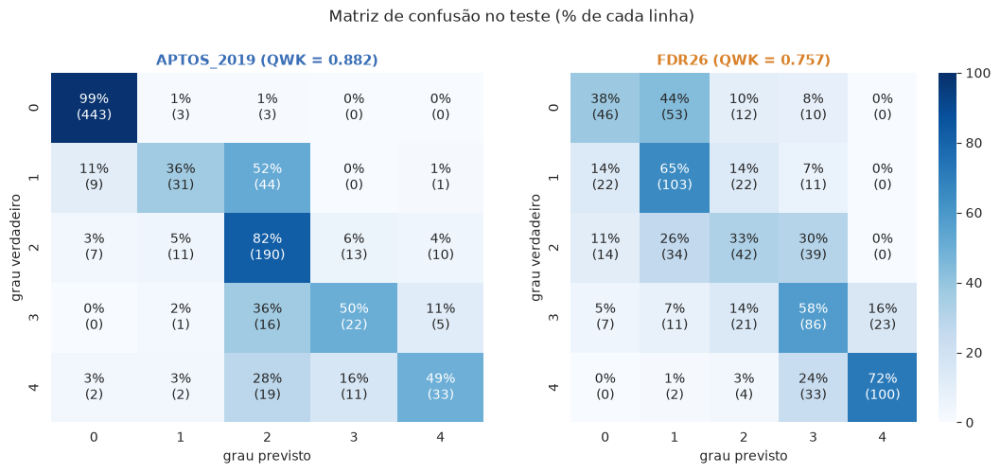

In [40]:
def plotar_confusao(previsoes):
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
    rotulos = [f"{g}" for g in range(5)]
    for eixo, base in zip(eixos, BASES):
        parte = previsoes[previsoes["dataset"] == base]
        matriz = confusion_matrix(parte["grau"], parte["previsto"], labels=range(5))
        percentual = 100 * matriz / matriz.sum(1, keepdims=True).clip(1)
        anotacao = np.array([[f"{percentual[i, j]:.0f}%\n({matriz[i, j]})" for j in range(5)] for i in range(5)])
        sns.heatmap(percentual, annot=anotacao, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=eixo is eixos[1], xticklabels=rotulos, yticklabels=rotulos, ax=eixo)
        qwk = cohen_kappa_score(parte["grau"], parte["previsto"], weights="quadratic")
        eixo.set_title(f"{base} (QWK = {qwk:.3f})", color=CORES_BASE[base])
        eixo.set_xlabel("grau previsto")
        eixo.set_ylabel("grau verdadeiro")
    fig.suptitle("Matriz de confusão no teste (% de cada linha)", y=1.02)
    return fig


salvar_figura(plotar_confusao(PREVISOES_TESTE), "06_matriz_confusao")

O extrator ajustado aprendeu bem a RD. No teste, o QWK é 0,882 no APTOS e 0,757 no FDR26, e a AUC de RD referável é 0,978 e 0,914. As melhores soluções da competição APTOS chegaram a cerca de 0,93 de QWK no placar privado [4,5]. Os números não são diretamente comparáveis, porque o teste da competição é outro, mas mostram que uma rede de 1,5 milhão de parâmetros com imagens de 224 pixels chega perto.

A matriz de confusão mostra onde estão os erros. No APTOS, quase todo olho sem RD é reconhecido (99%), mas a RD leve é confundida com a moderada em 52% dos casos, e os graus 3 e 4 são muitas vezes rebaixados para 2. É o reflexo do desbalanceamento: os graus raros são puxados para o grau 2, o mais comum entre os doentes. No FDR26, os erros se concentram nos graus 0 a 2: 44% dos olhos sem RD são classificados como RD leve, e a RD moderada se espalha entre 1, 2 e 3. Graus vizinhos no FDR26 são mais difíceis de separar, o que pode refletir a diferença de critério entre ALFEDIAM e ICDR e os rótulos conflitantes da Seção 4.1.

O histórico mostra que a validação estabiliza a partir da época 6. Os pesos guardados são os da época 11 (QWK 0,863 na validação). A perda de ajuste continua caindo enquanto a de validação para, um começo de sobreajuste, sem prejuízo do QWK.

## 7. A matriz de características

### 7.1 Extração dos embeddings

Todas as imagens (treino e teste) passam pelas duas versões do extrator. Para cada uma guardamos a saída da última camada escondida. O resultado são duas matrizes E, com uma linha por imagem e 1.024 colunas.

In [41]:
@torch.no_grad()
def extrair_embeddings(modelo, X, cfg, dispositivo):
    modelo.eval().to(dispositivo)
    partes = [modelo.embedding(para_tensor(X[i:i + 2 * cfg.tamanho_lote], dispositivo)).cpu().numpy() for i in range(0, len(X), 2 * cfg.tamanho_lote)]
    return np.concatenate(partes).astype(np.float32)


def obter_embeddings(nome, modelo, X, cfg, dispositivo):
    arquivo = CAMINHOS.cache / f"embeddings_{nome}_{chave_de_cache(*CATALOGO['arquivo'], nome, cfg.tamanho_imagem, cfg.semente, cfg.epocas_ajuste)}.npy"
    if arquivo.exists():
        return np.load(arquivo)
    inicio = time.time()
    matriz = extrair_embeddings(modelo, X, cfg, dispositivo)
    np.save(arquivo, matriz)
    print(f"{nome}: {matriz.shape[0]} embeddings extraídos em {time.time() - inicio:.0f}s")
    return matriz


E = {
    "ImageNet": obter_embeddings("ImageNet", ExtratorLeve(), X_IMAGENS, CFG, DISPOSITIVO),
    "Ajustado": obter_embeddings("Ajustado", EXTRATOR_AJUSTADO, X_IMAGENS, CFG, DISPOSITIVO),
}
pd.DataFrame({
    nome: {
        "imagens (linhas)": matriz.shape[0],
        "dimensões (colunas)": matriz.shape[1],
        "memória (MB)": round(matriz.nbytes / 1024 ** 2, 1),
        "valor mínimo": round(float(matriz.min()), 3),
        "valor máximo": round(float(matriz.max()), 3),
        "% de ativações ≤ 0": round(100 * float((matriz <= 0).mean()), 1),
    }
    for nome, matriz in E.items()
})

,ImageNet,Ajustado
imagens (linhas),6281.000,6281.000
dimensões (colunas),1024.000,1024.000
memória (MB),24.500,24.500
valor mínimo,-0.375,-0.375
valor máximo,6.375,8.020
% de ativações ≤ 0,60.100,68.700


In [42]:
pd.DataFrame(E["Ajustado"][:6, :10], columns=[f"dim_{i}" for i in range(10)], index=CATALOGO["arquivo"][:6]).round(3)

,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9
arquivo,,,,,,,,,,
000c1434d8d7.png,1.626,-0.306,-0.129,-0.375,0.242,-0.375,-0.347,0.064,-0.279,-0.091
001639a390f0.png,-0.149,-0.180,-0.306,-0.364,0.642,1.388,-0.368,-0.272,-0.300,-0.359
0024cdab0c1e.png,1.860,-0.312,0.087,-0.304,0.148,0.011,-0.360,-0.152,0.603,1.541
002c21358ce6.png,-0.184,-0.181,0.433,-0.166,-0.097,-0.316,-0.362,-0.358,1.183,0.118
005b95c28852.png,-0.373,-0.373,-0.182,-0.254,-0.317,0.495,-0.000,-0.142,0.034,-0.298
0083ee8054ee.png,-0.206,1.464,-0.254,-0.329,-0.225,3.680,-0.372,-0.037,-0.310,-0.179


### 7.2 A matriz vista como imagem

Cada linha é uma imagem e cada coluna, uma das 1.024 dimensões. Mostramos 400 imagens sorteadas, ordenadas por base e por grau, e as 120 dimensões que mais variam. As cores são o valor padronizado da ativação. As faixas à esquerda indicam a base e o grau de cada linha. Se a matriz tiver blocos horizontais que acompanham as faixas, o embedding codifica aquela informação.

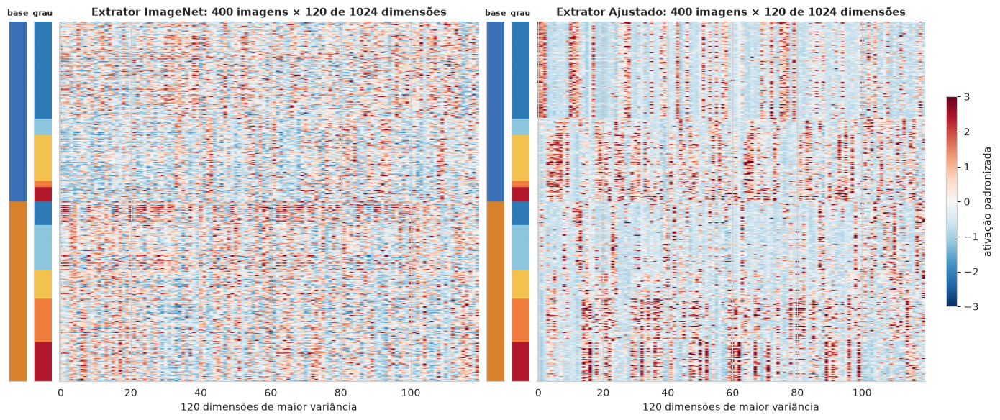

In [43]:
def plotar_matriz_caracteristicas(E, catalogo, n=400, dimensoes=120, semente=CFG.semente):
    amostra = catalogo.groupby("dataset", group_keys=False).sample(n // 2, random_state=semente).sort_values(["dataset", "grau"])
    linhas = amostra.index.to_numpy()
    fig = plt.figure(figsize=(17, 6.5))
    grade = GridSpec(1, 2 * 3, width_ratios=[0.25, 0.25, 6] * 2, wspace=0.05, figure=fig)
    for i, nome in enumerate(EXTRATORES):
        matriz = E[nome][linhas]
        colunas = np.argsort(E[nome].std(0))[::-1][:dimensoes]
        padronizada = np.clip((matriz[:, colunas] - E[nome][:, colunas].mean(0)) / (E[nome][:, colunas].std(0) + 1e-8), -3, 3)
        faixa_base = fig.add_subplot(grade[0, 3 * i])
        faixa_grau = fig.add_subplot(grade[0, 3 * i + 1])
        principal = fig.add_subplot(grade[0, 3 * i + 2])
        cores_base = np.array([to_rgb(CORES_BASE[b]) for b in amostra["dataset"]])[:, None, :]
        cores_grau = np.array([to_rgb(CORES_GRAU[g]) for g in amostra["grau"]])[:, None, :]
        faixa_base.imshow(cores_base, aspect="auto")
        faixa_grau.imshow(cores_grau, aspect="auto")
        imagem = principal.imshow(padronizada, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
        for eixo in (faixa_base, faixa_grau):
            eixo.set_xticks([])
            eixo.set_yticks([])
        faixa_base.set_title("base", fontsize=8)
        faixa_grau.set_title("grau", fontsize=8)
        principal.set_yticks([])
        principal.set_xlabel(f"{dimensoes} dimensões de maior variância")
        principal.set_title(f"Extrator {nome}: {matriz.shape[0]} imagens × {dimensoes} de {E[nome].shape[1]} dimensões")
    fig.colorbar(imagem, ax=principal, fraction=0.025, label="ativação padronizada")
    return fig


salvar_figura(plotar_matriz_caracteristicas(E, CATALOGO), "07_matriz_caracteristicas")

A matriz do extrator ImageNet tem um único corte visível, na fronteira entre APTOS e FDR26. Dentro de cada base, o padrão é homogêneo ao longo dos graus. A rede sem ajuste distingue as bases, mas não a doença.

A matriz do extrator Ajustado tem blocos nítidos, e eles mudam com o grau dentro de cada base. Os olhos sem RD do APTOS ativam um conjunto de dimensões (colunas vermelhas no topo), e os graus 2 a 4 do APTOS ativam outro. No FDR26, as dimensões ativas mudam dos graus 0 e 1 para os graus 3 e 4. O ajuste fino reorganizou a camada escondida em torno da doença, mas cada base continua com o seu próprio conjunto de dimensões.

Os embeddings são esparsos: 60% (ImageNet) e 69% (Ajustado) das ativações são menores ou iguais a zero, efeito da hard-swish, que zera ou quase zera os valores negativos.

### 7.3 Preparação para a clusterização

Antes de agrupar, cada matriz passa por três etapas, todas aprendidas só com o treino:

1. Normalização L2: cada linha passa a ter comprimento 1. Importa a direção do vetor, e não a intensidade geral da ativação.
2. Padronização: cada coluna fica com média 0 e desvio 1, para nenhuma dimensão dominar a distância.
3. PCA [21]: as 1.024 dimensões viram 50 componentes que concentram a maior parte da variação. Isso reduz ruído e acelera os algoritmos.

O resultado, a matriz Z, é o que de fato entra no K-Means.

In [44]:
def preparar_para_clusterizar(matriz, idx_treino, cfg):
    transformador = make_pipeline(Normalizer(), StandardScaler(), PCA(cfg.n_componentes_pca, random_state=cfg.semente)).fit(matriz[idx_treino])
    return transformador.transform(matriz), transformador


def variancia_acumulada(matriz, idx_treino, semente):
    completo = PCA(random_state=semente).fit(make_pipeline(Normalizer(), StandardScaler()).fit_transform(matriz[idx_treino]))
    return 100 * np.cumsum(completo.explained_variance_ratio_)


Z, TRANSFORMADORES, VARIANCIA = {}, {}, {}
for nome in EXTRATORES:
    Z[nome], TRANSFORMADORES[nome] = preparar_para_clusterizar(E[nome], IDX_TREINO, CFG)
    VARIANCIA[nome] = variancia_acumulada(E[nome], IDX_TREINO, CFG.semente)

pd.DataFrame({
    nome: {
        "dimensões antes": E[nome].shape[1],
        "dimensões depois": Z[nome].shape[1],
        "variância preservada (%)": round(VARIANCIA[nome][CFG.n_componentes_pca - 1], 1),
        "componentes para 80% da variância": int(np.searchsorted(VARIANCIA[nome], 80) + 1),
        "componentes para 95% da variância": int(np.searchsorted(VARIANCIA[nome], 95) + 1),
    }
    for nome in EXTRATORES
})

,ImageNet,Ajustado
dimensões antes,1024.0,1024.000000
dimensões depois,50.0,50.000000
variância preservada (%),72.0,63.200001
componentes para 80% da variância,94.0,171.000000
componentes para 95% da variância,377.0,525.000000


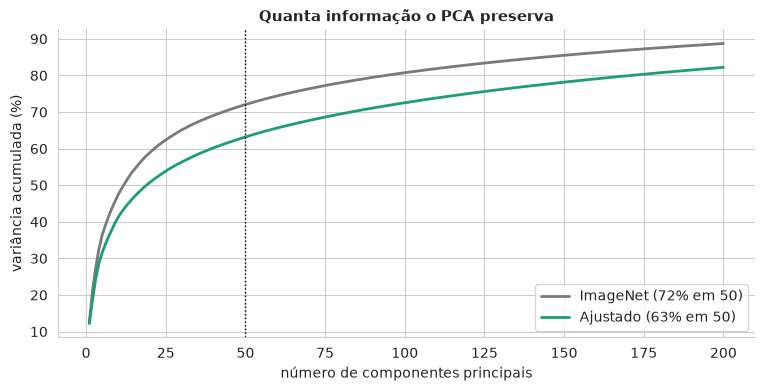

In [45]:
def plotar_variancia_pca(variancia):
    fig, eixo = plt.subplots(figsize=(9, 4))
    for nome in EXTRATORES:
        acumulada = variancia[nome]
        eixo.plot(np.arange(1, 201), acumulada[:200], color=CORES_EXTRATOR[nome], lw=2, label=f"{nome} ({acumulada[CFG.n_componentes_pca - 1]:.0f}% em {CFG.n_componentes_pca})")
    eixo.axvline(CFG.n_componentes_pca, color="black", ls=":", lw=1)
    eixo.set_xlabel("número de componentes principais")
    eixo.set_ylabel("variância acumulada (%)")
    eixo.set_title("Quanta informação o PCA preserva")
    eixo.legend()
    return fig


salvar_figura(plotar_variancia_pca(VARIANCIA), "07_variancia_pca")

Com 50 componentes, o PCA preserva 72% da variância no extrator ImageNet e 63% no Ajustado. O Ajustado precisa de mais componentes para a mesma fração (171 contra 94 para chegar a 80%), porque o ajuste fino espalha a informação por mais dimensões. Os primeiros componentes, que concentram a estrutura principal (base e grau), estão incluídos nos dois casos, e por isso 50 componentes bastam para a clusterização. O PCA também descarta o ruído das dimensões de baixa variância, que atrapalharia as distâncias do K-Means.

## 8. Clusterização com K = 2 a 8

Ajustamos um K-Means [22,23] para cada K, na matriz Z do treino, e encaixamos as imagens de teste no centro mais próximo. Para cada K, medimos dois tipos de indicador.

Indicadores internos, que dizem se os grupos são bem formados, medidos no treino:

| Indicador | Pergunta | Melhor |
|---|---|---|
| inércia | quão apertados estão os grupos? Sempre cai com K | procurar o cotovelo |
| silhouette [27] (−1 a 1) | cada imagem está mais perto do próprio grupo que do vizinho? | maior |
| Davies-Bouldin [28] | os grupos se sobrepõem? | menor |
| Calinski-Harabasz [29] | os grupos estão afastados em comparação com o espalhamento interno? | maior |
| estabilidade | com outras 80% das imagens, os grupos saem iguais? (ARI médio entre repetições) | perto de 1 |

Indicadores externos, que dizem o que os grupos significam, medidos no teste:

| Indicador | Pergunta |
|---|---|
| ARI [30] e NMI [31] × grau | os clusters acompanham os 5 graus de RD? |
| ARI × referável | os clusters separam RD referável de não referável? |
| ARI e NMI × base | os clusters separam APTOS de FDR26? |

O ARI vale 1 quando duas partições são idênticas e perto de 0 quando a coincidência é só acaso. O NMI vai de 0 a 1 e é menos sensível ao tamanho dos grupos.

In [46]:
def estabilidade_kmeans(Z, k, repeticoes, semente):
    rng = np.random.default_rng(semente)
    tamanho = int(0.8 * len(Z))
    aris = []
    for _ in range(repeticoes):
        a = rng.choice(len(Z), tamanho, replace=False)
        b = rng.choice(len(Z), tamanho, replace=False)
        modelo_a = KMeans(k, n_init=3, random_state=int(rng.integers(1_000_000))).fit(Z[a])
        modelo_b = KMeans(k, n_init=3, random_state=int(rng.integers(1_000_000))).fit(Z[b])
        aris.append(adjusted_rand_score(modelo_a.predict(Z), modelo_b.predict(Z)))
    return float(np.mean(aris))


def avaliar_k(Z, catalogo, idx_treino, idx_teste, cfg):
    treino, teste = catalogo.iloc[idx_treino], catalogo.iloc[idx_teste]
    modelos, linhas = {}, []
    for k in cfg.lista_k:
        modelo = KMeans(k, n_init=10, random_state=cfg.semente).fit(Z[idx_treino])
        previsto = modelo.predict(Z[idx_teste])
        modelos[k] = modelo
        linhas.append({
            "k": k,
            "inercia": modelo.inertia_,
            "silhouette": silhouette_score(Z[idx_treino], modelo.labels_),
            "davies_bouldin": davies_bouldin_score(Z[idx_treino], modelo.labels_),
            "calinski_harabasz": calinski_harabasz_score(Z[idx_treino], modelo.labels_),
            "estabilidade": estabilidade_kmeans(Z[idx_treino], k, cfg.repeticoes_estabilidade, cfg.semente),
            "menor_cluster_%": 100 * np.bincount(modelo.labels_).min() / len(idx_treino),
            "ARI_grau": adjusted_rand_score(teste["grau"], previsto),
            "NMI_grau": normalized_mutual_info_score(teste["grau"], previsto),
            "ARI_referavel": adjusted_rand_score(teste["referavel"], previsto),
            "ARI_base": adjusted_rand_score(teste["dataset"], previsto),
            "NMI_base": normalized_mutual_info_score(teste["dataset"], previsto),
        })
    return modelos, pd.DataFrame(linhas)

In [47]:
MODELOS_K, TAB_K = {}, {}
for nome in EXTRATORES:
    inicio = time.time()
    MODELOS_K[nome], TAB_K[nome] = avaliar_k(Z[nome], CATALOGO, IDX_TREINO, IDX_TESTE, CFG)
    print(f"{nome}: {len(CFG.lista_k)} valores de K avaliados em {time.time() - inicio:.0f}s")

TAB_K_TODOS = pd.concat(TAB_K, names=["extrator"]).reset_index(level=0)
display(TAB_K["ImageNet"].set_index("k").round(3).style.set_caption("Extrator ImageNet"))
display(TAB_K["Ajustado"].set_index("k").round(3).style.set_caption("Extrator Ajustado"))

ImageNet: 7 valores de K avaliados em 5s


Ajustado: 7 valores de K avaliados em 4s


,inercia,silhouette,davies_bouldin,calinski_harabasz,estabilidade,menor_cluster_%,ARI_grau,NMI_grau,ARI_referavel,ARI_base,NMI_base
k,,,,,,,,,,,
2,3045648.000000,0.121000,2.519000,662.419000,0.967000,39.002000,0.096000,0.117000,0.193000,0.009000,0.010000
3,2721819.000000,0.137000,2.275000,650.544000,0.985000,27.304000,0.113000,0.117000,0.111000,0.299000,0.327000
4,2565433.250000,0.146000,2.154000,555.660000,0.864000,8.875000,0.120000,0.131000,0.110000,0.233000,0.299000
5,2408969.250000,0.144000,2.036000,520.117000,0.736000,8.811000,0.128000,0.161000,0.099000,0.317000,0.394000
6,2268626.000000,0.137000,2.080000,499.940000,0.930000,8.811000,0.157000,0.179000,0.107000,0.238000,0.356000
7,2178794.250000,0.142000,2.031000,466.019000,0.946000,8.875000,0.155000,0.212000,0.099000,0.269000,0.442000
8,2095023.375000,0.152000,1.913000,442.188000,0.852000,2.675000,0.159000,0.212000,0.101000,0.267000,0.444000


,inercia,silhouette,davies_bouldin,calinski_harabasz,estabilidade,menor_cluster_%,ARI_grau,NMI_grau,ARI_referavel,ARI_base,NMI_base
k,,,,,,,,,,,
2,2578158.750000,0.154000,2.321000,856.533000,0.973000,48.344000,0.322000,0.338000,0.531000,0.017000,0.013000
3,2299550.250000,0.170000,2.198000,765.197000,0.862000,24.671000,0.338000,0.389000,0.415000,0.271000,0.354000
4,2076416.250000,0.187000,2.003000,733.401000,0.989000,22.845000,0.415000,0.412000,0.291000,0.442000,0.547000
5,1958359.875000,0.170000,1.966000,653.994000,0.876000,14.544000,0.279000,0.387000,0.215000,0.354000,0.486000
6,1860346.875000,0.170000,1.978000,600.209000,0.842000,10.340000,0.290000,0.392000,0.184000,0.323000,0.465000
7,1786589.875000,0.173000,2.005000,553.072000,0.750000,6.518000,0.318000,0.386000,0.192000,0.300000,0.469000
8,1698276.125000,0.191000,1.727000,533.538000,0.812000,2.654000,0.245000,0.375000,0.156000,0.287000,0.451000


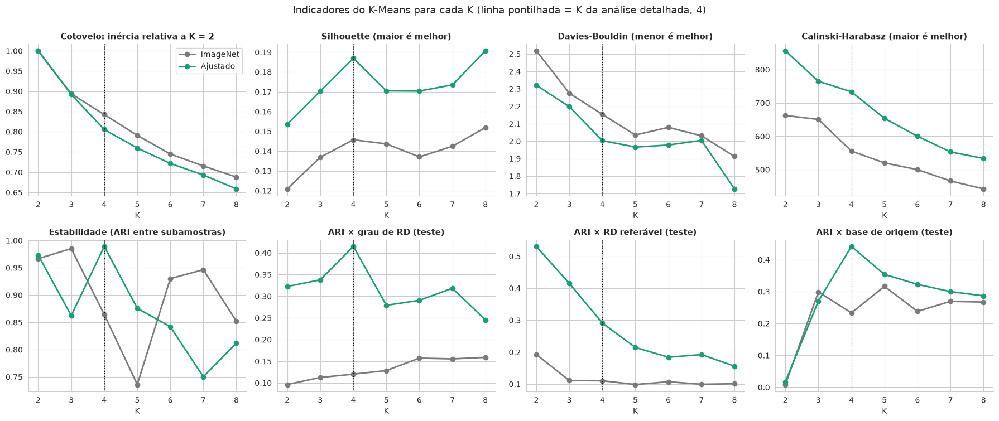

In [48]:
def plotar_metricas_k(tab_todos):
    paineis = [
        ("inercia_relativa", "Cotovelo: inércia relativa a K = 2"),
        ("silhouette", "Silhouette (maior é melhor)"),
        ("davies_bouldin", "Davies-Bouldin (menor é melhor)"),
        ("calinski_harabasz", "Calinski-Harabasz (maior é melhor)"),
        ("estabilidade", "Estabilidade (ARI entre subamostras)"),
        ("ARI_grau", "ARI × grau de RD (teste)"),
        ("ARI_referavel", "ARI × RD referável (teste)"),
        ("ARI_base", "ARI × base de origem (teste)"),
    ]
    dados = tab_todos.assign(inercia_relativa=tab_todos.groupby("extrator")["inercia"].transform(lambda s: s / s.iloc[0]))
    fig, eixos = plt.subplots(2, 4, figsize=(18, 7.5))
    for eixo, (coluna, titulo) in zip(eixos.ravel(), paineis):
        for nome in EXTRATORES:
            parte = dados[dados["extrator"] == nome]
            eixo.plot(parte["k"], parte[coluna], "o-", color=CORES_EXTRATOR[nome], label=nome, lw=2)
        eixo.set_title(titulo)
        eixo.set_xlabel("K")
        eixo.set_xticks(CFG.lista_k)
        if CFG.k_analise in CFG.lista_k:
            eixo.axvline(CFG.k_analise, color="black", ls=":", lw=0.8)
    eixos[0, 0].legend()
    fig.suptitle(f"Indicadores do K-Means para cada K (linha pontilhada = K da análise detalhada, {CFG.k_analise})", y=1.0, fontsize=13)
    fig.tight_layout()
    return fig


salvar_figura(plotar_metricas_k(TAB_K_TODOS), "08_metricas_por_k")

Três padrões aparecem.

Primeiro, os indicadores internos são baixos em termos absolutos: a silhouette fica entre 0,12 e 0,19. Os grupos de gravidade não formam ilhas bem separadas: dentro de cada base, os embeddings formam uma nuvem contínua com regiões mais densas, o que é comum em imagens médicas. As ilhas nítidas do UMAP (Seção 10) são as bases e as câmeras. O cotovelo da inércia não tem um ponto de quebra claro.

Segundo, o extrator Ajustado tem silhouette, Davies-Bouldin e Calinski-Harabasz melhores que os do ImageNet em todos os K, e é muito melhor nos indicadores externos. A estabilidade é parecida nos dois, e oscila entre 0,74 e 0,99. Com K = 4, o ARI contra o grau no teste é de 0,415 no Ajustado e 0,120 no ImageNet. O ARI contra a RD referável é máximo com K = 2 (0,531 no Ajustado), porque dois clusters coincidem com a divisão binária.

Terceiro, nos dois extratores, com K = 2 o ARI contra a base é quase zero, e a partir de K = 3 ele sobe para 0,23 a 0,44. No Ajustado, a primeira grande divisão do espaço é de gravidade e atravessa as duas bases (com K = 2, um cluster tem 9% de RD referável e o outro, 86%), e a base só aparece a partir de K = 3.

Para a análise detalhada escolhemos K = 4. No extrator Ajustado, K = 4 tem a maior estabilidade (0,989) e o maior ARI contra o grau (0,415), a silhouette (0,187) é praticamente igual à de K = 8 (0,191), e o menor cluster ainda tem 23% das imagens. K = 8 tem um cluster com só 2,7% das imagens e estabilidade de 0,81. A escolha olhou também o ARI contra o grau medido no teste, e por isso K = 4 não deve ser lido como uma escolha cega aos rótulos. Para comparar os extratores, o mesmo K é usado no ImageNet, onde K = 4 não se destaca (estabilidade de 0,86, contra 0,99 em K = 3).

### 8.1 A partição usada na análise detalhada

As seções seguintes usam K = 4 (definido em Config.k_analise), pelos motivos discutidos acima. Os clusters são renumerados em ordem crescente de grau médio no treino: C1 é o cluster com o menor grau médio e C4, o de maior. Assim, os nomes dos clusters têm o mesmo sentido nas duas versões do extrator.

In [49]:
@dataclass
class Particao:
    k: int
    rotulos: np.ndarray
    centros: np.ndarray


def montar_particao(modelo, Z, idx_treino, graus):
    rotulos_treino = modelo.labels_
    ordem = np.argsort([graus[idx_treino][rotulos_treino == r].mean() for r in range(modelo.n_clusters)])
    novo_nome = np.empty(modelo.n_clusters, dtype=int)
    novo_nome[ordem] = np.arange(modelo.n_clusters)
    rotulos = novo_nome[modelo.predict(Z)]
    rotulos[idx_treino] = novo_nome[rotulos_treino]
    return Particao(modelo.n_clusters, rotulos, modelo.cluster_centers_[ordem])


K = CFG.k_analise
PARTICOES = {nome: montar_particao(MODELOS_K[nome][K], Z[nome], IDX_TREINO, Y_GRAU) for nome in EXTRATORES}
pd.DataFrame({
    nome: pd.Series(particao.rotulos).map(nome_cluster).value_counts().sort_index()
    for nome, particao in PARTICOES.items()
}).rename_axis(f"cluster (K = {K})").T.assign(total=len(CATALOGO))

cluster (K = 4),C1,C2,C3,C4,total
ImageNet,1973,576,2516,1216,6281
Ajustado,1829,1524,1516,1412,6281


### 8.2 Diagrama de silhouette

Cada barra horizontal é uma imagem de treino, e o comprimento é o seu valor de silhouette. Barras longas e positivas indicam imagens bem encaixadas no próprio cluster. Barras negativas indicam imagens que estariam mais perto de outro cluster. A linha vermelha é a média.

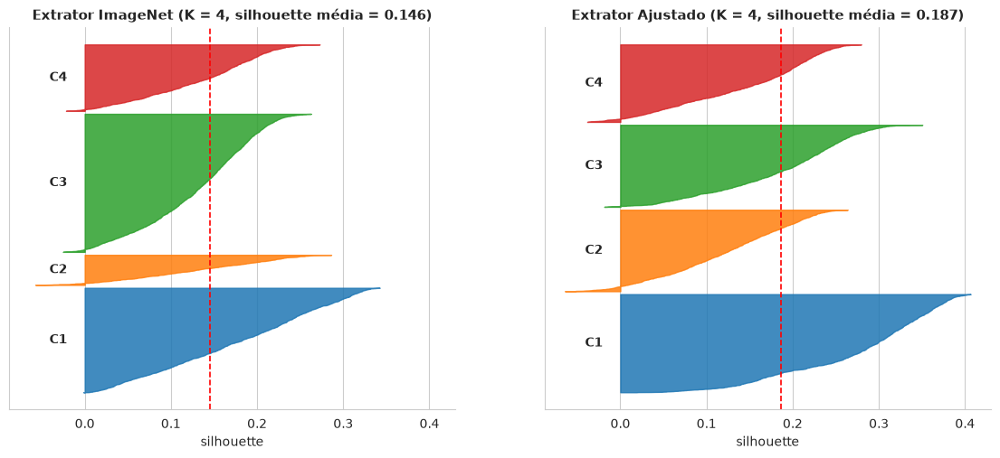

In [50]:
def plotar_silhueta(Z, particoes, idx_treino):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
    for eixo, nome in zip(eixos, EXTRATORES):
        rotulos = particoes[nome].rotulos[idx_treino]
        valores = silhouette_samples(Z[nome][idx_treino], rotulos)
        base_y = 0
        for r in range(particoes[nome].k):
            ordenados = np.sort(valores[rotulos == r])
            eixo.fill_betweenx(np.arange(base_y, base_y + len(ordenados)), 0, ordenados, color=PALETA_CLUSTERS[r], alpha=0.85)
            eixo.text(-0.02, base_y + len(ordenados) / 2, nome_cluster(r), ha="right", va="center", fontsize=10, weight="bold")
            base_y += len(ordenados) + 40
        eixo.axvline(valores.mean(), color="red", ls="--", lw=1.2)
        eixo.set_title(f"Extrator {nome} (K = {particoes[nome].k}, silhouette média = {valores.mean():.3f})")
        eixo.set_xlabel("silhouette")
        eixo.set_yticks([])
    return fig


salvar_figura(plotar_silhueta(Z, PARTICOES, IDX_TREINO), "08_diagrama_silhouette")

No Ajustado, C1 (APTOS sem RD) é o cluster mais bem definido, com silhouette média de 0,27, praticamente nenhuma imagem negativa e valores de até 0,4. É o único cluster do Ajustado com média acima de 0,25. Imagens com silhouette negativa aparecem sobretudo em C2 (6,2% das imagens do cluster) e C4 (4,3%), os clusters do FDR26, onde graus vizinhos se misturam. No ImageNet, as silhouettes médias são menores na maioria dos clusters, e C2, o menor, tem 6,5% de imagens negativas.

No total, só 2,7% das imagens do Ajustado e 1,8% das do ImageNet têm silhouette negativa, mas a média é baixa nos dois (0,19 e 0,15). As fronteiras são difusas: os clusters são regiões de uma nuvem contínua, e não grupos isolados.

## 9. Comparação entre algoritmos

Aplicamos, à mesma matriz Z e com os mesmos valores de K, outros dois algoritmos que recebem K: a mistura de gaussianas (GMM) por EM [24], que admite grupos elípticos e dá a cada imagem uma probabilidade de pertencer a cada grupo, e o aglomerativo de Ward [25], que junta as imagens mais parecidas de baixo para cima. Um quarto algoritmo, o HDBSCAN [26], decide sozinho quantos grupos existem e deixa de fora, como ruído, as imagens que não se encaixam em nenhum.

Se os algoritmos concordam, a estrutura encontrada não depende do método. O K-Means segue como algoritmo principal porque classifica uma imagem nova de forma direta, pelo centro mais próximo, o que é o comportamento esperado de um roteador.

In [51]:
def criar_algoritmo(nome, k, semente):
    if nome == "K-Means":
        return KMeans(k, n_init=10, random_state=semente)
    if nome == "GMM":
        return GaussianMixture(k, covariance_type="full", n_init=2, random_state=semente)
    return AgglomerativeClustering(k, linkage="ward")


def comparar_algoritmos(Z, catalogo, cfg):
    linhas = []
    for nome in ("K-Means", "GMM", "Ward"):
        for k in cfg.lista_k:
            rotulos = criar_algoritmo(nome, k, cfg.semente).fit_predict(Z)
            linhas.append({
                "algoritmo": nome, "k": k,
                "silhouette": silhouette_score(Z, rotulos),
                "davies_bouldin": davies_bouldin_score(Z, rotulos),
                "ARI_grau": adjusted_rand_score(catalogo["grau"], rotulos),
                "ARI_base": adjusted_rand_score(catalogo["dataset"], rotulos),
                "rotulos": rotulos,
            })
    return pd.DataFrame(linhas)


def concordancia_com_kmeans(tabela, k):
    referencia = tabela[(tabela["algoritmo"] == "K-Means") & (tabela["k"] == k)]["rotulos"].iloc[0]
    return {nome: adjusted_rand_score(referencia, tabela[(tabela["algoritmo"] == nome) & (tabela["k"] == k)]["rotulos"].iloc[0]) for nome in ("GMM", "Ward")}


def rodar_hdbscan(Z, catalogo):
    rotulos = HDBSCAN(min_cluster_size=50, min_samples=10).fit_predict(Z)
    validos = rotulos >= 0
    resumo = {"clusters encontrados": len(set(rotulos[validos])), "% de ruído": round(100 * (~validos).mean(), 1)}
    if resumo["clusters encontrados"] > 1:
        resumo["silhouette (sem ruído)"] = silhouette_score(Z[validos], rotulos[validos])
        resumo["ARI × grau (sem ruído)"] = adjusted_rand_score(catalogo["grau"][validos], rotulos[validos])
        resumo["ARI × base (sem ruído)"] = adjusted_rand_score(catalogo["dataset"][validos], rotulos[validos])
    return resumo


TREINO = CATALOGO.iloc[IDX_TREINO].reset_index(drop=True)
TAB_ALGORITMOS = {nome: comparar_algoritmos(Z[nome][IDX_TREINO], TREINO, CFG) for nome in EXTRATORES}
display(pd.DataFrame({nome: concordancia_com_kmeans(TAB_ALGORITMOS[nome], K) for nome in EXTRATORES}).round(3).rename_axis(f"ARI contra o K-Means (K = {K})"))
display(pd.DataFrame({nome: rodar_hdbscan(Z[nome][IDX_TREINO], TREINO) for nome in EXTRATORES}).round(3).rename_axis("HDBSCAN"))

,ImageNet,Ajustado
ARI contra o K-Means (K = 4),,
GMM,0.502,0.883
Ward,0.566,0.840


,ImageNet,Ajustado
HDBSCAN,,
clusters encontrados,3.000,9.000
% de ruído,36.600,43.200
silhouette (sem ruído),0.187,0.288
ARI × grau (sem ruído),0.004,0.543
ARI × base (sem ruído),0.002,0.325


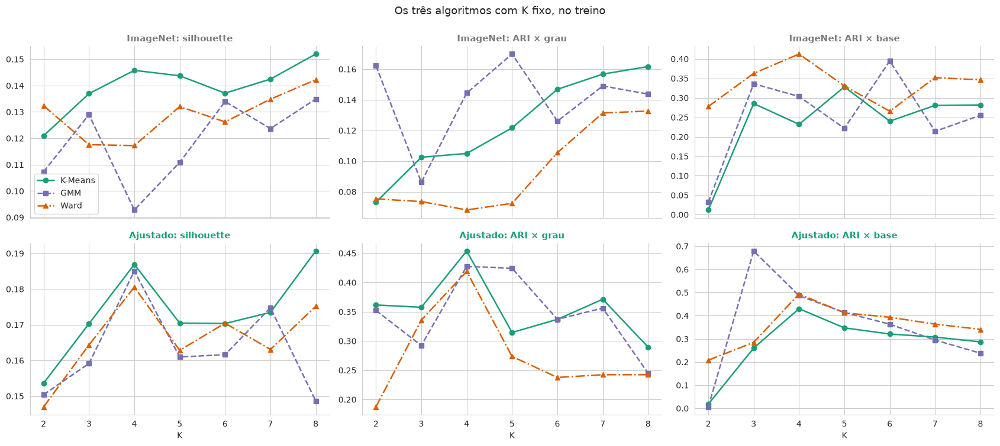

In [52]:
def plotar_algoritmos(tabelas):
    fig, eixos = plt.subplots(2, 3, figsize=(17, 7.5), sharex=True)
    estilos = {"K-Means": ("o-", "#1B9E77"), "GMM": ("s--", "#7570B3"), "Ward": ("^-.", "#D95F02")}
    for linha, nome in zip(eixos, EXTRATORES):
        for eixo, coluna, titulo in zip(linha, ("silhouette", "ARI_grau", "ARI_base"), ("silhouette", "ARI × grau", "ARI × base")):
            for algoritmo, (marcador, cor) in estilos.items():
                parte = tabelas[nome][tabelas[nome]["algoritmo"] == algoritmo]
                eixo.plot(parte["k"], parte[coluna], marcador, color=cor, label=algoritmo, lw=1.8)
            eixo.set_title(f"{nome}: {titulo}", color=CORES_EXTRATOR[nome])
            eixo.set_xticks(CFG.lista_k)
    eixos[0, 0].legend()
    for eixo in eixos[1]:
        eixo.set_xlabel("K")
    fig.suptitle("Os três algoritmos com K fixo, no treino", y=1.0, fontsize=13)
    fig.tight_layout()
    return fig


salvar_figura(plotar_algoritmos(TAB_ALGORITMOS), "09_comparacao_algoritmos")

No extrator Ajustado, os três algoritmos concordam: com K = 4, o ARI contra o K-Means é 0,883 para o GMM e 0,840 para o Ward, e os três têm o maior ARI × grau em K = 4 (curvas calculadas no treino). A estrutura encontrada não parece depender do algoritmo.

No ImageNet, a concordância é só moderada (0,50 e 0,57), e as curvas oscilam sem um K preferido. Os grupos dependem do método, sinal de que não há estrutura forte além da separação entre bases.

O HDBSCAN confirma a diferença. No ImageNet, ele encontra 3 grupos, deixa 37% das imagens como ruído, e os grupos não têm relação com o grau (ARI = 0,004). No Ajustado, ele encontra 9 grupos densos, com 43% de ruído, e o ARI com o grau chega a 0,543 nas imagens aceitas. Esse valor não é comparável ao ARI do K-Means no teste: o HDBSCAN foi avaliado no treino, que a rede ajustada viu com rótulos, e ignora as imagens de fronteira. O que ele mostra é que existem núcleos densos e clinicamente homogêneos, cercados de imagens de transição.

## 10. Visualização dos clusters

### 10.1 Mapa 2D com UMAP

O UMAP [32] projeta as 50 dimensões de Z em um plano, tentando manter perto o que está perto. O mesmo mapa é colorido de três formas: pelo cluster, pelo grau de RD e pela base. Se o painel do cluster se parece com o da base, os clusters são de aquisição. Se se parece com o do grau, são de gravidade.

O UMAP serve só para desenhar. A clusterização acontece em Z, com 50 dimensões, e distâncias grandes no mapa não devem ser lidas ao pé da letra.

In [53]:
MAPAS = {nome: umap.UMAP(n_neighbors=30, min_dist=0.15, random_state=CFG.semente).fit_transform(Z[nome]) for nome in EXTRATORES}

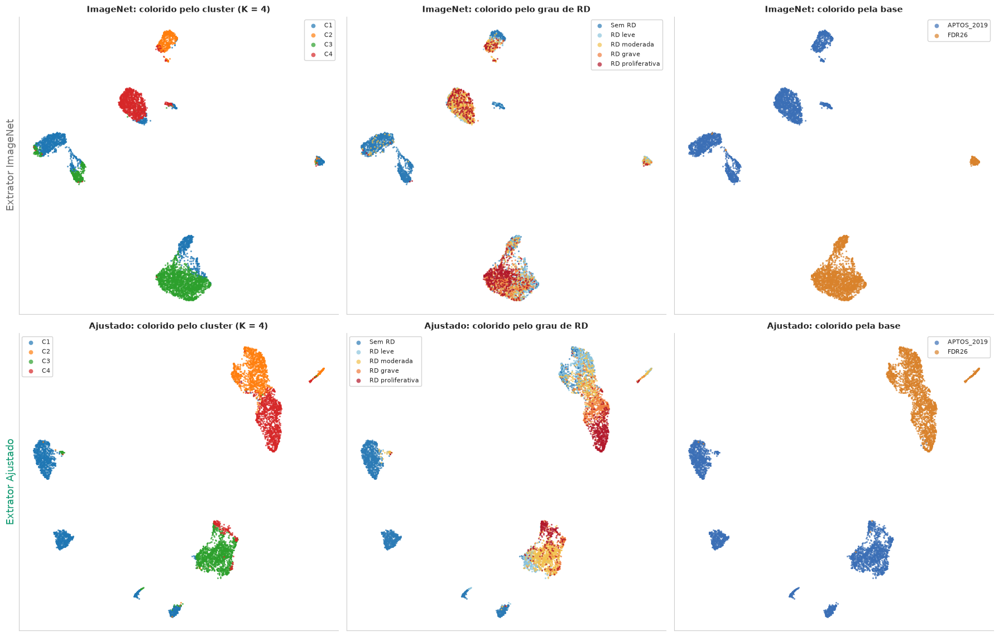

In [54]:
def dispersao_categorica(eixo, pontos, valores, cores, rotulos, tamanho=5):
    for valor in sorted(set(valores)):
        mascara = valores == valor
        eixo.scatter(pontos[mascara, 0], pontos[mascara, 1], s=tamanho, color=cores[valor], label=rotulos(valor), alpha=0.7, linewidths=0)
    eixo.set_xticks([])
    eixo.set_yticks([])
    eixo.legend(fontsize=8, markerscale=2.5, loc="best", framealpha=0.85)


def plotar_umap(mapas, particoes, catalogo):
    fig, eixos = plt.subplots(2, 3, figsize=(18, 11.5))
    graus, bases = catalogo["grau"].to_numpy(), catalogo["dataset"].to_numpy()
    for linha, nome in zip(eixos, EXTRATORES):
        rotulos = particoes[nome].rotulos
        dispersao_categorica(linha[0], mapas[nome], rotulos, dict(enumerate(PALETA_CLUSTERS)), nome_cluster)
        dispersao_categorica(linha[1], mapas[nome], graus, CORES_GRAU, lambda g: NOMES_GRAUS[g])
        dispersao_categorica(linha[2], mapas[nome], bases, CORES_BASE, str)
        linha[0].set_title(f"{nome}: colorido pelo cluster (K = {particoes[nome].k})")
        linha[1].set_title(f"{nome}: colorido pelo grau de RD")
        linha[2].set_title(f"{nome}: colorido pela base")
        linha[0].set_ylabel(f"Extrator {nome}", fontsize=13, color=CORES_EXTRATOR[nome])
    fig.tight_layout()
    return fig


salvar_figura(plotar_umap(MAPAS, PARTICOES, CATALOGO), "10_umap_cluster_grau_base")

Este é o resumo visual do notebook.

No extrator ImageNet (linha de cima), o mapa se divide em ilhas que correspondem às bases e, dentro do APTOS, a grupos de câmeras: o FDR26 forma uma ilha grande embaixo, e o APTOS se espalha por várias ilhas menores. Dentro de cada ilha os graus estão misturados, como mostra o painel do meio. Os clusters do K-Means seguem as ilhas.

No extrator Ajustado (linha de baixo), cada base continua em uma região própria, mas dentro dela as imagens se ordenam pelo grau. No FDR26 (direita), há um gradiente contínuo de cima para baixo, do azul (sem RD) ao vermelho escuro (proliferativa). No APTOS, os olhos sem RD formam ilhas separadas, e os graus 1 a 4 se reúnem em outra região. Os quatro clusters capturam exatamente isso: cada base dividida em menos grave e mais grave.

### 10.2 Como os grupos se dividem quando K cresce

O mesmo mapa, colorido pelos clusters de K = 2, 3, 5 e 6. A sequência mostra quais regiões se separam primeiro.

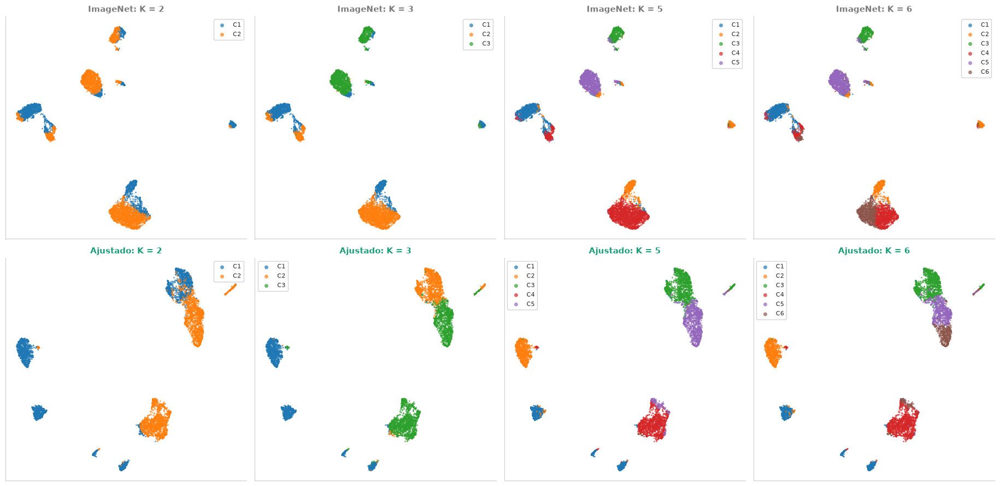

In [55]:
def plotar_umap_varios_k(mapas, modelos, Z, ks=(2, 3, 5, 6)):
    fig, eixos = plt.subplots(2, len(ks), figsize=(4.6 * len(ks), 9))
    for linha, nome in zip(eixos, EXTRATORES):
        for eixo, k in zip(linha, ks):
            particao = montar_particao(modelos[nome][k], Z[nome], IDX_TREINO, Y_GRAU)
            dispersao_categorica(eixo, mapas[nome], particao.rotulos, dict(enumerate(PALETA_CLUSTERS)), nome_cluster, tamanho=4)
            eixo.set_title(f"{nome}: K = {k}", color=CORES_EXTRATOR[nome])
    fig.tight_layout()
    return fig


salvar_figura(plotar_umap_varios_k(MAPAS, MODELOS_K, Z), "10_umap_varios_k")

Com K = 2, o extrator Ajustado divide o espaço em menos grave e mais grave, atravessando as duas bases: um cluster tem 9% de RD referável e o outro, 86%, e os dois misturam APTOS e FDR26 (37% e 51% de FDR26). Por isso o ARI contra a base é quase zero com K = 2 (Seção 8). Com K = 3, a base aparece: o APTOS sem RD (1.857 imagens, 1% de FDR26) e o FDR26 leve (1.555 imagens, 96% de FDR26) ganham clusters próprios, e o terceiro junta o APTOS doente com o FDR26 grave. Com K = 5 e 6, o Ajustado fatia o gradiente de gravidade do FDR26 em faixas.

No ImageNet, a divisão com K = 2 também mistura as duas bases (36% e 50% de FDR26). Com K = 3, um cluster concentra o FDR26 (82% de FDR26) e outro é quase só APTOS (1% de FDR26). Com K = 5 e 6, ele subdivide as ilhas de câmeras do APTOS e corta a ilha do FDR26 ao meio.

Aumentar K faz os clusters descreverem cada vez mais as medidas da imagem (o η² médio sobe de 0,06 para 0,51 no ImageNet e de 0,04 para 0,46 no Ajustado, Seção 11.6), e no Ajustado o ARI contra o grau só melhora até K = 4.

### 10.3 Mosaicos: as imagens de cada cluster

Para cada cluster mostramos as 8 imagens mais próximas do centro (os protótipos, que representam o cluster no seu melhor) e 4 imagens sorteadas (o cluster no dia a dia). As imagens são exatamente as entradas da rede, com 224 × 224 pixels. O título de cada imagem traz a base (A = APTOS, F = FDR26) e o grau.

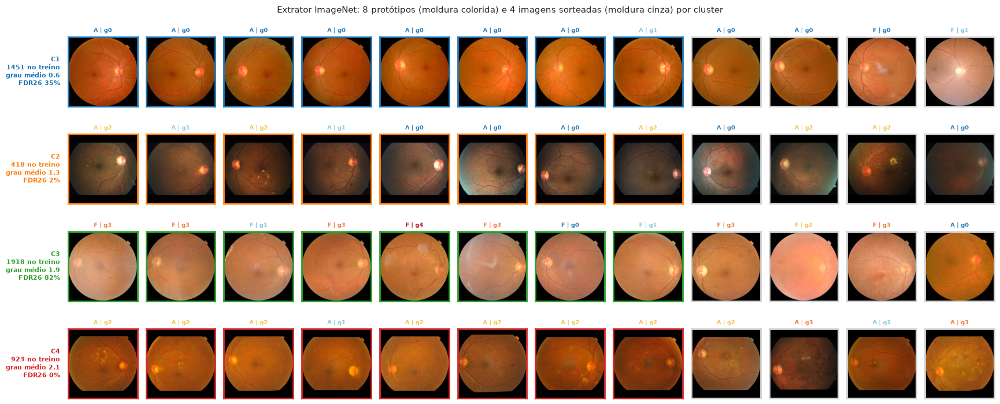

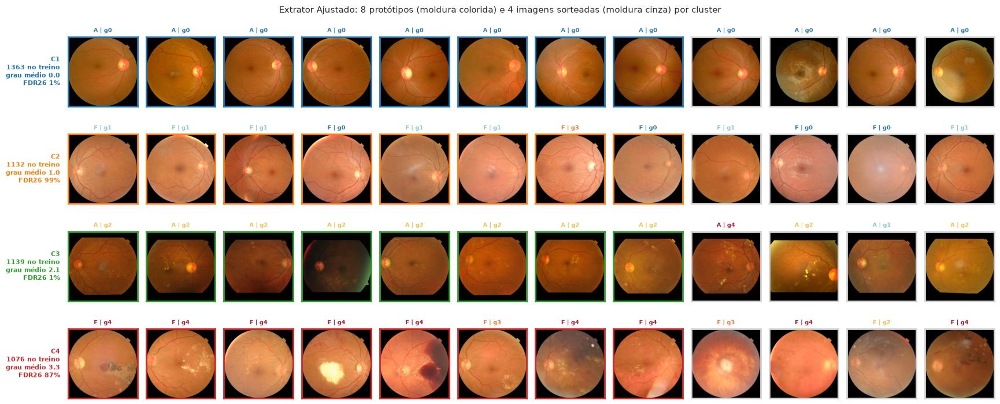

In [56]:
def mosaico(X, Z, particao, catalogo, idx_treino, centrais=8, sorteadas=4, semente=CFG.semente):
    rng = np.random.default_rng(semente)
    colunas = centrais + sorteadas
    fig, eixos = plt.subplots(particao.k, colunas, figsize=(1.45 * colunas, 1.75 * particao.k), squeeze=False)
    rotulos_treino = particao.rotulos[idx_treino]
    for r in range(particao.k):
        membros = idx_treino[rotulos_treino == r]
        distancias = np.linalg.norm(Z[membros] - particao.centros[r], axis=1)
        prototipos = membros[np.argsort(distancias)[:centrais]]
        outros = rng.choice(np.setdiff1d(membros, prototipos), min(sorteadas, len(membros) - len(prototipos)), replace=False)
        for j, indice in enumerate([*prototipos, *outros]):
            eixo = eixos[r, j]
            linha = catalogo.iloc[indice]
            eixo.imshow(X[indice])
            eixo.set_title(f"{linha['dataset'][0]} | g{linha['grau']}", fontsize=7, color=CORES_GRAU[linha["grau"]])
            eixo.set_xticks([])
            eixo.set_yticks([])
            for lado in eixo.spines.values():
                lado.set_visible(True)
                lado.set_color(PALETA_CLUSTERS[r] if j < centrais else "lightgray")
                lado.set_linewidth(2)
        parte = catalogo.iloc[membros]
        eixos[r, 0].set_ylabel(f"{nome_cluster(r)}\n{len(membros)} no treino\ngrau médio {parte['grau'].mean():.1f}\nFDR26 {100 * (parte['dataset'] == 'FDR26').mean():.0f}%", rotation=0, ha="right", va="center", fontsize=8, color=PALETA_CLUSTERS[r], weight="bold", labelpad=10)
    fig.tight_layout()
    return fig


for nome in EXTRATORES:
    figura = mosaico(X_IMAGENS, Z[nome], PARTICOES[nome], CATALOGO, IDX_TREINO)
    figura.suptitle(f"Extrator {nome}: 8 protótipos (moldura colorida) e 4 imagens sorteadas (moldura cinza) por cluster", y=1.02, fontsize=11)
    salvar_figura(figura, f"10_mosaico_{nome.lower()}")

Os mosaicos tornam os clusters concretos.

Extrator Ajustado: C1 são retinas do APTOS, alaranjadas, limpas e nítidas, todas de grau 0. C2 são retinas do FDR26, claras e rosadas, de graus 0 e 1, quase sem lesão visível. C3 são retinas do APTOS com exsudatos amarelos espalhados, grau 2 na maioria. C4 são retinas do FDR26 com lesões evidentes: exsudatos extensos, hemorragias grandes e fibrose, grau 4 na maioria. Os protótipos são clinicamente coerentes.

Extrator ImageNet: os clusters são descritos melhor pela aparência da foto do que pela doença. C2 reúne fotos do APTOS escuras, esverdeadas, com o círculo cortado em cima e embaixo, de uma câmera específica, misturando graus 0 a 2. C3 reúne as fotos claras do FDR26, com todos os graus. C1 e C4 são fotos alaranjadas do APTOS, e o que distingue C4 é a presença de exsudatos e o formato do campo de visão.

## 11. Estatísticas das imagens e dos clusters

A partir daqui analisamos todas as imagens, de treino e de teste, cada uma com o seu cluster. A pergunta é: o que distingue um cluster do outro?

### 11.1 Estatísticas de cada cluster

| Coluna | O que diz |
|---|---|
| imagens, % do total | tamanho do cluster |
| distância média ao centro | coesão: quanto menor, mais compacto |
| silhouette média | separação: perto de 1 é nítido, perto de 0 é fronteira, negativo é mistura |
| grau médio, % referável | o conteúdo clínico do cluster |
| % FDR26 | a composição por base |
| % treino / % teste | se o cluster tem o mesmo peso nos dois conjuntos |

In [57]:
def estatisticas_dos_clusters(Z, particao, catalogo):
    silhouettes = silhouette_samples(Z, particao.rotulos)
    linhas = []
    for r in range(particao.k):
        membros = particao.rotulos == r
        parte = catalogo[membros]
        linhas.append({
            "cluster": nome_cluster(r),
            "imagens": int(membros.sum()),
            "% do total": 100 * membros.mean(),
            "distância média ao centro": np.linalg.norm(Z[membros] - particao.centros[r], axis=1).mean(),
            "silhouette média": silhouettes[membros].mean(),
            "grau médio": parte["grau"].mean(),
            "% referável": 100 * parte["referavel"].mean(),
            "% FDR26": 100 * (parte["dataset"] == "FDR26").mean(),
            "% do treino": 100 * (parte["conjunto"] == "treino").sum() / (catalogo["conjunto"] == "treino").sum(),
            "% do teste": 100 * (parte["conjunto"] == "teste").sum() / (catalogo["conjunto"] == "teste").sum(),
        })
    return pd.DataFrame(linhas).set_index("cluster")


TAB_CLUSTERS = {nome: estatisticas_dos_clusters(Z[nome], PARTICOES[nome], CATALOGO) for nome in EXTRATORES}
for nome in EXTRATORES:
    display(TAB_CLUSTERS[nome].round(2).style.set_caption(f"Extrator {nome} (K = {K})").background_gradient(subset=["grau médio", "% FDR26"], cmap="RdYlBu_r"))

,imagens,% do total,distância média ao centro,silhouette média,grau médio,% referável,% FDR26,% do treino,% do teste
cluster,,,,,,,,,
C1,1973,31.410000,21.850000,0.180000,0.630000,18.600000,35.020000,30.810000,33.230000
C2,576,9.170000,24.850000,0.130000,1.350000,50.520000,1.740000,8.870000,10.060000
C3,2516,40.060000,22.700001,0.130000,1.930000,57.630000,82.350000,40.720000,38.060000
C4,1216,19.360000,23.360001,0.140000,2.130000,75.990000,0.330000,19.600000,18.650000


,imagens,% do total,distância média ao centro,silhouette média,grau médio,% referável,% FDR26,% do treino,% do teste
cluster,,,,,,,,,
C1,1829,29.120000,18.910000,0.270000,0.040000,1.260000,1.260000,28.940000,29.660000
C2,1524,24.260000,22.219999,0.120000,1.050000,28.870000,98.690000,24.030000,24.950000
C3,1516,24.140000,20.090000,0.190000,2.060000,78.560000,0.790000,24.180000,24.000000
C4,1412,22.480000,21.700001,0.150000,3.290000,97.590000,87.680000,22.850000,21.390000


### 11.2 Composição dos clusters

Distribuição dos graus e das bases dentro de cada cluster. O V de Cramér [35], de 0 a 1, resume a associação entre o cluster e cada variável.

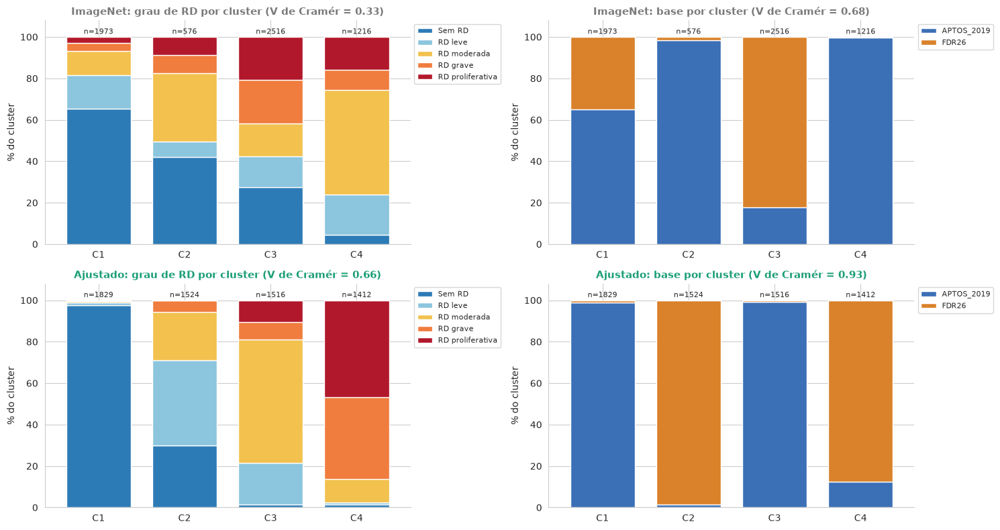

,ImageNet,Ajustado
V de Cramér cluster × grau,0.330,0.659
V de Cramér cluster × referável,0.430,0.776
V de Cramér cluster × base,0.682,0.931


In [58]:
def plotar_composicao(particoes, catalogo):
    fig, eixos = plt.subplots(2, 2, figsize=(15, 8))
    for linha, nome in zip(eixos, EXTRATORES):
        rotulos = pd.Series(particoes[nome].rotulos).map(nome_cluster)
        for eixo, coluna, cores, legenda in ((linha[0], "grau", CORES_GRAU, NOMES_GRAUS), (linha[1], "dataset", CORES_BASE, None)):
            composicao = pd.crosstab(rotulos, catalogo[coluna].to_numpy(), normalize="index") * 100
            composicao.plot(kind="bar", stacked=True, color=[cores[c] for c in composicao.columns], ax=eixo, rot=0, width=0.75)
            for i, total in enumerate(rotulos.value_counts().sort_index()):
                eixo.text(i, 101.5, f"n={total}", ha="center", fontsize=8)
            eixo.set_ylim(0, 108)
            eixo.set_ylabel("% do cluster")
            eixo.set_xlabel("")
            eixo.set_title(f"{nome}: {'grau de RD' if coluna == 'grau' else 'base'} por cluster (V de Cramér = {cramer_v(rotulos, catalogo[coluna]):.2f})", color=CORES_EXTRATOR[nome])
            handles, textos = eixo.get_legend_handles_labels()
            eixo.legend(handles, [legenda[int(t)] if legenda else t for t in textos], fontsize=8, bbox_to_anchor=(1.0, 1.0), loc="upper left")
    fig.tight_layout()
    return fig


salvar_figura(plotar_composicao(PARTICOES, CATALOGO), "11_composicao_clusters")

pd.DataFrame({
    nome: {
        "V de Cramér cluster × grau": cramer_v(PARTICOES[nome].rotulos, CATALOGO["grau"]),
        "V de Cramér cluster × referável": cramer_v(PARTICOES[nome].rotulos, CATALOGO["referavel"]),
        "V de Cramér cluster × base": cramer_v(PARTICOES[nome].rotulos, CATALOGO["dataset"]),
    }
    for nome in EXTRATORES
}).round(3)

Com o extrator Ajustado, cada cluster é praticamente de uma base só (V de Cramér cluster × base = 0,93) e tem um perfil de gravidade bem definido (V × grau = 0,66; V × referável = 0,78). Só no teste, onde a rede não foi treinada, os valores são parecidos: 0,94 com a base, 0,63 com o grau e 0,75 com a RD referável:

| Cluster | Base | Conteúdo |
|---|---|---|
| C1 | APTOS (99%) | 97% sem RD, grau médio 0,04 |
| C2 | FDR26 (99%) | graus 0 e 1 (71%), 29% referável |
| C3 | APTOS (99%) | 60% RD moderada, 79% referável |
| C4 | FDR26 (88%) | graus 3 e 4 (86%), 98% referável |

A partição é o cruzamento de duas perguntas: de qual base veio a imagem, e se ela é menos ou mais grave. O extrator ajustado aprendeu a doença, mas não esqueceu a origem.

Com o ImageNet, a base também domina (V = 0,68), mas a gravidade quase não aparece (V × grau = 0,33). C3 mistura 82% de FDR26 com todos os graus, e só C4, 100% APTOS, concentra RD referável (76%).

### 11.3 Quais medidas das imagens diferem entre os clusters?

Para cada medida da Seção 4, o teste de Kruskal-Wallis [33] verifica se a distribuição muda de um cluster para outro, sem supor normalidade. O valor-p tem correção de Bonferroni pelos vários testes. O tamanho de efeito η² [34] é o que importa: abaixo de 0,01 é desprezível, a partir de 0,06 é médio e a partir de 0,14 é grande. Os testes tratam cada imagem como independente, mas no FDR26 um paciente pode ter até 8 imagens, o que deixa os valores-p ainda mais otimistas.

In [59]:
TAB_TESTES = {nome: testar_medidas(CATALOGO, PARTICOES[nome].rotulos, COLUNAS_MEDIDAS) for nome in EXTRATORES}
TAB_TESTES_LADO_A_LADO = pd.concat({nome: TAB_TESTES[nome].set_index("medida")[["eta2", "p_bonferroni"]] for nome in EXTRATORES}, axis=1)
TAB_TESTES_LADO_A_LADO[("", "efeito ImageNet")] = TAB_TESTES_LADO_A_LADO[("ImageNet", "eta2")].map(magnitude)
TAB_TESTES_LADO_A_LADO[("", "efeito Ajustado")] = TAB_TESTES_LADO_A_LADO[("Ajustado", "eta2")].map(magnitude)
TAB_TESTES_LADO_A_LADO.sort_values(("Ajustado", "eta2"), ascending=False).round(4)

ImageNet              Ajustado                               \
                    eta2 p_bonferroni     eta2 p_bonferroni efeito ImageNet   
medida                                                                        
media_B           0.3031          0.0   0.6178          0.0          grande   
media_G           0.4391          0.0   0.5468          0.0          grande   
brilho_L          0.4530          0.0   0.5124          0.0          grande   
altura            0.1011          0.0   0.4841          0.0           média   
tamanho_mb        0.5366          0.0   0.4751          0.0          grande   
fov_ocupacao      0.6927          0.0   0.4494          0.0          grande   
media_R           0.4228          0.0   0.4025          0.0          grande   
saturacao         0.3201          0.0   0.3717          0.0          grande   
largura           0.1891          0.0   0.3057          0.0          grande   
densidade_vasos   0.1260          0.0   0.2395          0.0           média   
nitidez_lap       0.2281          0.0   0.2198          0.0          grande   
frac_claro        0.1858          0.0   0.2067          0.0          grande   
dens_escuras      0.2067          0.0   0.1203          0.0          grande   
entropia          0.1620          0.0   0.1090          0.0          grande   
area_util_rel     0.2982          0.0   0.1076          0.0          grande   
frac_escuro       0.2631          0.0   0.0940          0.0          grande   
contraste_L       0.2060          0.0   0.0845          0.0          grande   
dens_claras       0.0886          0.0   0.0229          0.0           média   

                                 
                efeito Ajustado  
medida                           
media_B                  grande  
media_G                  grande  
brilho_L                 grande  
altura                   grande  
tamanho_mb               grande  
fov_ocupacao             grande  
media_R                  grande  
saturacao                grande  
largura                  grande  
densidade_vasos          grande  
nitidez_lap              grande  
frac_claro               grande  
dens_escuras              média  
entropia                  média  
area_util_rel             média  
frac_escuro               média  
contraste_L               média  
dens_claras             pequena

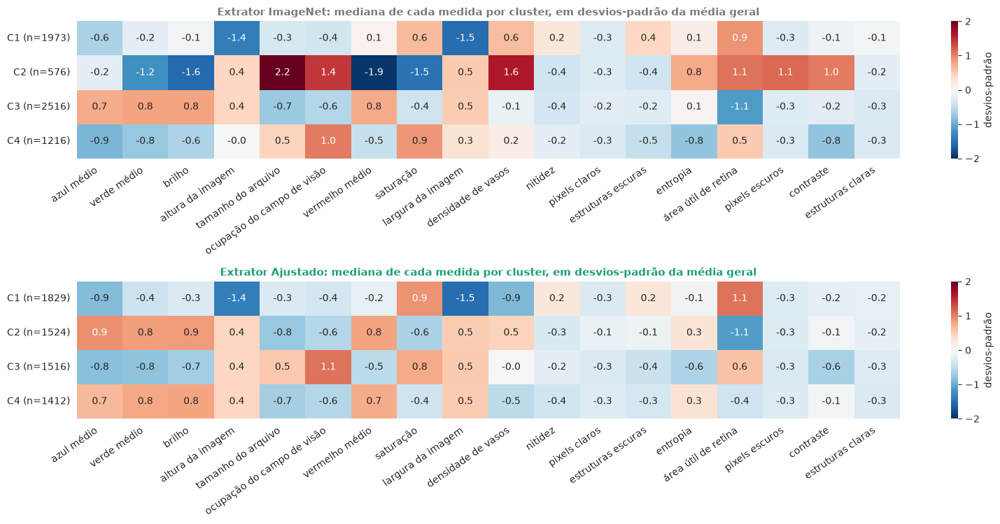

In [60]:
def plotar_heatmap_medianas(particoes, catalogo, colunas):
    fig, eixos = plt.subplots(2, 1, figsize=(16, 2 * (1.6 + 0.55 * K)))
    for eixo, nome in zip(eixos, EXTRATORES):
        rotulos = particoes[nome].rotulos
        medianas = catalogo.groupby(rotulos)[colunas].median()
        padronizadas = (medianas - catalogo[colunas].mean()) / catalogo[colunas].std()
        padronizadas.index = [f"{nome_cluster(r)} (n={(rotulos == r).sum()})" for r in padronizadas.index]
        padronizadas.columns = [NOMES_LEGIVEIS[c] for c in colunas]
        sns.heatmap(padronizadas, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, cbar_kws={"label": "desvios-padrão"}, ax=eixo)
        eixo.set_title(f"Extrator {nome}: mediana de cada medida por cluster, em desvios-padrão da média geral", color=CORES_EXTRATOR[nome])
        eixo.tick_params(axis="x", rotation=35)
        for texto in eixo.get_xticklabels():
            texto.set_ha("right")
    fig.tight_layout()
    return fig


ORDEM_MEDIDAS = TAB_TESTES["Ajustado"]["medida"].tolist()
salvar_figura(plotar_heatmap_medianas(PARTICOES, CATALOGO, ORDEM_MEDIDAS), "11_heatmap_medidas")

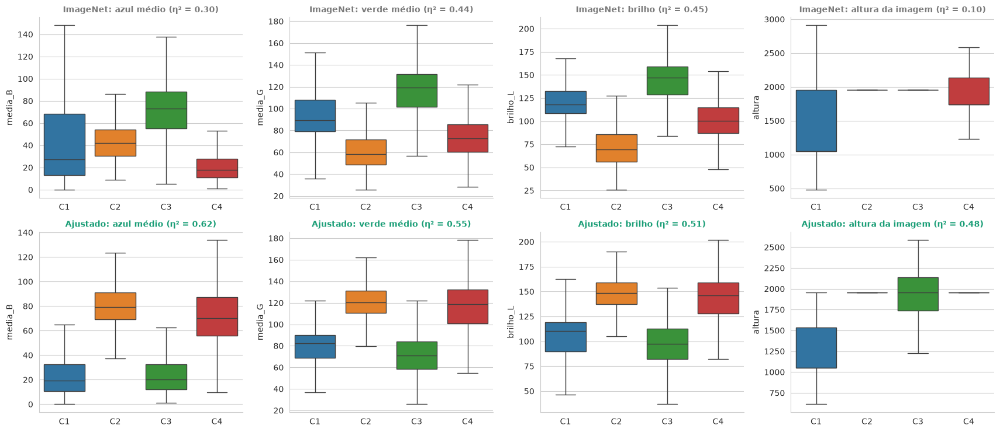

In [61]:
def plotar_distribuicoes(particoes, catalogo, colunas):
    fig, eixos = plt.subplots(2, len(colunas), figsize=(4.3 * len(colunas), 7.5))
    for linha, nome in zip(eixos, EXTRATORES):
        nomes = pd.Series(particoes[nome].rotulos).map(nome_cluster).to_numpy()
        ordem = sorted(set(nomes))
        for eixo, coluna in zip(linha, colunas):
            sns.boxplot(x=nomes, y=catalogo[coluna].to_numpy(), order=ordem, hue=nomes, hue_order=ordem, palette=dict(zip(ordem, PALETA_CLUSTERS)), legend=False, showfliers=False, ax=eixo)
            eta2 = TAB_TESTES[nome].set_index("medida").loc[coluna, "eta2"]
            eixo.set_title(f"{nome}: {NOMES_LEGIVEIS[coluna]} (η² = {eta2:.2f})", color=CORES_EXTRATOR[nome], fontsize=10)
            eixo.set_ylabel(coluna)
    fig.tight_layout()
    return fig


salvar_figura(plotar_distribuicoes(PARTICOES, CATALOGO, ORDEM_MEDIDAS[:4]), "11_distribuicoes_medidas")

Todas as medidas diferem entre os clusters (p corrigido < 0,05), o que é esperado com milhares de imagens. O tamanho de efeito mostra o que importa.

No Ajustado, as medidas que mais separam os clusters são de cor e brilho (azul médio, η² = 0,62; verde, 0,55; brilho, 0,51) e de resolução (altura, 0,48). Isso não quer dizer que a rede usa a cor para classificar a doença, e sim que os clusters estão divididos por base, e as bases diferem na cor (Seção 4.2). Mais revelador é a altura: C1 (APTOS sem RD) tem imagens pequenas, e C3 (APTOS doente) tem imagens grandes, o mesmo atalho de resolução da Seção 4.4. Mesmo depois do recorte e da redução para 224 pixels, a resolução original deixa marca no que a rede vê.

No ImageNet, a medida mais discriminante é a ocupação do campo de visão (η² = 0,69), seguida do tamanho do arquivo (0,54). C2 tem os maiores desvios do heatmap: campo de visão cortado, arquivos grandes, pouco vermelho e pouco brilho. São características de câmera, e não de retina.

As medidas morfológicas de lesão (estruturas escuras e claras) têm efeito médio ou pequeno nos dois extratores. A densidade de vasos tem efeito grande no Ajustado (0,24), porque separa C2 (FDR26 leve, mais vasos detectados) de C4 (FDR26 grave, menos vasos).

### 11.4 Perfil clínico dos clusters no FDR26

Só o FDR26 tem idade, sexo, tipo de diabetes e máscara de vasos. A tabela compara essas variáveis entre os clusters, usando apenas as imagens do FDR26.

In [62]:
def perfil_clinico(particao, catalogo):
    fdr = catalogo["dataset"] == "FDR26"
    parte = catalogo[fdr].assign(cluster=pd.Series(particao.rotulos[fdr.to_numpy()]).map(nome_cluster).to_numpy())
    tabela = parte.groupby("cluster").agg(
        imagens=("arquivo", "size"),
        idade_media=("idade", "mean"),
        pct_masculino=("sexe", lambda s: 100 * (s == "M").mean()),
        pct_diabetes_tipo_1=("tipo_diabete", lambda s: 100 * (s == 1).mean()),
        densidade_vasos_mediana=("densidade_vasos", "median"),
        grau_medio=("grau", "mean"),
    )
    _, p_idade = stats.kruskal(*[g["idade"].to_numpy() for _, g in parte.groupby("cluster") if len(g) > 1])
    testes = {"p idade (Kruskal-Wallis)": p_idade, "V de Cramér cluster × sexo": cramer_v(parte["cluster"], parte["sexe"]), "V de Cramér cluster × tipo de diabetes": cramer_v(parte["cluster"], parte["tipo_diabete"])}
    return tabela, testes


for nome in EXTRATORES:
    tabela, testes = perfil_clinico(PARTICOES[nome], CATALOGO)
    display(tabela.round(2).style.set_caption(f"Extrator {nome}: imagens do FDR26 por cluster"))
    print(" | ".join(f"{k}: {v:.3g}" for k, v in testes.items()))

,imagens,idade_media,pct_masculino,pct_diabetes_tipo_1,densidade_vasos_mediana,grau_medio
cluster,,,,,,
C1,691,60.300000,48.340000,7.240000,0.110000,1.230000
C2,10,59.600000,30.000000,10.000000,0.150000,1.600000
C3,2072,62.060000,49.180000,6.710000,0.090000,2.310000
C4,4,70.250000,50.000000,0.000000,0.100000,3.500000


p idade (Kruskal-Wallis): 0.000891 | V de Cramér cluster × sexo: 0.0239 | V de Cramér cluster × tipo de diabetes: 0.0156


,imagens,idade_media,pct_masculino,pct_diabetes_tipo_1,densidade_vasos_mediana,grau_medio
cluster,,,,,,
C1,23,60.520000,43.480000,4.350000,0.060000,0.780000
C2,1504,60.350000,48.940000,7.250000,0.110000,1.050000
C3,12,61.830000,50.000000,8.330000,0.090000,2.080000
C4,1238,63.190000,48.950000,6.380000,0.070000,3.250000


p idade (Kruskal-Wallis): 1.46e-10 | V de Cramér cluster × sexo: 0.01 | V de Cramér cluster × tipo de diabetes: 0.0196


Dentro do FDR26, o extrator Ajustado coloca 1.504 imagens em C2 e 1.238 em C4, e só 35 em C1 e C3. De C2 para C4, a idade média sobe de 60,4 para 63,2 anos e a densidade de vasos cai de 0,11 para 0,07, acompanhando o grau médio (1,05 contra 3,25). A diferença de idade entre clusters é significativa (p = 1,5 × 10⁻¹⁰, otimista porque várias imagens são do mesmo paciente), mas pequena em anos, e repete a correlação fraca entre idade e grau da Seção 1.5. Sexo e tipo de diabetes não têm associação com o cluster (V de Cramér ≤ 0,02). Os clusters não separam grupos demográficos: separam gravidade.

No ImageNet, 2.072 imagens do FDR26 caem em C3 e 691 em C1, com grau médio de 2,31 e 1,23. Há alguma ordem de gravidade, mas bem mais fraca.

### 11.5 O perfil de cada cluster em palavras

A célula abaixo traduz as tabelas em frases. dp quer dizer desvios-padrão em relação à média de todas as imagens: +1,0 dp significa que a mediana do cluster está um desvio-padrão acima da média geral.

In [63]:
def descrever_clusters(particao, catalogo, colunas, destaques=3):
    padronizado = (catalogo[colunas] - catalogo[colunas].mean()) / catalogo[colunas].std()
    frases = []
    for r in range(particao.k):
        membros = particao.rotulos == r
        desvios = padronizado[membros].median().dropna()
        principais = desvios.reindex(desvios.abs().sort_values(ascending=False).index).head(destaques)
        tracos = ", ".join(f"{NOMES_LEGIVEIS[c]} {'acima' if v > 0 else 'abaixo'} da média ({v:+.1f} dp)" for c, v in principais.items())
        parte = catalogo[membros]
        bases = parte["dataset"].value_counts(normalize=True)
        frases.append(
            f"- {nome_cluster(r)} ({membros.sum()} imagens): {tracos}. "
            f"Predomina {bases.index[0]} ({100 * bases.iloc[0]:.0f}%). Grau médio {parte['grau'].mean():.1f}, com {100 * parte['referavel'].mean():.0f}% de RD referável."
        )
    return "\n".join(frases)


for nome in EXTRATORES:
    display(Markdown(f"Extrator {nome}\n\n" + descrever_clusters(PARTICOES[nome], CATALOGO, [c for c in COLUNAS_MEDIDAS if c != "densidade_vasos"])))

Extrator ImageNet

- C1 (1973 imagens): largura da imagem abaixo da média (-1.5 dp), altura da imagem abaixo da média (-1.4 dp), área útil de retina acima da média (+0.9 dp). Predomina APTOS_2019 (65%). Grau médio 0.6, com 19% de RD referável.
- C2 (576 imagens): tamanho do arquivo acima da média (+2.2 dp), vermelho médio abaixo da média (-1.9 dp), brilho abaixo da média (-1.6 dp). Predomina APTOS_2019 (98%). Grau médio 1.3, com 51% de RD referável.
- C3 (2516 imagens): área útil de retina abaixo da média (-1.1 dp), brilho acima da média (+0.8 dp), verde médio acima da média (+0.8 dp). Predomina FDR26 (82%). Grau médio 1.9, com 58% de RD referável.
- C4 (1216 imagens): ocupação do campo de visão acima da média (+1.0 dp), azul médio abaixo da média (-0.9 dp), saturação acima da média (+0.9 dp). Predomina APTOS_2019 (100%). Grau médio 2.1, com 76% de RD referável.

Extrator Ajustado

- C1 (1829 imagens): largura da imagem abaixo da média (-1.5 dp), altura da imagem abaixo da média (-1.4 dp), área útil de retina acima da média (+1.1 dp). Predomina APTOS_2019 (99%). Grau médio 0.0, com 1% de RD referável.
- C2 (1524 imagens): área útil de retina abaixo da média (-1.1 dp), azul médio acima da média (+0.9 dp), brilho acima da média (+0.9 dp). Predomina FDR26 (99%). Grau médio 1.0, com 29% de RD referável.
- C3 (1516 imagens): ocupação do campo de visão acima da média (+1.1 dp), azul médio abaixo da média (-0.8 dp), verde médio abaixo da média (-0.8 dp). Predomina APTOS_2019 (99%). Grau médio 2.1, com 79% de RD referável.
- C4 (1412 imagens): brilho acima da média (+0.8 dp), verde médio acima da média (+0.8 dp), vermelho médio acima da média (+0.7 dp). Predomina FDR26 (88%). Grau médio 3.3, com 98% de RD referável.

### 11.6 E se mudarmos o K?

A tabela junta, para cada K, a qualidade interna (silhouette e estabilidade), a relação com os rótulos no teste (ARI × grau e × base) e o quanto as medidas das imagens diferem entre os clusters (η² médio). Ela ajuda a defender a escolha do K.

In [64]:
def resumo_por_k(nome):
    linhas = []
    for k in CFG.lista_k:
        particao = montar_particao(MODELOS_K[nome][k], Z[nome], IDX_TREINO, Y_GRAU)
        testes = testar_medidas(CATALOGO, particao.rotulos, COLUNAS_MEDIDAS)
        linhas.append({"k": k, "eta2_medio": testes["eta2"].mean(), "medida_mais_discriminante": testes["medida"].iloc[0], "eta2_maximo": testes["eta2"].iloc[0]})
    return TAB_K[nome][["k", "silhouette", "estabilidade", "ARI_grau", "ARI_base"]].merge(pd.DataFrame(linhas), on="k")


TAB_RESUMO_K = pd.concat({nome: resumo_por_k(nome) for nome in EXTRATORES}, names=["extrator"]).reset_index(level=0)
TAB_RESUMO_K.set_index(["extrator", "k"]).round(3)

silhouette  estabilidade  ARI_grau  ARI_base  eta2_medio  \
extrator k                                                             
ImageNet 2       0.121         0.967     0.096     0.009       0.060   
         3       0.137         0.985     0.113     0.299       0.222   
         4       0.146         0.864     0.120     0.233       0.290   
         5       0.144         0.736     0.128     0.317       0.369   
         6       0.137         0.930     0.157     0.238       0.408   
         7       0.142         0.946     0.155     0.269       0.467   
         8       0.152         0.852     0.159     0.267       0.506   
Ajustado 2       0.154         0.973     0.322     0.017       0.043   
         3       0.170         0.862     0.338     0.271       0.177   
         4       0.187         0.989     0.415     0.442       0.298   
         5       0.170         0.876     0.279     0.354       0.340   
         6       0.170         0.842     0.290     0.323       0.355   
         7       0.173         0.750     0.318     0.300       0.391   
         8       0.191         0.812     0.245     0.287       0.458   

           medida_mais_discriminante  eta2_maximo  
extrator k                                         
ImageNet 2              dens_escuras        0.213  
         3              fov_ocupacao        0.656  
         4              fov_ocupacao        0.693  
         5              fov_ocupacao        0.699  
         6              fov_ocupacao        0.710  
         7              fov_ocupacao        0.726  
         8              fov_ocupacao        0.756  
Ajustado 2                    altura        0.204  
         3                    altura        0.475  
         4                   media_B        0.618  
         5                   media_B        0.617  
         6                   media_B        0.632  
         7                   media_B        0.695  
         8              fov_ocupacao        0.774

In [65]:
def salvar_resultados():
    rotulos = {f"cluster_{nome.lower()}": pd.Series(PARTICOES[nome].rotulos).map(nome_cluster).to_numpy() for nome in EXTRATORES}
    CATALOGO.assign(**rotulos).drop(columns=["caminho"]).to_csv(CAMINHOS.saida / "imagens_com_cluster.csv", index=False)
    TAB_K_TODOS.to_csv(CAMINHOS.saida / "metricas_por_k.csv", index=False)
    TAB_RESUMO_K.to_csv(CAMINHOS.saida / "resumo_por_k.csv", index=False)
    TAB_TESTE.to_csv(CAMINHOS.saida / "desempenho_extrator_ajustado_teste.csv")
    for nome in EXTRATORES:
        np.save(CAMINHOS.saida / f"matriz_caracteristicas_{nome.lower()}.npy", E[nome])
        TAB_CLUSTERS[nome].to_csv(CAMINHOS.saida / f"estatisticas_clusters_{nome.lower()}.csv")
        TAB_TESTES[nome].to_csv(CAMINHOS.saida / f"testes_medidas_clusters_{nome.lower()}.csv", index=False)
    CATALOGO[["dataset", "arquivo", "grau", "referavel", "conjunto"]].to_csv(CAMINHOS.saida / "indice_linhas_da_matriz.csv", index_label="linha")
    return sorted(p.name for p in CAMINHOS.saida.iterdir() if p.is_file())


print("Arquivos salvos em", CAMINHOS.saida)
salvar_resultados()

Arquivos salvos em /home/ari/dr-statistical-analysis/results/clustering


['desempenho_extrator_ajustado_teste.csv',
 'estatisticas_clusters_ajustado.csv',
 'estatisticas_clusters_imagenet.csv',
 'imagens_com_cluster.csv',
 'indice_linhas_da_matriz.csv',
 'matriz_caracteristicas_ajustado.npy',
 'matriz_caracteristicas_imagenet.npy',
 'metricas_por_k.csv',
 'resumo_por_k.csv',
 'testes_medidas_clusters_ajustado.csv',
 'testes_medidas_clusters_imagenet.csv']

## 12. Conclusões

### O que foi feito

| Pedido | Resultado |
|---|---|
| Extrator leve | MobileNetV3-Small em duas versões: só com pesos da ImageNet (2,5 milhões de parâmetros) e ajustada nas imagens de retina (1,5 milhão) |
| Embeddings da última camada escondida | camada de 1.024 neurônios que antecede a classificação |
| Matriz de características | 6.281 imagens × 1.024 dimensões por extrator, salva em results/clustering |
| Clusterização | K-Means, mistura de gaussianas, Ward e HDBSCAN |
| Diferentes K | K de 2 a 8, com indicadores internos, externos e de estabilidade; K = 4 na análise detalhada |
| Estatísticas | 18 medidas de imagem, composição dos clusters, perfil clínico e testes com tamanho de efeito |

### Principais achados

1. As duas bases diferem nas imagens, e não na doença. Cor, brilho, resolução e compressão separam APTOS e FDR26 com efeito grande (η² até 0,69), enquanto as medidas de lesão quase não diferem entre elas.
2. Sem ajuste, o extrator leve agrupa por aquisição. Os clusters do extrator ImageNet seguem base e câmera (V de Cramér × base = 0,68; medida mais discriminante: ocupação do campo de visão) e quase não seguem a doença (ARI × grau no teste = 0,12).
3. Com ajuste fino, os clusters ganham sentido clínico. O extrator Ajustado produz, com K = 4, clusters estáveis (0,99), concordantes entre algoritmos (ARI de 0,84 a 0,88) e associados ao grau (no teste, ARI × grau = 0,42 e V de Cramér × RD referável = 0,75).
4. Mesmo ajustado, o extrator não esquece a base. Com K = 4, a partição é o cruzamento de base com gravidade: APTOS saudável, APTOS doente, FDR26 leve e FDR26 grave.
5. O APTOS tem um atalho de aquisição. A resolução da foto está fortemente associada à RD referável (V de Cramér = 0,74): as 351 fotos de 2.048 × 1.536 são todas sem RD, e 96% das 374 fotos de 3.216 × 2.136 são referáveis. O cluster do APTOS saudável é também o das fotos pequenas. Uma parte do que parece aprendizado de doença pode ser aprendizado de câmera [13,14].
6. As duas bases têm cópias com rótulos conflitantes. No FDR26, achado novo deste notebook, 62 pares de imagens idênticas têm graus diferentes, e 81 pares estão registrados como pacientes diferentes.

### O que isso significa para o roteador

A ideia do projeto é usar um extrator leve como roteador, dividir o espaço de características em regiões com o K-Means e escolher o melhor modelo para cada região [15,16]. Com APTOS e FDR26 juntos, as regiões encontradas são primeiro de base e depois de gravidade. Um roteador treinado nesses dados escolheria, na prática, um modelo por base e por faixa de gravidade. Isso pode ser útil, porque modelos especializados por domínio tendem a ir melhor no próprio domínio, mas exige cuidado: uma imagem de uma terceira câmera pode cair em uma região sem relação com a doença.

### Limitações

- Duas bases apenas, nenhuma com identificação de câmera. O efeito de câmera é inferido pela resolução e pela aparência.
- A equivalência entre ALFEDIAM e ICDR é aproximada, e graus vizinhos do FDR26 são difíceis até para a rede ajustada.
- O ajuste fino usa rótulos, e por isso os clusters do extrator Ajustado não são totalmente não supervisionados. Os indicadores externos foram medidos no teste, em imagens não vistas, para reduzir esse viés.
- Imagens de 224 pixels perdem microaneurismas, o sinal da RD leve.
- O APTOS não identifica pacientes, e o FDR26 tem identificadores inconsistentes em parte das cópias. A divisão por paciente é a melhor possível com os metadados disponíveis.
- As máscaras de vasos do FDR26 falham em imagens com lesões extensas, e a densidade de vasos deve ser lida com cautela.
- Com milhares de imagens, os valores-p são sempre minúsculos. As conclusões se apoiam nos tamanhos de efeito e na concordância entre K, algoritmos e extratores.
- Os testes tratam cada imagem como independente, mas no FDR26 um paciente pode ter até 8 imagens, o que torna os valores-p ainda mais otimistas.
- O K = 4 foi escolhido olhando também o ARI contra o grau no teste, e por isso não é uma escolha cega aos rótulos.
- Os clusters foram ajustados na matriz depois da normalização, da padronização e do PCA com 50 componentes (Seção 7.3), e não na matriz bruta de 1.024 colunas.
- UMAP e mosaicos são ilustrativos, e distâncias no mapa não devem ser lidas ao pé da letra.

### Próximos passos

1. Implementar o conjunto de modelos L e escolher o melhor modelo por região (clustering-and-selection [15]), comparando com um modelo único.
2. Testar normalização de cor e de resolução antes do extrator, para reduzir o peso da base nos clusters.
3. Incluir uma terceira base de RD, de outra câmera, como teste externo, para ver para onde o roteador manda imagens de um domínio novo.
4. Comparar com um modelo de fundação de retina, como o RETFound [6], para medir quanto do resultado depende do extrator leve.
5. Reportar aos mantenedores do FDR26 os pares duplicados com graus e pacientes conflitantes.

## 13. Referências

1. Wilkinson CP, Ferris FL 3rd, Klein RE, Lee PP, Agardh CD, Davis M, et al. Proposed international clinical diabetic retinopathy and diabetic macular edema disease severity scales. Ophthalmology. 2003;110(9):1677-82. doi:10.1016/S0161-6420(03)00475-5
2. Gulshan V, Peng L, Coram M, Stumpe MC, Wu D, Narayanaswamy A, et al. Development and validation of a deep learning algorithm for detection of diabetic retinopathy in retinal fundus photographs. JAMA. 2016;316(22):2402-10. doi:10.1001/jama.2016.17216
3. Massin P, Feldman-Billard S. Référentiel pour le dépistage et la surveillance des complications oculaires du patient diabétique – 2016. Validé par la Société Francophone du Diabète (SFD) et par la Société Française d'Ophtalmologie (SFO). Méd Mal Métab. 2016;10(8):774-84. doi:10.1016/S1957-2557(16)30224-3
4. Karthik, Maggie, Dane S. APTOS 2019 Blindness Detection [Internet]. Kaggle; 2019 [citado 2026 nov 5]. Disponível em: https://www.kaggle.com/competitions/aptos2019-blindness-detection
5. Tymchenko B, Marchenko P, Spodarets D. Deep learning approach to diabetic retinopathy detection. In: Proceedings of the 9th International Conference on Pattern Recognition Applications and Methods (ICPRAM). Setúbal: SciTePress; 2020. p. 501-9. doi:10.5220/0008970805010509
6. Zhou Y, Chia MA, Wagner SK, Ayhan MS, Williamson DJ, Struyven RR, et al. A foundation model for generalizable disease detection from retinal images. Nature. 2023;622(7981):156-63. doi:10.1038/s41586-023-06555-x
7. Lamti S, Kerzazi N, Sekhsoukh R, Guechati A. FDR26: a dataset of fundus images for diabetic retinopathy classification and vessels segmentation [Internet]. Zenodo; 2026 [citado 2026 nov 5]. Versão 3. doi:10.5281/zenodo.23101200
8. Howard A, Sandler M, Chen B, Wang W, Chen LC, Tan M, et al. Searching for MobileNetV3. In: 2019 IEEE/CVF International Conference on Computer Vision (ICCV). Seoul: IEEE; 2019. p. 1314-24. doi:10.1109/ICCV.2019.00140
9. Tan M, Le QV. EfficientNet: rethinking model scaling for convolutional neural networks. In: Proceedings of the 36th International Conference on Machine Learning. PMLR; 2019. p. 6105-14.
10. Yosinski J, Clune J, Bengio Y, Lipson H. How transferable are features in deep neural networks? In: Advances in Neural Information Processing Systems 27 (NeurIPS 2014). Curran Associates; 2014. p. 3320-8.
11. Kornblith S, Shlens J, Le QV. Do better ImageNet models transfer better? In: 2019 IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR). Long Beach: IEEE; 2019. p. 2656-66. doi:10.1109/CVPR.2019.00277
12. Caron M, Bojanowski P, Joulin A, Douze M. Deep clustering for unsupervised learning of visual features. In: Computer Vision – ECCV 2018. Lecture Notes in Computer Science, vol 11218. Cham: Springer; 2018. p. 139-56. doi:10.1007/978-3-030-01264-9_9
13. Oakden-Rayner L, Dunnmon J, Carneiro G, Ré C. Hidden stratification causes clinically meaningful failures in machine learning for medical imaging. In: Proceedings of the ACM Conference on Health, Inference, and Learning (CHIL). New York: ACM; 2020. p. 151-9. doi:10.1145/3368555.3384468
14. Geirhos R, Jacobsen JH, Michaelis C, Zemel R, Brendel W, Bethge M, et al. Shortcut learning in deep neural networks. Nat Mach Intell. 2020;2(11):665-73. doi:10.1038/s42256-020-00257-z
15. Kuncheva LI. Clustering-and-selection model for classifier combination. In: KES'2000. Fourth International Conference on Knowledge-Based Intelligent Engineering Systems and Allied Technologies. Brighton: IEEE; 2000. v. 1, p. 185-8. doi:10.1109/KES.2000.885788
16. Jacobs RA, Jordan MI, Nowlan SJ, Hinton GE. Adaptive mixtures of local experts. Neural Comput. 1991;3(1):79-87. doi:10.1162/neco.1991.3.1.79
17. Zuiderveld K. Contrast limited adaptive histogram equalization. In: Heckbert PS, editor. Graphics Gems IV. San Diego: Academic Press; 1994. p. 474-85. doi:10.1016/B978-0-12-336156-1.50061-6
18. Paszke A, Gross S, Massa F, Lerer A, Bradbury J, Chanan G, et al. PyTorch: an imperative style, high-performance deep learning library. In: Advances in Neural Information Processing Systems 32 (NeurIPS 2019). Curran Associates; 2019. p. 8024-35.
19. Loshchilov I, Hutter F. Decoupled weight decay regularization. In: 7th International Conference on Learning Representations (ICLR 2019). New Orleans; 2019.
20. Cohen J. Weighted kappa: nominal scale agreement with provision for scaled disagreement or partial credit. Psychol Bull. 1968;70(4):213-20. doi:10.1037/h0026256
21. Jolliffe IT, Cadima J. Principal component analysis: a review and recent developments. Philos Trans A Math Phys Eng Sci. 2016;374(2065):20150202. doi:10.1098/rsta.2015.0202
22. Lloyd S. Least squares quantization in PCM. IEEE Trans Inf Theory. 1982;28(2):129-37. doi:10.1109/TIT.1982.1056489
23. Arthur D, Vassilvitskii S. k-means++: the advantages of careful seeding. In: Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms (SODA). Philadelphia: SIAM; 2007. p. 1027-35.
24. Dempster AP, Laird NM, Rubin DB. Maximum likelihood from incomplete data via the EM algorithm. J R Stat Soc Series B Stat Methodol. 1977;39(1):1-38. doi:10.1111/j.2517-6161.1977.tb01600.x
25. Ward JH Jr. Hierarchical grouping to optimize an objective function. J Am Stat Assoc. 1963;58(301):236-44. doi:10.1080/01621459.1963.10500845
26. Campello RJGB, Moulavi D, Sander J. Density-based clustering based on hierarchical density estimates. In: Advances in Knowledge Discovery and Data Mining (PAKDD 2013). Lecture Notes in Computer Science, vol 7819. Berlin: Springer; 2013. p. 160-72. doi:10.1007/978-3-642-37456-2_14
27. Rousseeuw PJ. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. J Comput Appl Math. 1987;20:53-65. doi:10.1016/0377-0427(87)90125-7
28. Davies DL, Bouldin DW. A cluster separation measure. IEEE Trans Pattern Anal Mach Intell. 1979;PAMI-1(2):224-7. doi:10.1109/TPAMI.1979.4766909
29. Caliński T, Harabasz J. A dendrite method for cluster analysis. Commun Stat. 1974;3(1):1-27. doi:10.1080/03610927408827101
30. Hubert L, Arabie P. Comparing partitions. J Classif. 1985;2(1):193-218. doi:10.1007/BF01908075
31. Vinh NX, Epps J, Bailey J. Information theoretic measures for clusterings comparison: variants, properties, normalization and correction for chance. J Mach Learn Res. 2010;11:2837-54.
32. McInnes L, Healy J, Saul N, Großberger L. UMAP: Uniform Manifold Approximation and Projection. J Open Source Softw. 2018;3(29):861. doi:10.21105/joss.00861
33. Kruskal WH, Wallis WA. Use of ranks in one-criterion variance analysis. J Am Stat Assoc. 1952;47(260):583-621. doi:10.1080/01621459.1952.10483441
34. Cohen J. Statistical power analysis for the behavioral sciences. 2nd ed. Hillsdale: Lawrence Erlbaum Associates; 1988.
35. Cramér H. Mathematical methods of statistics. Princeton: Princeton University Press; 1946.
36. Pedregosa F, Varoquaux G, Gramfort A, Michel V, Thirion B, Grisel O, et al. Scikit-learn: machine learning in Python. J Mach Learn Res. 2011;12:2825-30.